In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Project data directory
DATA_DIR = Path("../data/ehr")

# Check whether the directory exists
print("EHR directory exists:", DATA_DIR.exists())

# Display all CSV files
csv_files = sorted(DATA_DIR.glob("*.csv"))

print("Number of CSV files:", len(csv_files))

for file in csv_files:
    print(file.name)

EHR directory exists: True
Number of CSV files: 18
allergies.csv
careplans.csv
claims.csv
claims_transactions.csv
conditions.csv
devices.csv
encounters.csv
imaging_studies.csv
immunizations.csv
medications.csv
observations.csv
organizations.csv
patients.csv
payer_transitions.csv
payers.csv
procedures.csv
providers.csv
supplies.csv


In [2]:
# Load each CSV into a dictionary of DataFrames
ehr_tables = {}

for file in csv_files:
    table_name = file.stem
    ehr_tables[table_name] = pd.read_csv(file)

print("Tables loaded:", len(ehr_tables))

Tables loaded: 18


In [3]:
# Display the size of every table
for name, df in ehr_tables.items():
    print(f"{name:25} Rows: {df.shape[0]:8} | Columns: {df.shape[1]:3}")

allergies                 Rows:      105 | Columns:  15
careplans                 Rows:      349 | Columns:   9
claims                    Rows:     9421 | Columns:  31
claims_transactions       Rows:    85047 | Columns:  33
conditions                Rows:     3517 | Columns:   7
devices                   Rows:      524 | Columns:   7
encounters                Rows:     5571 | Columns:  15
imaging_studies           Rows:      478 | Columns:  13
immunizations             Rows:     1549 | Columns:   6
medications               Rows:     3850 | Columns:  13
observations              Rows:    68648 | Columns:   9
organizations             Rows:      278 | Columns:  12
patients                  Rows:      108 | Columns:  28
payer_transitions         Rows:     3815 | Columns:   8
payers                    Rows:       10 | Columns:  22
procedures                Rows:    15884 | Columns:  10
providers                 Rows:      278 | Columns:  14
supplies                  Rows:     2225 | Colum

In [4]:
ehr_tables["patients"].head()

,Id,BIRTHDATE,DEATHDATE,SSN,DRIVERS,PASSPORT,PREFIX,FIRST,MIDDLE,LAST,...,CITY,STATE,COUNTY,FIPS,ZIP,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,INCOME
0,cc3eac4a-34a7-9a15-1522-8087135631b7,1978-01-16,NaN,999-55-9547,S99974479,X81842955X,Mr.,Guillermo498,NaN,VonRueden376,...,North Brookfield,Massachusetts,Worcester County,25027.0,1535,42.267480,-72.105242,104532.20,18048.65,42283
1,8b9df7af-24b3-66ee-afeb-2734ebcbd33c,2001-02-11,NaN,999-32-1995,S99911042,X98255942X,Ms.,Jayne73,Mira443,Bruen238,...,Bedford,Massachusetts,Middlesex County,25017.0,1730,42.539821,-71.256841,98009.84,531508.43,33657
2,65cbad6a-eb9d-420e-9bab-b4f9c6aab7db,1948-06-15,NaN,999-23-9791,S99928100,X83081075X,Mrs.,Grisel924,Dortha70,Balistreri607,...,Quincy,Massachusetts,Norfolk County,25021.0,2170,42.204748,-70.988341,796732.91,219824.56,64779
3,9a3814bb-f5b0-05f3-928e-fe6640d5aa2a,2015-07-19,NaN,999-56-4831,NaN,NaN,NaN,Esperanza675,Rachell479,Auer97,...,Taunton,Massachusetts,Bristol County,25005.0,2718,41.902707,-70.976300,44050.63,17747.77,34422
4,6a703775-432b-ba7d-d53a-c4d7bb0f5b58,1995-01-23,NaN,999-91-2539,S99931120,X52632004X,Mr.,Arnulfo253,NaN,Boyer713,...,Boston,Massachusetts,Suffolk County,25025.0,2116,42.359644,-71.079948,5450.00,97459.94,6565


In [5]:
ehr_tables["observations"].head()

,DATE,PATIENT,ENCOUNTER,CATEGORY,CODE,DESCRIPTION,VALUE,UNITS,TYPE
0,2018-01-22T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,laboratory,4548-4,Hemoglobin A1c/Hemoglobin.total in Blood,6.3,%,numeric
1,2018-01-22T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,vital-signs,8302-2,Body Height,182.1,cm,numeric
2,2018-01-22T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,vital-signs,72514-3,Pain severity - 0-10 verbal numeric rating [Sc...,3.0,{score},numeric
3,2018-01-22T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,vital-signs,29463-7,Body Weight,97.6,kg,numeric
4,2018-01-22T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,vital-signs,39156-5,Body mass index (BMI) [Ratio],29.4,kg/m2,numeric


In [6]:
ehr_tables["encounters"].head()

,Id,START,STOP,PATIENT,ORGANIZATION,PROVIDER,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,cc3eac4a-34a7-9a15-13f3-57f4a6b934f9,1996-03-11T08:35:36Z,1996-03-11T09:21:33Z,cc3eac4a-34a7-9a15-1522-8087135631b7,a3327df4-d092-350b-b551-e60c82076c9a,a7db224a-b937-3e39-be28-5431d106bfdb,e03e23c9-4df1-3eb6-a62d-f70f02301496,wellness,162673000,General examination of patient (procedure),136.8,704.20,0.0,NaN,NaN
1,cc3eac4a-34a7-9a15-1dc5-a353457420c6,2006-03-27T08:35:36Z,2006-03-27T09:29:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,a3327df4-d092-350b-b551-e60c82076c9a,a7db224a-b937-3e39-be28-5431d106bfdb,734afbd6-4794-363b-9bc0-6a3981533ed5,wellness,162673000,General examination of patient (procedure),136.8,1300.91,0.0,NaN,NaN
2,cc3eac4a-34a7-9a15-94b5-26ac8c6c7134,2009-03-30T08:35:36Z,2009-03-30T09:25:14Z,cc3eac4a-34a7-9a15-1522-8087135631b7,a3327df4-d092-350b-b551-e60c82076c9a,a7db224a-b937-3e39-be28-5431d106bfdb,734afbd6-4794-363b-9bc0-6a3981533ed5,wellness,162673000,General examination of patient (procedure),136.8,1275.50,0.0,NaN,NaN
3,cc3eac4a-34a7-9a15-2a3d-1a1ba491a8ac,2012-04-02T08:35:36Z,2012-04-02T09:18:03Z,cc3eac4a-34a7-9a15-1522-8087135631b7,a3327df4-d092-350b-b551-e60c82076c9a,a7db224a-b937-3e39-be28-5431d106bfdb,0133f751-9229-3cfd-815f-b6d4979bdd6a,wellness,162673000,General examination of patient (procedure),136.8,934.74,0.0,NaN,NaN
4,cc3eac4a-34a7-9a15-99df-e3a0393fa95e,2015-04-06T08:35:36Z,2015-04-06T09:07:26Z,cc3eac4a-34a7-9a15-1522-8087135631b7,a3327df4-d092-350b-b551-e60c82076c9a,a7db224a-b937-3e39-be28-5431d106bfdb,0133f751-9229-3cfd-815f-b6d4979bdd6a,wellness,162673000,General examination of patient (procedure),136.8,860.16,0.0,NaN,NaN


In [7]:
for name in ["patients", "observations", "encounters"]:
    df = ehr_tables[name]

    print(f"\n{'=' * 60}")
    print(f"TABLE: {name}")
    print("=" * 60)

    print("Columns:")
    print(df.columns.tolist())

    print("\nFirst 3 records:")
    display(df.head(3))

    print("\nData types:")
    print(df.dtypes)


TABLE: patients
Columns:
['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX', 'FIRST', 'MIDDLE', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'FIPS', 'ZIP', 'LAT', 'LON', 'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE', 'INCOME']

First 3 records:


,Id,BIRTHDATE,DEATHDATE,SSN,DRIVERS,PASSPORT,PREFIX,FIRST,MIDDLE,LAST,...,CITY,STATE,COUNTY,FIPS,ZIP,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,INCOME
0,cc3eac4a-34a7-9a15-1522-8087135631b7,1978-01-16,NaN,999-55-9547,S99974479,X81842955X,Mr.,Guillermo498,NaN,VonRueden376,...,North Brookfield,Massachusetts,Worcester County,25027.0,1535,42.267480,-72.105242,104532.20,18048.65,42283
1,8b9df7af-24b3-66ee-afeb-2734ebcbd33c,2001-02-11,NaN,999-32-1995,S99911042,X98255942X,Ms.,Jayne73,Mira443,Bruen238,...,Bedford,Massachusetts,Middlesex County,25017.0,1730,42.539821,-71.256841,98009.84,531508.43,33657
2,65cbad6a-eb9d-420e-9bab-b4f9c6aab7db,1948-06-15,NaN,999-23-9791,S99928100,X83081075X,Mrs.,Grisel924,Dortha70,Balistreri607,...,Quincy,Massachusetts,Norfolk County,25021.0,2170,42.204748,-70.988341,796732.91,219824.56,64779



Data types:
Id                         str
BIRTHDATE                  str
DEATHDATE                  str
SSN                        str
DRIVERS                    str
PASSPORT                   str
PREFIX                     str
FIRST                      str
MIDDLE                     str
LAST                       str
SUFFIX                     str
MAIDEN                     str
MARITAL                    str
RACE                       str
ETHNICITY                  str
GENDER                     str
BIRTHPLACE                 str
ADDRESS                    str
CITY                       str
STATE                      str
COUNTY                     str
FIPS                   float64
ZIP                      int64
LAT                    float64
LON                    float64
HEALTHCARE_EXPENSES    float64
HEALTHCARE_COVERAGE    float64
INCOME                   int64
dtype: object

TABLE: observations
Columns:
['DATE', 'PATIENT', 'ENCOUNTER', 'CATEGORY', 'CODE', 'DESCRIPTION', 'VALUE'

,DATE,PATIENT,ENCOUNTER,CATEGORY,CODE,DESCRIPTION,VALUE,UNITS,TYPE
0,2018-01-22T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,laboratory,4548-4,Hemoglobin A1c/Hemoglobin.total in Blood,6.3,%,numeric
1,2018-01-22T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,vital-signs,8302-2,Body Height,182.1,cm,numeric
2,2018-01-22T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,vital-signs,72514-3,Pain severity - 0-10 verbal numeric rating [Sc...,3.0,{score},numeric



Data types:
DATE           str
PATIENT        str
ENCOUNTER      str
CATEGORY       str
CODE           str
DESCRIPTION    str
VALUE          str
UNITS          str
TYPE           str
dtype: object

TABLE: encounters
Columns:
['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PROVIDER', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']

First 3 records:


,Id,START,STOP,PATIENT,ORGANIZATION,PROVIDER,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,cc3eac4a-34a7-9a15-13f3-57f4a6b934f9,1996-03-11T08:35:36Z,1996-03-11T09:21:33Z,cc3eac4a-34a7-9a15-1522-8087135631b7,a3327df4-d092-350b-b551-e60c82076c9a,a7db224a-b937-3e39-be28-5431d106bfdb,e03e23c9-4df1-3eb6-a62d-f70f02301496,wellness,162673000,General examination of patient (procedure),136.8,704.20,0.0,NaN,NaN
1,cc3eac4a-34a7-9a15-1dc5-a353457420c6,2006-03-27T08:35:36Z,2006-03-27T09:29:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,a3327df4-d092-350b-b551-e60c82076c9a,a7db224a-b937-3e39-be28-5431d106bfdb,734afbd6-4794-363b-9bc0-6a3981533ed5,wellness,162673000,General examination of patient (procedure),136.8,1300.91,0.0,NaN,NaN
2,cc3eac4a-34a7-9a15-94b5-26ac8c6c7134,2009-03-30T08:35:36Z,2009-03-30T09:25:14Z,cc3eac4a-34a7-9a15-1522-8087135631b7,a3327df4-d092-350b-b551-e60c82076c9a,a7db224a-b937-3e39-be28-5431d106bfdb,734afbd6-4794-363b-9bc0-6a3981533ed5,wellness,162673000,General examination of patient (procedure),136.8,1275.50,0.0,NaN,NaN



Data types:
Id                         str
START                      str
STOP                       str
PATIENT                    str
ORGANIZATION               str
PROVIDER                   str
PAYER                      str
ENCOUNTERCLASS             str
CODE                     int64
DESCRIPTION                str
BASE_ENCOUNTER_COST    float64
TOTAL_CLAIM_COST       float64
PAYER_COVERAGE         float64
REASONCODE             float64
REASONDESCRIPTION          str
dtype: object


In [8]:
for name, df in ehr_tables.items():
    print(f"{name:25} {df.shape}")
    

allergies                 (105, 15)
careplans                 (349, 9)
claims                    (9421, 31)
claims_transactions       (85047, 33)
conditions                (3517, 7)
devices                   (524, 7)
encounters                (5571, 15)
imaging_studies           (478, 13)
immunizations             (1549, 6)
medications               (3850, 13)
observations              (68648, 9)
organizations             (278, 12)
patients                  (108, 28)
payer_transitions         (3815, 8)
payers                    (10, 22)
procedures                (15884, 10)
providers                 (278, 14)
supplies                  (2225, 6)


In [9]:
for name in ["patients", "observations", "encounters"]:
    df = ehr_tables[name]

    print(f"\n{'=' * 50}")
    print(f"TABLE: {name}")
    print("=" * 50)

    missing = df.isna().sum()

    report = pd.DataFrame({
        "Missing_Count": missing,
        "Missing_Percentage": (
            missing / len(df) * 100 if len(df) else 0
        )
    })

    display(report[report["Missing_Count"] > 0].sort_values(
        "Missing_Percentage", ascending=False
    ))


TABLE: patients


,Missing_Count,Missing_Percentage
SUFFIX,107,99.074074
DEATHDATE,99,91.666667
MAIDEN,88,81.481481
MARITAL,39,36.111111
FIPS,29,26.851852
PASSPORT,28,25.925926
MIDDLE,23,21.296296
PREFIX,22,20.370370
DRIVERS,19,17.592593



TABLE: observations


,Missing_Count,Missing_Percentage
UNITS,18880,27.502622
ENCOUNTER,3060,4.457522
CATEGORY,3060,4.457522



TABLE: encounters


,Missing_Count,Missing_Percentage
REASONCODE,2044,36.690002
REASONDESCRIPTION,2044,36.690002


In [10]:
for name in ["patients", "observations", "encounters"]:
    df = ehr_tables[name]

    print(f"\n{name}")
    print("Exact duplicate rows:", df.duplicated().sum())


patients
Exact duplicate rows: 0

observations
Exact duplicate rows: 18

encounters
Exact duplicate rows: 0


In [11]:
print("Patients")
print("Total rows:", len(ehr_tables["patients"]))
print("Unique patient IDs:", ehr_tables["patients"]["Id"].nunique())

print("\nEncounters")
print("Total rows:", len(ehr_tables["encounters"]))
print("Unique encounter IDs:", ehr_tables["encounters"]["Id"].nunique())

Patients
Total rows: 108
Unique patient IDs: 108

Encounters
Total rows: 5571
Unique encounter IDs: 5571


In [12]:
patient_ids = set(ehr_tables["patients"]["Id"].dropna())

observation_patient_ids = set(
    ehr_tables["observations"]["PATIENT"].dropna()
)

encounter_patient_ids = set(
    ehr_tables["encounters"]["PATIENT"].dropna()
)

print(
    "Observation patient IDs missing from patients table:",
    len(observation_patient_ids - patient_ids)
)

print(
    "Encounter patient IDs missing from patients table:",
    len(encounter_patient_ids - patient_ids)
)

Observation patient IDs missing from patients table: 0
Encounter patient IDs missing from patients table: 0


In [13]:
obs = ehr_tables["observations"]

glucose_obs = obs[
    obs["DESCRIPTION"].str.contains(
        "glucose",
        case=False,
        na=False
    )
].copy()

print("Glucose-related records:", len(glucose_obs))

display(
    glucose_obs[
        [
            "DATE",
            "PATIENT",
            "ENCOUNTER",
            "DESCRIPTION",
            "VALUE",
            "UNITS"
        ]
    ].head(20)
)

Glucose-related records: 2380


,DATE,PATIENT,ENCOUNTER,DESCRIPTION,VALUE,UNITS
9,2018-01-22T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,Glucose [Mass/volume] in Blood,71.3,mg/dL
63,2020-01-27T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-747e-7510e2463417,Glucose [Mass/volume] in Blood,85.9,mg/dL
110,2022-01-31T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-ca32-5d73928c0a72,Glucose [Mass/volume] in Blood,90.3,mg/dL
150,2024-02-05T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-65ed-a29acec55dc1,Glucose [Mass/volume] in Blood,64.9,mg/dL
207,2026-02-09T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-0045-5d8e18d8dd42,Glucose [Mass/volume] in Blood,73.8,mg/dL
373,2021-06-17T04:52:31Z,8b9df7af-24b3-66ee-afeb-2734ebcbd33c,8b9df7af-24b3-66ee-5ca7-72a6a1f9f6bc,Glucose [Mass/volume] in Urine by Test strip,13.8,mg/dL
2047,2018-08-31T03:16:21Z,239b0c86-371a-3080-fcd9-8379b296bc9a,239b0c86-371a-3080-5a95-3f1faf102297,Glucose [Mass/volume] in Serum or Plasma,76.5,mg/dL
2056,2018-08-31T03:46:21Z,239b0c86-371a-3080-fcd9-8379b296bc9a,239b0c86-371a-3080-5a95-3f1faf102297,Glucose [Mass/volume] in Urine by Test strip,5.4,mg/dL
2666,2016-09-26T07:20:24Z,f5749532-3295-ad01-d9b5-932c997e7a01,f5749532-3295-ad01-0049-abe9f9382d17,Glucose [Mass/volume] in Blood,91.6,mg/dL
2709,2017-11-20T07:20:24Z,f5749532-3295-ad01-d9b5-932c997e7a01,f5749532-3295-ad01-7458-0a7edc951fd9,Glucose [Mass/volume] in Blood,89.2,mg/dL


In [14]:
display(
    glucose_obs["DESCRIPTION"]
    .value_counts()
    .rename_axis("DESCRIPTION")
    .reset_index(name="RECORD_COUNT")
)

,DESCRIPTION,RECORD_COUNT
0,Glucose [Mass/volume] in Blood,721
1,Glucose [Mass/volume] in Urine by Test strip,567
2,Glucose [Presence] in Urine by Test strip,548
3,Glucose [Mass/volume] in Serum or Plasma,544


In [15]:
blood_glucose = glucose_obs[
    glucose_obs["DESCRIPTION"].str.contains(
        "in Blood",
        case=False,
        na=False
    )
].copy()

print("Blood glucose records:", len(blood_glucose))
print("\nMeasurement units:")
display(blood_glucose["UNITS"].value_counts(dropna=False))

print("\nSample records:")
display(
    blood_glucose[
        ["DATE", "PATIENT", "DESCRIPTION", "VALUE", "UNITS"]
    ].head(10)
)

Blood glucose records: 721

Measurement units:


UNITS
mg/dL    721
Name: count, dtype: int64


Sample records:


,DATE,PATIENT,DESCRIPTION,VALUE,UNITS
9,2018-01-22T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,Glucose [Mass/volume] in Blood,71.3,mg/dL
63,2020-01-27T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,Glucose [Mass/volume] in Blood,85.9,mg/dL
110,2022-01-31T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,Glucose [Mass/volume] in Blood,90.3,mg/dL
150,2024-02-05T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,Glucose [Mass/volume] in Blood,64.9,mg/dL
207,2026-02-09T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,Glucose [Mass/volume] in Blood,73.8,mg/dL
2666,2016-09-26T07:20:24Z,f5749532-3295-ad01-d9b5-932c997e7a01,Glucose [Mass/volume] in Blood,91.6,mg/dL
2709,2017-11-20T07:20:24Z,f5749532-3295-ad01-d9b5-932c997e7a01,Glucose [Mass/volume] in Blood,89.2,mg/dL
2766,2018-10-01T07:20:24Z,f5749532-3295-ad01-d9b5-932c997e7a01,Glucose [Mass/volume] in Blood,97.2,mg/dL
2808,2020-10-05T07:20:24Z,f5749532-3295-ad01-d9b5-932c997e7a01,Glucose [Mass/volume] in Blood,91.5,mg/dL
2852,2022-09-12T07:20:24Z,f5749532-3295-ad01-d9b5-932c997e7a01,Glucose [Mass/volume] in Blood,67.8,mg/dL


In [16]:
blood_glucose["PATIENT"].value_counts().describe()

count     43.000000
mean      16.767442
std       30.358836
min        1.000000
25%        5.000000
50%       10.000000
75%       12.000000
max      164.000000
Name: count, dtype: float64

In [17]:
blood_glucose["DATE"] = pd.to_datetime(
    blood_glucose["DATE"],
    utc=True,
    errors="coerce"
)

patient_timeline = (
    blood_glucose.groupby("PATIENT")["DATE"]
    .agg(["min", "max", "count"])
)

patient_timeline["span_days"] = (
    patient_timeline["max"] - patient_timeline["min"]
).dt.total_seconds() / 86400

display(
    patient_timeline.sort_values("count", ascending=False).head(10)
)

,min,max,count,span_days
PATIENT,,,,
bca1691f-8839-1d66-ed01-471134d55738,2016-08-31 11:39:55+00:00,2026-08-05 11:39:55+00:00,164,3626.0
57efda89-b582-bb08-8a2d-e06b2c184bfc,2017-03-15 06:49:34+00:00,2026-07-22 06:49:34+00:00,121,3416.0
5693c080-f485-91e7-54b9-ad9a8c12af62,2017-01-01 23:50:14+00:00,2026-08-16 23:50:14+00:00,62,3514.0
355a4d50-2628-aa65-c336-deacf4d606fb,2016-12-15 20:04:51+00:00,2026-08-06 20:04:51+00:00,42,3521.0
f6745f8a-8107-443e-8946-3e6329d20408,2017-08-01 12:10:58+00:00,2025-09-17 12:10:58+00:00,20,2969.0
2211f478-b7b4-7711-16cf-84ffb52b9d2b,2006-12-25 07:51:22+00:00,2016-02-15 07:51:22+00:00,20,3339.0
a45aa142-d1e9-d944-f2c7-05015c90762d,2016-10-12 14:32:41+00:00,2025-12-10 14:32:41+00:00,16,3346.0
7af6b271-f16d-21e1-882a-7bff71005a7b,2017-02-14 22:51:41+00:00,2026-04-14 22:51:41+00:00,15,3346.0
f870c432-0887-125e-f778-cf5110d3de1d,2017-09-13 02:20:33+00:00,2025-09-25 02:20:33+00:00,14,2934.0


In [18]:
blood_glucose = blood_glucose.sort_values(
    ["PATIENT", "DATE"]
).copy()

blood_glucose["GAP_HOURS"] = (
    blood_glucose.groupby("PATIENT")["DATE"]
    .diff()
    .dt.total_seconds()
    / 3600
)

display(
    blood_glucose["GAP_HOURS"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90]
    )
)

count      678.000000
mean      4234.265629
std       5398.458797
min          0.000000
25%        336.000000
50%        837.625000
75%       8904.000000
90%       8904.000000
max      26376.000000
Name: GAP_HOURS, dtype: float64

In [19]:
blood_glucose["VALUE_NUMERIC"] = pd.to_numeric(
    blood_glucose["VALUE"],
    errors="coerce"
)

print("Total records:", len(blood_glucose))
print("Missing or non-numeric values:", blood_glucose["VALUE_NUMERIC"].isna().sum())

print("\nGlucose value statistics (mg/dL):")
display(blood_glucose["VALUE_NUMERIC"].describe())

Total records: 721
Missing or non-numeric values: 0

Glucose value statistics (mg/dL):


count    721.000000
mean      88.434674
std       16.504466
min       64.100000
25%       74.200000
50%       86.800000
75%       98.500000
max      124.700000
Name: VALUE_NUMERIC, dtype: float64

In [20]:
duplicate_times = blood_glucose[
    blood_glucose.duplicated(
        subset=["PATIENT", "DATE"],
        keep=False
    )
].sort_values(["PATIENT", "DATE"])

print("Records sharing patient and timestamp:", len(duplicate_times))

display(
    duplicate_times[
        ["PATIENT", "DATE", "DESCRIPTION", "VALUE", "UNITS"]
    ].head(20)
)

Records sharing patient and timestamp: 4


,PATIENT,DATE,DESCRIPTION,VALUE,UNITS
8361,a45aa142-d1e9-d944-f2c7-05015c90762d,2021-11-10 14:32:41+00:00,Glucose [Mass/volume] in Blood,90.4,mg/dL
8385,a45aa142-d1e9-d944-f2c7-05015c90762d,2021-11-10 14:32:41+00:00,Glucose [Mass/volume] in Blood,90.4,mg/dL
39000,f870c432-0887-125e-f778-cf5110d3de1d,2020-08-26 02:20:33+00:00,Glucose [Mass/volume] in Blood,71.6,mg/dL
39024,f870c432-0887-125e-f778-cf5110d3de1d,2020-08-26 02:20:33+00:00,Glucose [Mass/volume] in Blood,71.6,mg/dL


In [21]:
print(
    "Exact duplicate rows in blood_glucose:",
    blood_glucose.duplicated().sum()
)

Exact duplicate rows in blood_glucose: 0


In [22]:
display(
    duplicate_times[
        duplicate_times["PATIENT"].duplicated(keep=False)
    ].sort_values(["PATIENT", "DATE"]).T
)

,8361,8385,39000,39024
DATE,2021-11-10 14:32:41+00:00,2021-11-10 14:32:41+00:00,2020-08-26 02:20:33+00:00,2020-08-26 02:20:33+00:00
PATIENT,a45aa142-d1e9-d944-f2c7-05015c90762d,a45aa142-d1e9-d944-f2c7-05015c90762d,f870c432-0887-125e-f778-cf5110d3de1d,f870c432-0887-125e-f778-cf5110d3de1d
ENCOUNTER,a45aa142-d1e9-d944-ded5-611103e0a346,a45aa142-d1e9-d944-ded5-611103e0a346,f870c432-0887-125e-79b7-e73ee42dee32,f870c432-0887-125e-79b7-e73ee42dee32
CATEGORY,laboratory,laboratory,laboratory,laboratory
CODE,2339-0,2339-0,2339-0,2339-0
DESCRIPTION,Glucose [Mass/volume] in Blood,Glucose [Mass/volume] in Blood,Glucose [Mass/volume] in Blood,Glucose [Mass/volume] in Blood
VALUE,90.4,90.4,71.6,71.6
UNITS,mg/dL,mg/dL,mg/dL,mg/dL
TYPE,numeric,numeric,numeric,numeric
GAP_HOURS,8904.0,0.0,8904.0,0.0


In [23]:
original_columns = ehr_tables["observations"].columns

print(
    "Duplicate patient-time glucose records:",
    blood_glucose.duplicated(
        subset=["PATIENT", "DATE", "CODE", "VALUE", "UNITS"]
    ).sum()
)

Duplicate patient-time glucose records: 2


In [24]:
obs = ehr_tables["observations"]

print(
    "Exact duplicate rows in original observations:",
    obs.duplicated().sum()
)

Exact duplicate rows in original observations: 18


In [25]:
obs = ehr_tables["observations"]

exact_duplicates = obs[
    obs.duplicated(keep=False)
].sort_values(
    by=list(obs.columns)
)

print("Rows involved in exact duplicates:", len(exact_duplicates))

display(exact_duplicates.head(20))

Rows involved in exact duplicates: 36


,DATE,PATIENT,ENCOUNTER,CATEGORY,CODE,DESCRIPTION,VALUE,UNITS,TYPE
14266,2016-12-25T08:51:57Z,355a4d50-2628-aa65-c336-deacf4d606fb,355a4d50-2628-aa65-526c-69e4fddc8acf,laboratory,19123-9,Magnesium [Mass/volume] in Serum or Plasma,2.0,mg/dL,numeric
14291,2016-12-25T08:51:57Z,355a4d50-2628-aa65-c336-deacf4d606fb,355a4d50-2628-aa65-526c-69e4fddc8acf,laboratory,19123-9,Magnesium [Mass/volume] in Serum or Plasma,2.0,mg/dL,numeric
14275,2016-12-25T08:51:57Z,355a4d50-2628-aa65-c336-deacf4d606fb,355a4d50-2628-aa65-526c-69e4fddc8acf,vital-signs,2708-6,Oxygen saturation in Arterial blood,91.0,%,numeric
14285,2016-12-25T08:51:57Z,355a4d50-2628-aa65-c336-deacf4d606fb,355a4d50-2628-aa65-526c-69e4fddc8acf,vital-signs,2708-6,Oxygen saturation in Arterial blood,91.0,%,numeric
39007,2020-08-26T02:20:33Z,f870c432-0887-125e-f778-cf5110d3de1d,f870c432-0887-125e-79b7-e73ee42dee32,laboratory,20565-8,Carbon dioxide total [Moles/volume] in Blood,23.6,mmol/L,numeric
39031,2020-08-26T02:20:33Z,f870c432-0887-125e-f778-cf5110d3de1d,f870c432-0887-125e-79b7-e73ee42dee32,laboratory,20565-8,Carbon dioxide total [Moles/volume] in Blood,23.6,mmol/L,numeric
39006,2020-08-26T02:20:33Z,f870c432-0887-125e-f778-cf5110d3de1d,f870c432-0887-125e-79b7-e73ee42dee32,laboratory,2069-3,Chloride [Moles/volume] in Blood,109.8,mmol/L,numeric
39030,2020-08-26T02:20:33Z,f870c432-0887-125e-f778-cf5110d3de1d,f870c432-0887-125e-79b7-e73ee42dee32,laboratory,2069-3,Chloride [Moles/volume] in Blood,109.8,mmol/L,numeric
39000,2020-08-26T02:20:33Z,f870c432-0887-125e-f778-cf5110d3de1d,f870c432-0887-125e-79b7-e73ee42dee32,laboratory,2339-0,Glucose [Mass/volume] in Blood,71.6,mg/dL,numeric
39024,2020-08-26T02:20:33Z,f870c432-0887-125e-f778-cf5110d3de1d,f870c432-0887-125e-79b7-e73ee42dee32,laboratory,2339-0,Glucose [Mass/volume] in Blood,71.6,mg/dL,numeric


In [26]:
# Create a separate working copy; preserve the original data
observations_clean = ehr_tables["observations"].copy()

# Remove exact duplicate rows from the working copy
observations_clean = observations_clean.drop_duplicates().copy()

print("Original rows:", len(ehr_tables["observations"]))
print("Rows after deduplication:", len(observations_clean))
print("Duplicates remaining:", observations_clean.duplicated().sum())
print("Rows removed:", len(ehr_tables["observations"]) - len(observations_clean))

Original rows: 68648
Rows after deduplication: 68630
Duplicates remaining: 0
Rows removed: 18


In [27]:
observations_clean.shape

(68630, 9)

#Now we will do the data EDA


In [28]:
observations_clean.shape

(68630, 9)

In [29]:
observations_clean.isnull().sum()

DATE               0
PATIENT            0
ENCOUNTER       3060
CATEGORY        3060
CODE               0
DESCRIPTION        0
VALUE              0
UNITS          18880
TYPE               0
dtype: int64

In [30]:
print(
    "Both ENCOUNTER and CATEGORY missing:",
    (
        observations_clean["ENCOUNTER"].isna()
        & observations_clean["CATEGORY"].isna()
    ).sum()
)

Both ENCOUNTER and CATEGORY missing: 3060


In [31]:
display(
    observations_clean[
        observations_clean["ENCOUNTER"].isna()
    ].head(10)
)

,DATE,PATIENT,ENCOUNTER,CATEGORY,CODE,DESCRIPTION,VALUE,UNITS,TYPE
238,2016-01-16T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,NaN,NaN,QALY,QALY,37.0,a,numeric
239,2017-01-16T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,NaN,NaN,QALY,QALY,38.0,a,numeric
240,2018-01-16T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,NaN,NaN,QALY,QALY,38.9,a,numeric
241,2019-01-16T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,NaN,NaN,QALY,QALY,39.9,a,numeric
242,2020-01-16T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,NaN,NaN,QALY,QALY,40.9,a,numeric
243,2021-01-16T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,NaN,NaN,QALY,QALY,41.9,a,numeric
244,2022-01-16T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,NaN,NaN,QALY,QALY,42.9,a,numeric
245,2023-01-16T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,NaN,NaN,QALY,QALY,43.9,a,numeric
246,2024-01-16T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,NaN,NaN,QALY,QALY,44.9,a,numeric
247,2025-01-16T08:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,NaN,NaN,QALY,QALY,45.9,a,numeric


In [32]:
observations_clean.loc[
    observations_clean["ENCOUNTER"].isna(),
    "DESCRIPTION"
].value_counts()

DESCRIPTION
QALY    1020
DALY    1020
QOLS    1020
Name: count, dtype: int64

In [33]:
encounter_ids = set(ehr_tables["encounters"]["Id"].dropna())
observation_encounter_ids = set(ehr_tables["observations"]["ENCOUNTER"].dropna())

print(
    "Observation encounter IDs not found in encounters:",
    len(observation_encounter_ids - encounter_ids)
)

Observation encounter IDs not found in encounters: 0


In [34]:
print("Total encounters:", len(ehr_tables["encounters"]))
print("Unique encounter IDs:", ehr_tables["encounters"]["Id"].nunique())
print("Duplicate encounter IDs:", ehr_tables["encounters"]["Id"].duplicated().sum())

Total encounters: 5571
Unique encounter IDs: 5571
Duplicate encounter IDs: 0


In [35]:
ehr_tables["encounters"].isnull().sum()

Id                        0
START                     0
STOP                      0
PATIENT                   0
ORGANIZATION              0
PROVIDER                  0
PAYER                     0
ENCOUNTERCLASS            0
CODE                      0
DESCRIPTION               0
BASE_ENCOUNTER_COST       0
TOTAL_CLAIM_COST          0
PAYER_COVERAGE            0
REASONCODE             2044
REASONDESCRIPTION      2044
dtype: int64

In [36]:
ehr_tables["encounters"]["ENCOUNTERCLASS"].value_counts()

ENCOUNTERCLASS
ambulatory    2939
wellness      1262
outpatient     759
emergency      270
urgentcare     195
home            63
inpatient       58
snf              9
hospice          8
virtual          8
Name: count, dtype: int64

In [37]:
encounters = ehr_tables["encounters"].copy()

encounters["START"] = pd.to_datetime(
    encounters["START"], errors="coerce"
)

encounters["STOP"] = pd.to_datetime(
    encounters["STOP"], errors="coerce"
)

print("Invalid START dates:", encounters["START"].isna().sum())
print("Invalid STOP dates:", encounters["STOP"].isna().sum())
print(
    "STOP before START:",
    (encounters["STOP"] < encounters["START"]).sum()
)

Invalid START dates: 0
Invalid STOP dates: 0
STOP before START: 0


In [38]:
encounters["DURATION_HOURS"] = (
    encounters["STOP"] - encounters["START"]
).dt.total_seconds() / 3600

encounters["DURATION_HOURS"].describe()

count    5571.000000
mean        3.798526
std        39.269140
min         0.250000
25%         0.250000
50%         0.613889
75%         1.000000
max      1536.250000
Name: DURATION_HOURS, dtype: float64

In [39]:
encounters[
    ["PATIENT", "ENCOUNTERCLASS", "START", "STOP", "DURATION_HOURS"]
].nlargest(10, "DURATION_HOURS")

,PATIENT,ENCOUNTERCLASS,START,STOP,DURATION_HOURS
983,7af6b271-f16d-21e1-882a-7bff71005a7b,hospice,2025-11-11 22:51:41+00:00,2026-01-14 23:06:41+00:00,1536.250000
3282,edb5a2e3-a981-d33c-5eac-1ca8adde82d3,wellness,2017-08-28 21:22:28+00:00,2017-10-08 08:25:19+00:00,971.047500
3587,9c5b16dc-8a47-896c-4d74-f96f8c98891b,snf,2024-06-13 03:48:47+00:00,2024-07-20 04:03:47+00:00,888.250000
1209,029c95e2-d252-d8d3-3626-7f347182d6d7,snf,2024-06-17 16:49:02+00:00,2024-07-19 17:04:02+00:00,768.250000
3199,e142981b-3577-4115-584d-d9676df7fcff,snf,2026-06-21 11:47:18+00:00,2026-07-23 12:02:18+00:00,768.250000
1809,0b786670-17af-32e1-b2d2-f77c33874b30,hospice,2023-07-25 23:29:08+00:00,2023-08-22 15:37:22+00:00,664.137222
2573,8d91c36a-1f7e-3842-9f14-8d567ed9cdcd,hospice,2015-08-29 10:46:29+00:00,2015-09-24 19:56:57+00:00,633.174444
1085,fb56f051-a2cd-ac10-dcb0-e0738295fc1f,hospice,1991-05-11 10:41:04+00:00,1991-06-06 17:50:38+00:00,631.159444
4369,30889246-5f7d-9305-542f-55cb89e1f4de,hospice,1961-07-28 10:39:49+00:00,1961-08-23 10:39:49+00:00,624.000000
3541,0f3d04a2-f42e-1429-acef-0becd0a0fcea,snf,2023-05-28 22:26:06+00:00,2023-06-18 22:41:06+00:00,504.250000


In [40]:
encounters.groupby("ENCOUNTERCLASS")["DURATION_HOURS"].agg(
    ["count", "median", "mean", "max"]
).sort_values("median", ascending=False).round(2)

,count,median,mean,max
ENCOUNTERCLASS,,,,
hospice,8,627.58,571.18,1536.25
snf,9,312.25,445.58,888.25
inpatient,58,24.00,79.14,456.00
emergency,270,1.00,3.66,312.50
ambulatory,2939,0.64,1.55,37.15
wellness,1262,0.63,1.37,971.05
urgentcare,195,0.58,0.56,1.00
virtual,8,0.52,0.65,1.79
outpatient,759,0.25,0.78,168.25


In [41]:
encounters.loc[
    (encounters["ENCOUNTERCLASS"] == "wellness")
    & (encounters["DURATION_HOURS"] > 24),
    ["PATIENT", "START", "STOP", "DESCRIPTION", "DURATION_HOURS"]
].sort_values("DURATION_HOURS", ascending=False)

,PATIENT,START,STOP,DESCRIPTION,DURATION_HOURS
3282,edb5a2e3-a981-d33c-5eac-1ca8adde82d3,2017-08-28 21:22:28+00:00,2017-10-08 08:25:19+00:00,Encounter for check up (procedure),971.0475


In [42]:
ehr_tables["encounters"].loc[
    ehr_tables["encounters"]["PATIENT"]
    == "edb5a2e3-a981-d33c-5eac-1ca8adde82d3"
]

,Id,START,STOP,PATIENT,ORGANIZATION,PROVIDER,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
3277,edb5a2e3-a981-d33c-3db0-5427687709d1,2010-01-22T21:22:28Z,2010-01-22T21:37:28Z,edb5a2e3-a981-d33c-5eac-1ca8adde82d3,a2a41caf-758f-3962-8e5f-e6e603f93d17,254872a4-7ff2-3b70-997b-49b37a0046eb,df166300-5a78-3502-a46a-832842197811,ambulatory,185345009,Encounter for symptom (procedure),85.55,516.95,466.95,233678006.0,Childhood asthma (disorder)
3278,edb5a2e3-a981-d33c-9684-a45f5c29896f,2015-10-04T21:22:28Z,2015-10-04T21:37:28Z,edb5a2e3-a981-d33c-5eac-1ca8adde82d3,bce5b907-584b-345d-bbcf-912cf56cb6c3,e42c9f74-8ef5-3227-a56d-93ae10d670d2,df166300-5a78-3502-a46a-832842197811,wellness,410620009,Well child visit (procedure),136.80,763.10,763.10,NaN,NaN
3279,edb5a2e3-a981-d33c-24cf-f01d3728e2a1,2016-10-09T21:22:28Z,2016-10-09T21:37:28Z,edb5a2e3-a981-d33c-5eac-1ca8adde82d3,bce5b907-584b-345d-bbcf-912cf56cb6c3,e42c9f74-8ef5-3227-a56d-93ae10d670d2,df166300-5a78-3502-a46a-832842197811,wellness,410620009,Well child visit (procedure),136.80,704.20,704.20,NaN,NaN
3280,edb5a2e3-a981-d33c-aeca-529a1b69325c,2016-10-16T21:22:28Z,2016-10-17T00:28:37Z,edb5a2e3-a981-d33c-5eac-1ca8adde82d3,a2a41caf-758f-3962-8e5f-e6e603f93d17,254872a4-7ff2-3b70-997b-49b37a0046eb,df166300-5a78-3502-a46a-832842197811,ambulatory,185349003,Encounter for check up (procedure),85.55,3536.75,3486.75,66383009.0,Gingivitis (disorder)
3281,edb5a2e3-a981-d33c-9f02-8f942274699f,2017-06-14T21:22:28Z,2017-06-14T21:37:28Z,edb5a2e3-a981-d33c-5eac-1ca8adde82d3,a2a41caf-758f-3962-8e5f-e6e603f93d17,254872a4-7ff2-3b70-997b-49b37a0046eb,df166300-5a78-3502-a46a-832842197811,ambulatory,394701000,Asthma follow-up (regime/therapy),142.58,142.58,92.58,233678006.0,Childhood asthma (disorder)
3282,edb5a2e3-a981-d33c-7746-387f8572c0d7,2017-08-28T21:22:28Z,2017-10-08T08:25:19Z,edb5a2e3-a981-d33c-5eac-1ca8adde82d3,bce5b907-584b-345d-bbcf-912cf56cb6c3,e42c9f74-8ef5-3227-a56d-93ae10d670d2,df166300-5a78-3502-a46a-832842197811,wellness,185349003,Encounter for check up (procedure),82.08,944.88,944.88,NaN,NaN
3283,edb5a2e3-a981-d33c-2b65-b1c590309522,2017-10-08T08:25:19Z,2017-10-08T08:57:44Z,edb5a2e3-a981-d33c-5eac-1ca8adde82d3,a2a41caf-758f-3962-8e5f-e6e603f93d17,254872a4-7ff2-3b70-997b-49b37a0046eb,df166300-5a78-3502-a46a-832842197811,ambulatory,185347001,Encounter for problem (procedure),85.55,1811.15,1661.15,NaN,NaN
3284,edb5a2e3-a981-d33c-5e74-aca863634115,2017-10-08T08:57:44Z,2017-10-12T09:13:41Z,edb5a2e3-a981-d33c-5eac-1ca8adde82d3,a2a41caf-758f-3962-8e5f-e6e603f93d17,254872a4-7ff2-3b70-997b-49b37a0046eb,df166300-5a78-3502-a46a-832842197811,outpatient,308335008,Patient encounter procedure (procedure),142.58,573.98,523.98,NaN,NaN
3285,edb5a2e3-a981-d33c-7761-2de1eacea0a1,2017-10-25T09:13:41Z,2017-10-25T09:42:34Z,edb5a2e3-a981-d33c-5eac-1ca8adde82d3,a2a41caf-758f-3962-8e5f-e6e603f93d17,254872a4-7ff2-3b70-997b-49b37a0046eb,df166300-5a78-3502-a46a-832842197811,ambulatory,390906007,Follow-up encounter (procedure),85.55,948.35,898.35,203646004.0,Adolescent idiopathic scoliosis (disorder)
3286,edb5a2e3-a981-d33c-e92a-659929123729,2017-11-30T09:42:34Z,2017-11-30T09:57:34Z,edb5a2e3-a981-d33c-5eac-1ca8adde82d3,a2a41caf-758f-3962-8e5f-e6e603f93d17,254872a4-7ff2-3b70-997b-49b37a0046eb,df166300-5a78-3502-a46a-832842197811,ambulatory,185347001,Encounter for problem (procedure),85.55,85.55,35.55,NaN,NaN


In [43]:
wellness_durations = encounters.loc[
    encounters["ENCOUNTERCLASS"] == "wellness",
    "DURATION_HOURS"
]

print("Wellness encounters:", len(wellness_durations))
print("Over 24 hours:", (wellness_durations > 24).sum())
print("Over 12 hours:", (wellness_durations > 12).sum())

Wellness encounters: 1262
Over 24 hours: 1
Over 12 hours: 1


In [44]:
patients = ehr_tables["patients"].copy()

patients["BIRTHDATE"] = pd.to_datetime(
    patients["BIRTHDATE"], errors="coerce"
)

print("Invalid birth dates:", patients["BIRTHDATE"].isna().sum())
print("Future birth dates:", (patients["BIRTHDATE"] > pd.Timestamp.now()).sum())

Invalid birth dates: 0
Future birth dates: 0


In [45]:
reference_date = pd.Timestamp.now().normalize()

patients["AGE"] = (
    reference_date - patients["BIRTHDATE"]
).dt.days / 365.25

patients["AGE"].describe().round(2)

count    108.00
mean      38.85
std       20.89
min        0.38
25%       21.95
50%       39.07
75%       53.98
max       95.94
Name: AGE, dtype: float64

In [46]:
patients.isnull().sum().sort_values(ascending=False)

SUFFIX                 107
DEATHDATE               99
MAIDEN                  88
MARITAL                 39
FIPS                    29
PASSPORT                28
MIDDLE                  23
PREFIX                  22
DRIVERS                 19
SSN                      0
BIRTHDATE                0
FIRST                    0
Id                       0
LAST                     0
RACE                     0
GENDER                   0
ETHNICITY                0
ADDRESS                  0
CITY                     0
STATE                    0
BIRTHPLACE               0
COUNTY                   0
ZIP                      0
LAT                      0
LON                      0
HEALTHCARE_EXPENSES      0
HEALTHCARE_COVERAGE      0
INCOME                   0
AGE                      0
dtype: int64

In [47]:
patients.dtypes

Id                                str
BIRTHDATE              datetime64[us]
DEATHDATE                         str
SSN                               str
DRIVERS                           str
PASSPORT                          str
PREFIX                            str
FIRST                             str
MIDDLE                            str
LAST                              str
SUFFIX                            str
MAIDEN                            str
MARITAL                           str
RACE                              str
ETHNICITY                         str
GENDER                            str
BIRTHPLACE                        str
ADDRESS                           str
CITY                              str
STATE                             str
COUNTY                            str
FIPS                          float64
ZIP                             int64
LAT                           float64
LON                           float64
HEALTHCARE_EXPENSES           float64
HEALTHCARE_C

In [48]:
patients["DEATHDATE"] = pd.to_datetime(
    patients["DEATHDATE"], errors="coerce"
)

print("Missing death dates:", patients["DEATHDATE"].isna().sum())
print("Data type:", patients["DEATHDATE"].dtype)

Missing death dates: 99
Data type: datetime64[us]


In [49]:
print(
    "Death dates before birth dates:",
    (
        patients["DEATHDATE"].notna()
        & (patients["DEATHDATE"] < patients["BIRTHDATE"])
    ).sum()
)

Death dates before birth dates: 0


In [50]:
print(
    patients["AGE"].describe().round(2)
)

count    108.00
mean      38.85
std       20.89
min        0.38
25%       21.95
50%       39.07
75%       53.98
max       95.94
Name: AGE, dtype: float64


In [51]:
print(patients["GENDER"].value_counts(dropna=False))

GENDER
M    57
F    51
Name: count, dtype: int64


In [52]:
print(patients["RACE"].value_counts(dropna=False))

RACE
white    85
black    14
asian     9
Name: count, dtype: int64


In [53]:
print(patients["ETHNICITY"].value_counts(dropna=False))

ETHNICITY
nonhispanic    97
hispanic       11
Name: count, dtype: int64


In [54]:
print(patients["MARITAL"].value_counts(dropna=False))

MARITAL
NaN    39
M      39
S      18
D       8
W       4
Name: count, dtype: int64


In [55]:
print(patients["MARITAL"].unique())

<StringArray>
['D', nan, 'M', 'S', 'W']
Length: 5, dtype: str


In [56]:
print("Duplicate patient IDs:", patients["Id"].duplicated().sum())
print("Duplicate patient rows:", patients.duplicated().sum())

Duplicate patient IDs: 0
Duplicate patient rows: 0


In [57]:
important_columns = [
    "BIRTHDATE",
    "GENDER",
    "RACE",
    "ETHNICITY",
    "MARITAL",
    "HEALTHCARE_EXPENSES",
    "HEALTHCARE_COVERAGE",
    "INCOME"
]

print(patients[important_columns].isnull().sum())

BIRTHDATE               0
GENDER                  0
RACE                    0
ETHNICITY               0
MARITAL                39
HEALTHCARE_EXPENSES     0
HEALTHCARE_COVERAGE     0
INCOME                  0
dtype: int64


In [58]:
print(
    patients[
        ["HEALTHCARE_EXPENSES", "HEALTHCARE_COVERAGE", "INCOME"]
    ].describe().round(2)
)

       HEALTHCARE_EXPENSES  HEALTHCARE_COVERAGE     INCOME
count               108.00               108.00     108.00
mean             143258.56            260460.63  115200.92
std              204404.72            313822.40  164762.38
min                 620.18                 0.00     933.00
25%               16545.11             12179.87   33645.00
50%               74646.02            103555.95   70710.50
75%              177437.65            390754.13  123942.00
max             1066398.56           1285292.19  916979.00


In [59]:
numeric_cols = [
    "HEALTHCARE_EXPENSES",
    "HEALTHCARE_COVERAGE",
    "INCOME"
]

print((patients[numeric_cols] <= 0).sum())

HEALTHCARE_EXPENSES    0
HEALTHCARE_COVERAGE    6
INCOME                 0
dtype: int64


In [60]:
print(
    patients.loc[
        patients["HEALTHCARE_COVERAGE"] == 0,
        ["Id", "HEALTHCARE_EXPENSES", "HEALTHCARE_COVERAGE", "INCOME"]
    ]
)

                                      Id  HEALTHCARE_EXPENSES  \
12  4e71643c-f046-a74f-c2e2-4049efe17cd4             49874.70   
13  1be83f06-48ef-7bac-7097-b9e0644aeaf8            197792.43   
14  30ed72f3-240e-4973-a0b8-25369e1a9c1e             30474.55   
35  a6d0791e-4c15-58e6-c30a-ec25e285ace9             14506.10   
55  197ec76f-0730-2587-9ff9-a0f60104a782             47722.45   
93  ee4b7339-ca58-b6af-c199-04b6d5761c73               620.18   

    HEALTHCARE_COVERAGE  INCOME  
12                  0.0   70623  
13                  0.0   50544  
14                  0.0   79757  
35                  0.0   55591  
55                  0.0   48180  
93                  0.0  131616  


In [61]:
Q1 = patients["HEALTHCARE_EXPENSES"].quantile(0.25)
Q3 = patients["HEALTHCARE_EXPENSES"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = patients[
    (patients["HEALTHCARE_EXPENSES"] < lower_bound)
    | (patients["HEALTHCARE_EXPENSES"] > upper_bound)
]

print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Potential outliers:", len(outliers))
print(outliers[["HEALTHCARE_EXPENSES"]])

Lower bound: -224793.7
Upper bound: 418776.46
Potential outliers: 7
     HEALTHCARE_EXPENSES
2              796732.91
16            1066398.56
33             654939.59
39             541341.17
59             767951.91
85            1048238.37
104            698809.39


C:\Users\SHUBHAM PANCHAL\AppData\Local\Temp\ipykernel_14848\2973805415.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(patients["HEALTHCARE_EXPENSES"], vert=False)


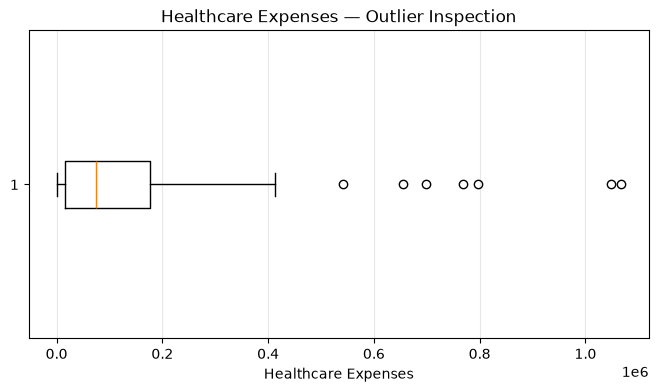

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.boxplot(patients["HEALTHCARE_EXPENSES"], vert=False)
plt.xlabel("Healthcare Expenses")
plt.title("Healthcare Expenses — Outlier Inspection")
plt.grid(axis="x", alpha=0.3)
plt.show()

In [63]:
Q1 = patients["HEALTHCARE_COVERAGE"].quantile(0.25)
Q3 = patients["HEALTHCARE_COVERAGE"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

coverage_outliers = patients[
    (patients["HEALTHCARE_COVERAGE"] < lower_bound)
    | (patients["HEALTHCARE_COVERAGE"] > upper_bound)
]

print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Potential outliers:", len(coverage_outliers))
print(coverage_outliers[["HEALTHCARE_COVERAGE"]])

Lower bound: -555681.53
Upper bound: 958615.52
Potential outliers: 4
    HEALTHCARE_COVERAGE
45           1285292.19
56           1002306.68
88           1186861.45
89           1231675.85


C:\Users\SHUBHAM PANCHAL\AppData\Local\Temp\ipykernel_14848\1794079031.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(patients["HEALTHCARE_COVERAGE"], vert=False)


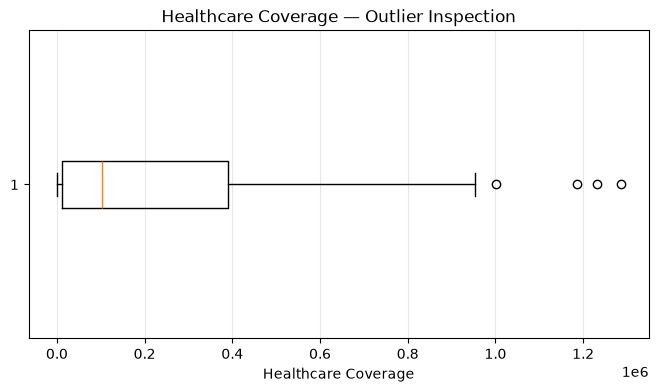

In [64]:
plt.figure(figsize=(8, 4))
plt.boxplot(patients["HEALTHCARE_COVERAGE"], vert=False)
plt.xlabel("Healthcare Coverage")
plt.title("Healthcare Coverage — Outlier Inspection")
plt.grid(axis="x", alpha=0.3)
plt.show()

In [65]:
Q1 = patients["INCOME"].quantile(0.25)
Q3 = patients["INCOME"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

income_outliers = patients[
    (patients["INCOME"] < lower_bound)
    | (patients["INCOME"] > upper_bound)
]

print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Potential outliers:", len(income_outliers))
print(income_outliers[["INCOME"]])

Lower bound: -101800.5
Upper bound: 259387.5
Potential outliers: 8
    INCOME
9   540331
11  728493
18  916979
20  625136
67  884375
79  631750
86  407543
97  320521


C:\Users\SHUBHAM PANCHAL\AppData\Local\Temp\ipykernel_14848\3956117326.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(patients["INCOME"], vert=False)


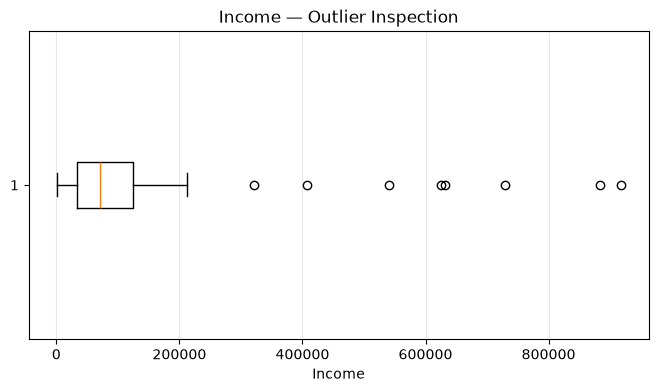

In [66]:
plt.figure(figsize=(8, 4))
plt.boxplot(patients["INCOME"], vert=False)
plt.xlabel("Income")
plt.title("Income — Outlier Inspection")
plt.grid(axis="x", alpha=0.3)
plt.show()

In [67]:
print(
    "Negative healthcare expenses:",
    (patients["HEALTHCARE_EXPENSES"] < 0).sum()
)

print(
    "Negative healthcare coverage:",
    (patients["HEALTHCARE_COVERAGE"] < 0).sum()
)

print(
    "Negative income:",
    (patients["INCOME"] < 0).sum()
)

Negative healthcare expenses: 0
Negative healthcare coverage: 0
Negative income: 0


In [68]:
conditions = ehr_tables["conditions"].copy()

print("Shape:", conditions.shape)
print("\nColumns:")
print(conditions.columns.tolist())
print("\nFirst 5 rows:")
display(conditions.head())

Shape: (3517, 7)

Columns:
['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'SYSTEM', 'CODE', 'DESCRIPTION']

First 5 rows:


,START,STOP,PATIENT,ENCOUNTER,SYSTEM,CODE,DESCRIPTION
0,1996-03-11,NaN,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-13f3-57f4a6b934f9,http://snomed.info/sct,224299000,Received higher education (finding)
1,2006-03-27,2018-01-22,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-1dc5-a353457420c6,http://snomed.info/sct,160903007,Full-time employment (finding)
2,2009-03-30,NaN,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-94b5-26ac8c6c7134,http://snomed.info/sct,714628002,Prediabetes (finding)
3,2009-03-30,NaN,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-94b5-26ac8c6c7134,http://snomed.info/sct,271737000,Anemia (disorder)
4,2009-03-30,NaN,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-94b5-26ac8c6c7134,http://snomed.info/sct,162864005,Body mass index 30+ - obesity (finding)


In [69]:
print(conditions.isnull().sum())

START            0
STOP           889
PATIENT          0
ENCOUNTER        0
SYSTEM           0
CODE             0
DESCRIPTION      0
dtype: int64


In [70]:
print("Duplicate complete rows:", conditions.duplicated().sum())
print("Duplicate condition codes:", conditions["CODE"].duplicated().sum())

Duplicate complete rows: 0
Duplicate condition codes: 3331


In [71]:
print(
    "Unmatched patient IDs:",
    (~conditions["PATIENT"].isin(patients["Id"])).sum()
)

Unmatched patient IDs: 0


In [72]:
print(conditions["DESCRIPTION"].value_counts().head(15))

DESCRIPTION
Medication review due (situation)             692
Stress (finding)                              260
Full-time employment (finding)                248
Gingivitis (disorder)                         244
Part-time employment (finding)                148
Social isolation (finding)                    108
Viral sinusitis (disorder)                    103
Limited social contact (finding)               95
Normal pregnancy (finding)                     84
Gingival disease (disorder)                    83
Acute viral pharyngitis (disorder)             75
Not in labor force (finding)                   70
Victim of intimate partner abuse (finding)     66
Received higher education (finding)            55
Acute bronchitis (disorder)                    50
Name: count, dtype: int64


In [73]:
prediabetes = conditions[
    conditions["DESCRIPTION"].str.contains(
        "prediabetes", case=False, na=False
    )
]

print("Prediabetes records:", len(prediabetes))
print("Unique patients:", prediabetes["PATIENT"].nunique())

display(prediabetes[["START", "STOP", "PATIENT", "CODE", "DESCRIPTION"]].head())

Prediabetes records: 34
Unique patients: 34


,START,STOP,PATIENT,CODE,DESCRIPTION
2,2009-03-30,NaN,cc3eac4a-34a7-9a15-1522-8087135631b7,714628002,Prediabetes (finding)
221,2000-11-20,NaN,f5749532-3295-ad01-d9b5-932c997e7a01,714628002,Prediabetes (finding)
364,2021-05-11,NaN,1be83f06-48ef-7bac-7097-b9e0644aeaf8,714628002,Prediabetes (finding)
428,2015-08-17,NaN,37549f60-b5a3-69cd-dea6-5a71c4bc23cf,714628002,Prediabetes (finding)
501,1996-01-15,NaN,8c5b83b2-737e-46cf-953b-414e07ed78e7,714628002,Prediabetes (finding)


In [74]:
print("Prediabetes records:", len(prediabetes))
print("Unique patients:", prediabetes["PATIENT"].nunique())

Prediabetes records: 34
Unique patients: 34


In [75]:
diabetes = conditions[
    conditions["DESCRIPTION"].str.contains(
        r"\bdiabetes\b", case=False, na=False, regex=True
    )
]

print("Diabetes records:", len(diabetes))
print("Unique patients:", diabetes["PATIENT"].nunique())
print("\nCondition descriptions:")
print(diabetes["DESCRIPTION"].value_counts())

Diabetes records: 24
Unique patients: 8

Condition descriptions:
DESCRIPTION
Diabetes mellitus type 2 (disorder)                                       6
Disorder of kidney due to diabetes mellitus (disorder)                    6
Microalbuminuria due to type 2 diabetes mellitus (disorder)               4
Proteinuria due to type 2 diabetes mellitus (disorder)                    3
Neuropathy due to type 2 diabetes mellitus (disorder)                     2
Nonproliferative diabetic retinopathy due to type II diabetes mellitus    2
Diabetes mellitus due to cystic fibrosis (disorder)                       1
Name: count, dtype: int64


In [76]:
cardio = conditions[
    conditions["DESCRIPTION"].str.contains(
        r"cardio|heart disease|hypertension|stroke|coronary",
        case=False,
        na=False,
        regex=True
    )
]

print("Cardiovascular-related records:", len(cardio))
print("Unique patients:", cardio["PATIENT"].nunique())
print("\nCondition descriptions:")
print(cardio["DESCRIPTION"].value_counts().head(15))

Cardiovascular-related records: 52
Unique patients: 26

Condition descriptions:
DESCRIPTION
Essential hypertension (disorder)                                         20
Ischemic heart disease (disorder)                                         13
Abnormal findings diagnostic imaging heart+coronary circulat (finding)    13
History of coronary artery bypass grafting (situation)                     6
Name: count, dtype: int64


In [77]:
obesity = conditions[
    conditions["DESCRIPTION"].str.contains(
        "obesity", case=False, na=False
    )
]

print("Obesity records:", len(obesity))
print("Unique patients:", obesity["PATIENT"].nunique())
print("\nCondition descriptions:")
print(obesity["DESCRIPTION"].value_counts())

Obesity records: 44
Unique patients: 44

Condition descriptions:
DESCRIPTION
Body mass index 30+ - obesity (finding)    44
Name: count, dtype: int64


In [78]:
conditions["START"] = pd.to_datetime(
    conditions["START"],
    errors="coerce"
)

print("Data type:", conditions["START"].dtype)
print("Invalid start dates:", conditions["START"].isna().sum())

Data type: datetime64[us]
Invalid start dates: 0


In [79]:
conditions["STOP"] = pd.to_datetime(
    conditions["STOP"],
    errors="coerce"
)

print("Data type:", conditions["STOP"].dtype)
print("Missing STOP dates:", conditions["STOP"].isna().sum())

Data type: datetime64[us]
Missing STOP dates: 889


In [80]:
invalid_ranges = conditions[
    conditions["STOP"].notna()
    & (conditions["STOP"] < conditions["START"])
]

print("Conditions with STOP before START:", len(invalid_ranges))

Conditions with STOP before START: 0


In [81]:
condition_encounters = set(conditions["ENCOUNTER"])
valid_encounters = set(ehr_tables["encounters"]["Id"])

print(
    "Unmatched encounter IDs:",
    len(condition_encounters - valid_encounters)
)

Unmatched encounter IDs: 0


In [82]:
duplicate_conditions = conditions.duplicated(
    subset=["PATIENT", "CODE", "START"],
    keep=False
)

print("Records involved in potential duplicates:", duplicate_conditions.sum())

Records involved in potential duplicates: 0


In [83]:
print("Earliest condition start:", conditions["START"].min())
print("Latest condition start:", conditions["START"].max())
print("Unique patients:", conditions["PATIENT"].nunique())
print("Unique condition codes:", conditions["CODE"].nunique())

Earliest condition start: 1947-01-25 00:00:00
Latest condition start: 2026-08-14 00:00:00
Unique patients: 108
Unique condition codes: 186


In [84]:
conditions["START"].dt.year.value_counts().sort_index().tail(20)

START
2007     28
2008     32
2009     32
2010     32
2011     34
2012     34
2013     52
2014    111
2015     85
2016    151
2017    228
2018    232
2019    254
2020    278
2021    230
2022    287
2023    275
2024    277
2025    302
2026    221
Name: count, dtype: int64

In [85]:
condition_counts = conditions["PATIENT"].value_counts()

print("Patients with condition records:", condition_counts.size)
print("Minimum records per patient:", condition_counts.min())
print("Median records per patient:", condition_counts.median())
print("Maximum records per patient:", condition_counts.max())

Patients with condition records: 108
Minimum records per patient: 1
Median records per patient: 26.5
Maximum records per patient: 273


In [86]:
condition_counts.sort_values(ascending=False).head(10)

PATIENT
bca1691f-8839-1d66-ed01-471134d55738    273
57efda89-b582-bb08-8a2d-e06b2c184bfc    158
5693c080-f485-91e7-54b9-ad9a8c12af62    132
355a4d50-2628-aa65-c336-deacf4d606fb    110
2211f478-b7b4-7711-16cf-84ffb52b9d2b     72
0b786670-17af-32e1-b2d2-f77c33874b30     67
0f3d04a2-f42e-1429-acef-0becd0a0fcea     55
3eec36b2-71cc-13c4-489a-495c45318bc3     51
7af6b271-f16d-21e1-882a-7bff71005a7b     50
d309f605-948b-962f-ca72-878ce8b8d154     48
Name: count, dtype: int64

In [87]:
top_patient_id = condition_counts.idxmax()

top_patient_conditions = conditions[
    conditions["PATIENT"] == top_patient_id
]

print("Patient ID:", top_patient_id)
print("\nMost frequent condition descriptions:")
print(top_patient_conditions["DESCRIPTION"].value_counts().head(15))

Patient ID: bca1691f-8839-1d66-ed01-471134d55738

Most frequent condition descriptions:
DESCRIPTION
Medication review due (situation)             72
Stress (finding)                              31
Full-time employment (finding)                26
Gingivitis (disorder)                         26
Part-time employment (finding)                17
Social isolation (finding)                    15
Limited social contact (finding)              12
Not in labor force (finding)                  12
Gingival disease (disorder)                    8
Victim of intimate partner abuse (finding)     4
Primary dental caries (disorder)               4
Fractured dental filling (finding)             3
Viral sinusitis (disorder)                     2
Infection of tooth (disorder)                  2
Chronic sinusitis (disorder)                   1
Name: count, dtype: int64


In [88]:
medication_reviews = top_patient_conditions[
    top_patient_conditions["DESCRIPTION"]
    == "Medication review due (situation)"
]

print("Total medication-review records:", len(medication_reviews))
print("Unique start dates:", medication_reviews["START"].nunique())
print("\nRecords per start date:")
print(medication_reviews["START"].value_counts().head(10))

Total medication-review records: 72
Unique start dates: 72

Records per start date:
START
2015-06-10    1
2016-10-05    1
2017-03-01    1
2017-03-29    1
2017-04-12    1
2017-04-19    1
2017-06-07    1
2017-06-28    1
2017-09-27    1
2018-01-24    1
Name: count, dtype: int64


In [89]:
conditions.groupby("DESCRIPTION")["STOP"].apply(
    lambda x: x.isna().sum()
).sort_values(ascending=False).head(10)

DESCRIPTION
Received higher education (finding)        55
Full-time employment (finding)             54
Medication review due (situation)          49
Stress (finding)                           48
Body mass index 30+ - obesity (finding)    44
Anemia (disorder)                          35
Prediabetes (finding)                      34
Chronic pain (finding)                     27
Chronic sinusitis (disorder)               25
Educated to high school level (finding)    22
Name: STOP, dtype: int64

In [90]:
condition_stop_summary = (
    conditions.groupby("DESCRIPTION")
    .agg(
        total_records=("STOP", "size"),
        missing_stop=("STOP", lambda x: x.isna().sum())
    )
)

condition_stop_summary["missing_stop_pct"] = (
    condition_stop_summary["missing_stop"]
    / condition_stop_summary["total_records"]
    * 100
)

condition_stop_summary.sort_values(
    "total_records", ascending=False
).head(10).round(2)

,total_records,missing_stop,missing_stop_pct
DESCRIPTION,,,
Medication review due (situation),692,49,7.08
Stress (finding),260,48,18.46
Full-time employment (finding),248,54,21.77
Gingivitis (disorder),244,3,1.23
Part-time employment (finding),148,19,12.84
Social isolation (finding),108,17,15.74
Viral sinusitis (disorder),103,0,0.00
Limited social contact (finding),95,19,20.00
Normal pregnancy (finding),84,4,4.76


In [91]:
code_description_counts = (
    conditions.groupby("CODE")["DESCRIPTION"]
    .nunique()
)

print(
    "Codes associated with multiple descriptions:",
    (code_description_counts > 1).sum()
)

Codes associated with multiple descriptions: 0


In [92]:
conditions["START_YEAR"] = conditions["START"].dt.year

patient_year_counts = (
    conditions.groupby(["PATIENT", "START_YEAR"])
    .size()
    .reset_index(name="condition_count")
)

print("Patient-year combinations:", len(patient_year_counts))
print("Average conditions per patient-year:", round(
    patient_year_counts["condition_count"].mean(), 2
))
print("Maximum conditions in one patient-year:", patient_year_counts["condition_count"].max())

Patient-year combinations: 1294
Average conditions per patient-year: 2.72
Maximum conditions in one patient-year: 32


In [93]:
patient_year_counts.sort_values(
    "condition_count",
    ascending=False
).head(10)

,PATIENT,START_YEAR,condition_count
522,5693c080-f485-91e7-54b9-ad9a8c12af62,2025,32
983,bca1691f-8839-1d66-ed01-471134d55738,2023,32
984,bca1691f-8839-1d66-ed01-471134d55738,2024,29
980,bca1691f-8839-1d66-ed01-471134d55738,2020,28
523,5693c080-f485-91e7-54b9-ad9a8c12af62,2026,27
985,bca1691f-8839-1d66-ed01-471134d55738,2025,27
977,bca1691f-8839-1d66-ed01-471134d55738,2017,27
986,bca1691f-8839-1d66-ed01-471134d55738,2026,23
341,355a4d50-2628-aa65-c336-deacf4d606fb,2025,22
338,355a4d50-2628-aa65-c336-deacf4d606fb,2022,22


In [94]:
dense_patient_id = "5693c080-f485-91e7-54b9-ad9a8c12af62"

dense_patient_2025 = conditions[
    (conditions["PATIENT"] == dense_patient_id)
    & (conditions["START_YEAR"] == 2025)
]

print("Total records:", len(dense_patient_2025))
print("\nCondition descriptions:")
print(dense_patient_2025["DESCRIPTION"].value_counts())

Total records: 32

Condition descriptions:
DESCRIPTION
Medication review due (situation)                   18
Stress (finding)                                     5
Full-time employment (finding)                       3
Social isolation (finding)                           2
Part-time employment (finding)                       2
Gingivitis (disorder)                                1
Reports of violence in the environment (finding)     1
Name: count, dtype: int64


In [95]:
dense_patient_2025.loc[
    dense_patient_2025["DESCRIPTION"]
    == "Medication review due (situation)",
    ["START", "STOP", "CODE", "ENCOUNTER"]
].sort_values("START")

,START,STOP,CODE,ENCOUNTER
3394,2025-04-13,2025-04-27,314529007,5693c080-f485-91e7-a439-311484e63827
3403,2025-05-04,2025-05-25,314529007,5693c080-f485-91e7-c5bb-d67b926205e5
3406,2025-06-01,2025-06-01,314529007,5693c080-f485-91e7-5adf-5eb510ff9305
3410,2025-06-08,2025-06-08,314529007,5693c080-f485-91e7-6473-03dfbee628e3
3412,2025-06-15,2025-06-29,314529007,5693c080-f485-91e7-27eb-bc9427f9f697
3414,2025-07-06,2025-07-20,314529007,5693c080-f485-91e7-72d4-4245f58abd50
3416,2025-07-27,2025-07-27,314529007,5693c080-f485-91e7-e348-bce2765ff5c4
3417,2025-08-03,2025-08-03,314529007,5693c080-f485-91e7-86e8-a4777be05afb
3421,2025-08-10,2025-08-10,314529007,5693c080-f485-91e7-bda4-b35ab8f532ff
3422,2025-08-17,2025-08-17,314529007,5693c080-f485-91e7-d382-1105552e9144


In [96]:
encounter_check = dense_patient_2025[
    dense_patient_2025["DESCRIPTION"]
    == "Medication review due (situation)"
].merge(
    ehr_tables["encounters"][["Id", "START", "STOP"]],
    left_on="ENCOUNTER",
    right_on="Id",
    how="left",
    suffixes=("_condition", "_encounter")
)

encounter_check[
    ["START_condition", "STOP_condition",
     "START_encounter", "STOP_encounter"]
].head(10)

,START_condition,STOP_condition,START_encounter,STOP_encounter
0,2025-04-13,2025-04-27,2025-04-13T23:50:14Z,2025-04-14T00:50:14Z
1,2025-05-04,2025-05-25,2025-05-04T23:50:14Z,2025-05-05T00:50:14Z
2,2025-06-01,2025-06-01,2025-06-01T23:50:14Z,2025-06-02T00:50:14Z
3,2025-06-08,2025-06-08,2025-06-08T23:50:14Z,2025-06-09T00:43:10Z
4,2025-06-15,2025-06-29,2025-06-15T23:50:14Z,2025-06-16T00:50:14Z
5,2025-07-06,2025-07-20,2025-07-06T23:50:14Z,2025-07-07T00:50:14Z
6,2025-07-27,2025-07-27,2025-07-27T23:50:14Z,2025-07-28T00:50:14Z
7,2025-08-03,2025-08-03,2025-08-03T23:50:14Z,2025-08-04T00:50:14Z
8,2025-08-10,2025-08-10,2025-08-10T23:50:14Z,2025-08-11T00:50:14Z
9,2025-08-17,2025-08-17,2025-08-17T23:50:14Z,2025-08-18T00:50:14Z


In [97]:
obesity = conditions[
    conditions["DESCRIPTION"].str.contains(
        "obesity", case=False, na=False
    )
]

print("Obesity records:", len(obesity))
print("Unique patients:", obesity["PATIENT"].nunique())
print("\nCondition descriptions:")
print(obesity["DESCRIPTION"].value_counts())

Obesity records: 44
Unique patients: 44

Condition descriptions:
DESCRIPTION
Body mass index 30+ - obesity (finding)    44
Name: count, dtype: int64


In [98]:
condition_start_dates = pd.to_datetime(
    encounter_check["START_condition"]
).dt.date

encounter_start_dates = pd.to_datetime(
    encounter_check["START_encounter"],
    utc=True
).dt.date

print(
    "Matching start dates:",
    (condition_start_dates == encounter_start_dates).sum()
)

print(
    "Non-matching start dates:",
    (condition_start_dates != encounter_start_dates).sum()
)

Matching start dates: 18
Non-matching start dates: 0


In [99]:
all_condition_encounters = conditions.merge(
    ehr_tables["encounters"][["Id", "START"]],
    left_on="ENCOUNTER",
    right_on="Id",
    how="left",
    suffixes=("_condition", "_encounter")
)

condition_dates = pd.to_datetime(
    all_condition_encounters["START_condition"]
).dt.date

encounter_dates = pd.to_datetime(
    all_condition_encounters["START_encounter"],
    utc=True
).dt.date

print("Total records checked:", len(all_condition_encounters))
print("Matching start dates:", (condition_dates == encounter_dates).sum())
print("Non-matching start dates:", (condition_dates != encounter_dates).sum())

Total records checked: 3517
Matching start dates: 3281
Non-matching start dates: 236


In [100]:
date_mismatches = all_condition_encounters.loc[
    condition_dates != encounter_dates,
    [
        "PATIENT",
        "DESCRIPTION",
        "START_condition",
        "START_encounter",
        "ENCOUNTER"
    ]
]

date_mismatches.head(10)

,PATIENT,DESCRIPTION,START_condition,START_encounter,ENCOUNTER
30,8b9df7af-24b3-66ee-afeb-2734ebcbd33c,Acute infective cystitis (disorder),2021-06-17,2021-04-11T03:41:03Z,8b9df7af-24b3-66ee-8975-1ef03abfc74d
161,239b0c86-371a-3080-fcd9-8379b296bc9a,Acute infective cystitis (disorder),2018-08-31,2018-01-15T01:38:24Z,239b0c86-371a-3080-21af-7582d7d624b7
172,87f7ad7b-85f9-d26d-5a41-9933f4039331,Educated to high school level (finding),1987-06-20,1987-06-19T23:31:00Z,87f7ad7b-85f9-d26d-6ace-0a1185fb78d1
180,87f7ad7b-85f9-d26d-5a41-9933f4039331,Has a criminal record (finding),2011-05-07,2011-05-06T23:31:00Z,87f7ad7b-85f9-d26d-98dd-55637e225cfe
182,87f7ad7b-85f9-d26d-5a41-9933f4039331,Stress (finding),2013-05-11,2013-05-10T23:31:00Z,87f7ad7b-85f9-d26d-9676-37fa1dd512ce
184,87f7ad7b-85f9-d26d-5a41-9933f4039331,Full-time employment (finding),2015-05-16,2015-05-15T23:31:00Z,87f7ad7b-85f9-d26d-c42f-6f71be3e4b0b
188,87f7ad7b-85f9-d26d-5a41-9933f4039331,Unemployed (finding),2017-05-20,2017-05-19T23:31:00Z,87f7ad7b-85f9-d26d-fc24-e40761f6971c
191,87f7ad7b-85f9-d26d-5a41-9933f4039331,Full-time employment (finding),2019-04-27,2019-04-26T23:31:00Z,87f7ad7b-85f9-d26d-bb84-66575820aa54
194,87f7ad7b-85f9-d26d-5a41-9933f4039331,Victim of intimate partner abuse (finding),2020-05-02,2020-05-01T23:31:00Z,87f7ad7b-85f9-d26d-5832-02f6b7a712d7
195,87f7ad7b-85f9-d26d-5a41-9933f4039331,Gingivitis (disorder),2020-05-02,2020-05-01T23:31:00Z,87f7ad7b-85f9-d26d-5832-02f6b7a712d7


In [101]:
all_condition_encounters["condition_start_date"] = pd.to_datetime(
    all_condition_encounters["START_condition"]
).dt.normalize()

all_condition_encounters["encounter_start_date"] = pd.to_datetime(
    all_condition_encounters["START_encounter"],
    utc=True
).dt.tz_localize(None).dt.normalize()

all_condition_encounters["start_date_difference_days"] = (
    all_condition_encounters["condition_start_date"]
    - all_condition_encounters["encounter_start_date"]
).dt.days

print(
    all_condition_encounters["start_date_difference_days"]
    .describe()
)

count    3517.000000
mean        1.003128
std        18.349974
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       827.000000
Name: start_date_difference_days, dtype: float64


In [102]:
date_diff_counts = pd.Series({
    "Same date (0 days)": (all_condition_encounters["start_date_difference_days"] == 0).sum(),
    "1–7 days": all_condition_encounters["start_date_difference_days"].between(1, 7).sum(),
    "8–30 days": all_condition_encounters["start_date_difference_days"].between(8, 30).sum(),
    "31–90 days": all_condition_encounters["start_date_difference_days"].between(31, 90).sum(),
    "More than 90 days": (all_condition_encounters["start_date_difference_days"] > 90).sum()
})

display(date_diff_counts)

Same date (0 days)    3281
1–7 days               213
8–30 days                6
31–90 days               5
More than 90 days       12
dtype: int64

In [103]:
large_date_gaps = (
    all_condition_encounters[
        all_condition_encounters["start_date_difference_days"] > 90
    ][
        [
            "PATIENT",
            "DESCRIPTION",
            "START_condition",
            "START_encounter",
            "start_date_difference_days",
            "ENCOUNTER"
        ]
    ]
    .sort_values("start_date_difference_days", ascending=False)
)

display(large_date_gaps)

,PATIENT,DESCRIPTION,START_condition,START_encounter,start_date_difference_days,ENCOUNTER
2344,97e39468-6488-ca8f-fac2-235a80b4dcf7,Acute infective cystitis (disorder),2024-06-08,2022-03-04T02:41:42Z,827,97e39468-6488-ca8f-7fde-19a2fad5c844
2500,afb99eee-0bd5-8853-8a32-fad74da7b103,Acute infective cystitis (disorder),2019-01-13,2017-12-22T08:46:09Z,387,afb99eee-0bd5-8853-df9b-b6c8b98e761f
1917,adec1419-cf81-6640-abe6-cac7c0c1b9d4,Acute infective cystitis (disorder),2021-01-14,2020-03-28T02:11:02Z,292,adec1419-cf81-6640-0e04-1bd67f0589d2
2520,5dae1e9e-46fb-5537-54f4-8837a56dd3d5,Acute infective cystitis (disorder),2020-05-12,2019-07-29T05:35:02Z,288,5dae1e9e-46fb-5537-74b8-9549758ccc22
161,239b0c86-371a-3080-fcd9-8379b296bc9a,Acute infective cystitis (disorder),2018-08-31,2018-01-15T01:38:24Z,228,239b0c86-371a-3080-21af-7582d7d624b7
2996,3eec36b2-71cc-13c4-489a-495c45318bc3,Suspected disease caused by Severe acute respi...,2020-10-01,2020-04-16T18:16:45Z,168,3eec36b2-71cc-13c4-b46a-345df0144308
2274,031ce8e2-1443-01b4-de6b-61a4084a7166,Homeless (finding),2009-08-19,2009-04-02T15:44:09Z,139,031ce8e2-1443-01b4-97b7-081db810f8a6
339,4e71643c-f046-a74f-c2e2-4049efe17cd4,Acute infective cystitis (disorder),2026-06-18,2026-01-30T12:22:29Z,139,4e71643c-f046-a74f-5ba0-3f194b34f319
823,d21f2794-014b-c66b-3688-888382ab7434,Recurrent urinary tract infection (disorder),1996-10-17,1996-06-17T01:56:54Z,122,d21f2794-014b-c66b-3e23-ae48e51848ef
1986,8704c44c-8b97-e35a-3bac-7d5b24de06b3,Recurrent urinary tract infection (disorder),2004-06-20,2004-03-03T17:19:39Z,109,8704c44c-8b97-e35a-b57d-84809b73c1b6


In [104]:
large_gaps = all_condition_encounters[
    all_condition_encounters["start_date_difference_days"] > 90
]

print("Records with gaps > 90 days:", len(large_gaps))
print("Unique patients affected:", large_gaps["PATIENT"].nunique())

print("\nRecords per affected patient:")
display(
    large_gaps["PATIENT"]
    .value_counts()
    .rename("large_gap_records")
    .to_frame()
)

Records with gaps > 90 days: 12
Unique patients affected: 12

Records per affected patient:


,large_gap_records
PATIENT,
239b0c86-371a-3080-fcd9-8379b296bc9a,1
4e71643c-f046-a74f-c2e2-4049efe17cd4,1
d21f2794-014b-c66b-3688-888382ab7434,1
adec1419-cf81-6640-abe6-cac7c0c1b9d4,1
8704c44c-8b97-e35a-3bac-7d5b24de06b3,1
ad48e669-959c-b6f8-8ddb-dda7a6d37473,1
031ce8e2-1443-01b4-de6b-61a4084a7166,1
97e39468-6488-ca8f-fac2-235a80b4dcf7,1
afb99eee-0bd5-8853-8a32-fad74da7b103,1


In [105]:
medications = ehr_tables["medications"].copy()

print("Shape:", medications.shape)
print("\nColumns:")
print(medications.columns.tolist())

print("\nFirst 5 rows:")
display(medications.head())

Shape: (3850, 13)

Columns:
['START', 'STOP', 'PATIENT', 'PAYER', 'ENCOUNTER', 'CODE', 'DESCRIPTION', 'BASE_COST', 'PAYER_COVERAGE', 'DISPENSES', 'TOTALCOST', 'REASONCODE', 'REASONDESCRIPTION']

First 5 rows:


,START,STOP,PATIENT,PAYER,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,PAYER_COVERAGE,DISPENSES,TOTALCOST,REASONCODE,REASONDESCRIPTION
0,2018-02-05T12:22:02Z,2018-02-05T12:22:02Z,cc3eac4a-34a7-9a15-1522-8087135631b7,0133f751-9229-3cfd-815f-b6d4979bdd6a,cc3eac4a-34a7-9a15-197d-c8faa82aee51,1535362,sodium fluoride 0.0272 MG/MG Oral Gel,129.94,0.00,1,129.94,103697008.0,Patient referral for dental care (procedure)
1,2020-02-10T11:11:14Z,2020-02-10T11:11:14Z,cc3eac4a-34a7-9a15-1522-8087135631b7,0133f751-9229-3cfd-815f-b6d4979bdd6a,cc3eac4a-34a7-9a15-88f3-730564694133,1535362,sodium fluoride 0.0272 MG/MG Oral Gel,129.94,0.00,1,129.94,103697008.0,Patient referral for dental care (procedure)
2,2022-02-14T11:09:18Z,2022-02-14T11:09:18Z,cc3eac4a-34a7-9a15-1522-8087135631b7,0133f751-9229-3cfd-815f-b6d4979bdd6a,cc3eac4a-34a7-9a15-473f-34cd7ed0707a,1535362,sodium fluoride 0.0272 MG/MG Oral Gel,129.94,0.00,1,129.94,103697008.0,Patient referral for dental care (procedure)
3,2025-11-29T13:35:36Z,2025-12-13T13:35:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,734afbd6-4794-363b-9bc0-6a3981533ed5,cc3eac4a-34a7-9a15-a77a-027dab52c156,562251,Amoxicillin 250 MG / Clavulanate 125 MG Oral T...,529.35,0.00,1,529.35,444814009.0,Viral sinusitis (disorder)
4,2021-06-17T05:02:31Z,2021-06-17T19:02:31Z,8b9df7af-24b3-66ee-afeb-2734ebcbd33c,df166300-5a78-3502-a46a-832842197811,8b9df7af-24b3-66ee-5ca7-72a6a1f9f6bc,198335,sulfamethoxazole 800 MG / trimethoprim 160 MG ...,129.94,79.94,1,129.94,307426000.0,Acute infective cystitis (disorder)


In [106]:
# ============================================
# MEDICATIONS: INITIAL DATA QUALITY INSPECTION
# ============================================

# 1. Dataset overview
print("=" * 60)
print("1. DATASET OVERVIEW")
print("=" * 60)

print("Shape:", medications.shape)
print("Total rows:", len(medications))
print("Total columns:", len(medications.columns))

print("\nData types:")
display(medications.dtypes.to_frame("Data Type"))


# 2. Missing values
print("\n" + "=" * 60)
print("2. MISSING VALUES")
print("=" * 60)

missing_summary = pd.DataFrame({
    "Missing_Count": medications.isna().sum(),
    "Missing_Percentage": (
        medications.isna().mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing_Count",
        ascending=False
    )
)


# 3. Duplicate checks
print("\n" + "=" * 60)
print("3. DUPLICATE CHECKS")
print("=" * 60)

print(
    "Exact duplicate rows:",
    medications.duplicated().sum()
)

print(
    "Duplicate medication IDs:",
    "No dedicated medication ID column exists"
)

# A combination of these columns may identify repeated
# patient-medication records, but repetition is not
# automatically a duplicate.
medication_key = [
    "PATIENT",
    "ENCOUNTER",
    "CODE",
    "START"
]

print(
    "Duplicate patient-encounter-medication-start combinations:",
    medications.duplicated(
        subset=medication_key
    ).sum()
)


# 4. Date validation
print("\n" + "=" * 60)
print("4. DATE VALIDATION")
print("=" * 60)

medications["START"] = pd.to_datetime(
    medications["START"],
    errors="coerce",
    utc=True
)

medications["STOP"] = pd.to_datetime(
    medications["STOP"],
    errors="coerce",
    utc=True
)

print("Invalid or missing START:", medications["START"].isna().sum())
print("Missing STOP:", medications["STOP"].isna().sum())

invalid_dates = (
    medications["START"].notna()
    & medications["STOP"].notna()
    & (medications["STOP"] < medications["START"])
)

print("STOP before START:", invalid_dates.sum())

medications["DURATION_DAYS"] = (
    medications["STOP"] - medications["START"]
).dt.total_seconds() / 86400

print("\nMedication duration in days:")
display(medications["DURATION_DAYS"].describe())


# 5. Numeric validation
print("\n" + "=" * 60)
print("5. NUMERIC COLUMNS")
print("=" * 60)

numeric_columns = [
    "BASE_COST",
    "PAYER_COVERAGE",
    "DISPENSES",
    "TOTALCOST"
]

for col in numeric_columns:
    medications[col] = pd.to_numeric(
        medications[col],
        errors="coerce"
    )

display(medications[numeric_columns].describe().T)

print("\nMissing values after numeric conversion:")
display(medications[numeric_columns].isna().sum().to_frame("Missing_Count"))

print("\nNegative numeric values:")
display(
    (medications[numeric_columns] < 0)
    .sum()
    .to_frame("Negative_Count")
)


# 6. Patient, encounter and payer consistency
print("\n" + "=" * 60)
print("6. REFERENCE ID VALIDATION")
print("=" * 60)

patients_ids = set(ehr_tables["patients"]["Id"].dropna())
encounter_ids = set(ehr_tables["encounters"]["Id"].dropna())
payer_ids = set(ehr_tables["payers"]["Id"].dropna())

print(
    "Unmatched patient IDs:",
    (~medications["PATIENT"].isin(patients_ids)).sum()
)

print(
    "Unmatched encounter IDs:",
    (~medications["ENCOUNTER"].isin(encounter_ids)).sum()
)

print(
    "Unmatched payer IDs:",
    (~medications["PAYER"].isin(payer_ids)).sum()
)


# 7. Most common medications
print("\n" + "=" * 60)
print("7. TOP 15 MEDICATIONS")
print("=" * 60)

display(
    medications["DESCRIPTION"]
    .value_counts(dropna=False)
    .head(15)
    .rename("Record_Count")
    .to_frame()
)


# 8. Cost consistency
print("\n" + "=" * 60)
print("8. COST CONSISTENCY")
print("=" * 60)

cost_comparison = (
    medications["BASE_COST"]
    - medications["TOTALCOST"]
).abs()

print(
    "Rows where BASE_COST differs from TOTALCOST:",
    (cost_comparison > 0.01).sum()
)

print(
    "Rows where payer coverage exceeds total cost:",
    (
        medications["PAYER_COVERAGE"]
        > medications["TOTALCOST"]
    ).sum()
)

print("\nInitial inspection completed.")

1. DATASET OVERVIEW
Shape: (3850, 13)
Total rows: 3850
Total columns: 13

Data types:


,Data Type
START,str
STOP,str
PATIENT,str
PAYER,str
ENCOUNTER,str
CODE,int64
DESCRIPTION,str
BASE_COST,float64
PAYER_COVERAGE,float64
DISPENSES,int64



2. MISSING VALUES


,Missing_Count,Missing_Percentage
REASONCODE,900,23.38
REASONDESCRIPTION,900,23.38
STOP,268,6.96
START,0,0.00
PATIENT,0,0.00
ENCOUNTER,0,0.00
PAYER,0,0.00
CODE,0,0.00
DESCRIPTION,0,0.00
PAYER_COVERAGE,0,0.00



3. DUPLICATE CHECKS
Exact duplicate rows: 0
Duplicate medication IDs: No dedicated medication ID column exists
Duplicate patient-encounter-medication-start combinations: 9

4. DATE VALIDATION
Invalid or missing START: 0
Missing STOP: 268
STOP before START: 0

Medication duration in days:


...


Negative numeric values:


,Negative_Count
BASE_COST,0
PAYER_COVERAGE,0
DISPENSES,0
TOTALCOST,0



6. REFERENCE ID VALIDATION
Unmatched patient IDs: 0
Unmatched encounter IDs: 0
Unmatched payer IDs: 0

7. TOP 15 MEDICATIONS


,Record_Count
DESCRIPTION,
1 ML Epoetin Alfa 4000 UNT/ML Injection [Epogen],521
insulin isophane human 70 UNT/ML / insulin regular human 30 UNT/ML Injectable Suspension [Humulin],422
Hydrochlorothiazide 25 MG Oral Tablet,405
lisinopril 10 MG Oral Tablet,318
sodium fluoride 0.0272 MG/MG Oral Gel,257
Acetaminophen 325 MG Oral Tablet [Tylenol],234
24 HR Metformin hydrochloride 500 MG Extended Release Oral Tablet,218
amLODIPine 2.5 MG Oral Tablet,90
Simvastatin 10 MG Oral Tablet,89



8. COST CONSISTENCY
Rows where BASE_COST differs from TOTALCOST: 1273
Rows where payer coverage exceeds total cost: 0

Initial inspection completed.


In [107]:
# ============================================
# MEDICATIONS: INVESTIGATE POTENTIAL ANOMALIES
# ============================================

# 1. Ten longest medication durations
print("=" * 70)
print("1. TEN LONGEST MEDICATION DURATIONS")
print("=" * 70)

duration_columns = [
    "PATIENT",
    "DESCRIPTION",
    "START",
    "STOP",
    "DURATION_DAYS",
    "DISPENSES",
    "BASE_COST",
    "TOTALCOST"
]

display(
    medications.nlargest(10, "DURATION_DAYS")[
        duration_columns
    ]
)


# 2. Investigate duplicate medication combinations
print("\n" + "=" * 70)
print("2. POTENTIAL DUPLICATE MEDICATION RECORDS")
print("=" * 70)

duplicate_mask = medications.duplicated(
    subset=medication_key,
    keep=False
)

duplicate_records = medications.loc[
    duplicate_mask
].sort_values(medication_key)

print("Records involved in duplicate combinations:",
      len(duplicate_records))

display(
    duplicate_records[
        [
            "PATIENT",
            "ENCOUNTER",
            "CODE",
            "DESCRIPTION",
            "START",
            "STOP",
            "BASE_COST",
            "PAYER_COVERAGE",
            "DISPENSES",
            "TOTALCOST"
        ]
    ]
)


# 3. Ten highest total costs
print("\n" + "=" * 70)
print("3. TEN HIGHEST TOTAL COST RECORDS")
print("=" * 70)

display(
    medications.nlargest(10, "TOTALCOST")[
        [
            "PATIENT",
            "DESCRIPTION",
            "START",
            "STOP",
            "DISPENSES",
            "BASE_COST",
            "PAYER_COVERAGE",
            "TOTALCOST"
        ]
    ]
)


# 4. Check whether TOTALCOST approximately equals
# BASE_COST multiplied by DISPENSES
print("\n" + "=" * 70)
print("4. COST FORMULA INVESTIGATION")
print("=" * 70)

medications["EXPECTED_TOTAL_FROM_BASE"] = (
    medications["BASE_COST"] * medications["DISPENSES"]
)

medications["COST_DIFFERENCE_FROM_EXPECTED"] = (
    medications["TOTALCOST"]
    - medications["EXPECTED_TOTAL_FROM_BASE"]
)

print(
    "Rows where TOTALCOST differs from "
    "BASE_COST × DISPENSES by more than 0.01:",
    (
        medications["COST_DIFFERENCE_FROM_EXPECTED"].abs()
        > 0.01
    ).sum()
)

print("\nCost formula comparison:")
display(
    medications[
        [
            "BASE_COST",
            "DISPENSES",
            "TOTALCOST",
            "EXPECTED_TOTAL_FROM_BASE",
            "COST_DIFFERENCE_FROM_EXPECTED"
        ]
    ].head(10)
)

1. TEN LONGEST MEDICATION DURATIONS


,PATIENT,DESCRIPTION,START,STOP,DURATION_DAYS,DISPENSES,BASE_COST,TOTALCOST
2486,bca1691f-8839-1d66-ed01-471134d55738,Simvastatin 10 MG Oral Tablet,1986-11-12 11:39:55+00:00,2025-07-30 11:39:55+00:00,14140.000000,10,0.39,3.90
644,1d63466e-0cfd-eb12-77aa-d153393355e5,Simvastatin 10 MG Oral Tablet,1996-11-05 11:58:03+00:00,2026-02-10 11:58:03+00:00,10689.000000,10,0.30,3.00
766,f6745f8a-8107-443e-8946-3e6329d20408,Naproxen sodium 220 MG Oral Tablet,1999-12-31 12:10:58+00:00,2019-09-03 12:10:58+00:00,7186.000000,239,168.16,40190.24
334,3c0e60c4-176e-2c4c-3b85-b46be390cf5e,Simvastatin 10 MG Oral Tablet,2008-12-11 18:39:12+00:00,2026-01-10 18:39:12+00:00,6239.000000,10,0.30,3.00
2309,3935e8a9-9b9f-fd00-fe22-bcb810d0330b,Simvastatin 10 MG Oral Tablet,2012-10-30 17:51:49+00:00,2025-11-12 17:51:49+00:00,4761.000000,10,0.30,3.00
772,f6745f8a-8107-443e-8946-3e6329d20408,Simvastatin 10 MG Oral Tablet,2014-08-05 12:10:58+00:00,2025-09-17 12:10:58+00:00,4061.000000,10,0.30,3.00
2337,3732fde5-efc6-d57a-517b-0500f2177181,Simvastatin 10 MG Oral Tablet,2016-06-24 10:39:49+00:00,2026-08-07 10:39:49+00:00,3696.000000,10,0.30,3.00
1122,716c6d0a-2a5d-0aaa-9ced-312ed6a943da,Simvastatin 10 MG Oral Tablet,2006-07-25 23:29:08+00:00,2014-09-02 23:29:08+00:00,2961.000000,10,0.30,3.00
504,fb56f051-a2cd-ac10-dcb0-e0738295fc1f,Acetaminophen 325 MG / oxyCODONE Hydrochloride...,1982-08-01 11:24:26+00:00,1990-05-07 10:41:04+00:00,2835.969884,202,7.41,1496.82
2024,f870c432-0887-125e-f778-cf5110d3de1d,Simvastatin 10 MG Oral Tablet,2020-09-16 02:20:33+00:00,2025-09-25 02:20:33+00:00,1835.000000,10,0.30,3.00



2. POTENTIAL DUPLICATE MEDICATION RECORDS
Records involved in duplicate combinations: 18


,PATIENT,ENCOUNTER,CODE,DESCRIPTION,START,STOP,BASE_COST,PAYER_COVERAGE,DISPENSES,TOTALCOST
2075,031ce8e2-1443-01b4-de6b-61a4084a7166,031ce8e2-1443-01b4-8d24-110821e84d57,314076,lisinopril 10 MG Oral Tablet,2012-03-22 15:44:09+00:00,2012-03-22 15:44:09+00:00,0.91,0.00,1,0.91
2076,031ce8e2-1443-01b4-de6b-61a4084a7166,031ce8e2-1443-01b4-8d24-110821e84d57,314076,lisinopril 10 MG Oral Tablet,2012-03-22 15:44:09+00:00,2013-03-28 15:44:09+00:00,0.91,0.00,4,3.64
695,355a4d50-2628-aa65-c336-deacf4d606fb,355a4d50-2628-aa65-b356-bc930f7495d6,106892,insulin isophane human 70 UNT/ML / insulin r...,2021-12-30 20:04:51+00:00,2021-12-30 20:04:51+00:00,329.59,263.67,1,329.59
696,355a4d50-2628-aa65-c336-deacf4d606fb,355a4d50-2628-aa65-b356-bc930f7495d6,106892,insulin isophane human 70 UNT/ML / insulin r...,2021-12-30 20:04:51+00:00,2022-01-13 20:04:51+00:00,126.89,101.51,1,126.89
2135,35f80d0e-eaad-ef68-b762-3a1c12a872c1,35f80d0e-eaad-ef68-60a0-b3f9fb295f95,314076,lisinopril 10 MG Oral Tablet,2026-02-01 22:21:23+00:00,2026-02-01 22:21:23+00:00,0.91,0.00,1,0.91
2136,35f80d0e-eaad-ef68-b762-3a1c12a872c1,35f80d0e-eaad-ef68-60a0-b3f9fb295f95,314076,lisinopril 10 MG Oral Tablet,2026-02-01 22:21:23+00:00,NaT,0.91,0.00,2,1.82
340,3c0e60c4-176e-2c4c-3b85-b46be390cf5e,3c0e60c4-176e-2c4c-ea57-28f16fd723dc,314076,lisinopril 10 MG Oral Tablet,2020-12-10 18:39:12+00:00,2020-12-10 18:39:12+00:00,0.91,0.00,1,0.91
341,3c0e60c4-176e-2c4c-3b85-b46be390cf5e,3c0e60c4-176e-2c4c-ea57-28f16fd723dc,314076,lisinopril 10 MG Oral Tablet,2020-12-10 18:39:12+00:00,2021-12-16 18:39:12+00:00,0.91,0.00,4,3.64
170,7132442e-b0b9-a886-e28d-f83700e5a3bd,7132442e-b0b9-a886-ad2e-8411a6c0d0a7,314076,lisinopril 10 MG Oral Tablet,2020-03-08 14:54:53+00:00,2020-03-08 14:54:53+00:00,0.91,0.00,1,0.91
171,7132442e-b0b9-a886-e28d-f83700e5a3bd,7132442e-b0b9-a886-ad2e-8411a6c0d0a7,314076,lisinopril 10 MG Oral Tablet,2020-03-08 14:54:53+00:00,2021-03-14 14:54:53+00:00,0.91,0.00,4,3.64



3. TEN HIGHEST TOTAL COST RECORDS


,PATIENT,DESCRIPTION,START,STOP,DISPENSES,BASE_COST,PAYER_COVERAGE,TOTALCOST
1918,0f3d04a2-f42e-1429-acef-0becd0a0fcea,Alteplase 100 MG Injection,2021-05-12 20:44:21+00:00,NaT,64,91728.00,73382.40,5870592.00
2487,bca1691f-8839-1d66-ed01-471134d55738,Clopidogrel 75 MG Oral Tablet,2005-01-26 11:39:55+00:00,NaT,262,818.99,0.00,214575.38
646,1d63466e-0cfd-eb12-77aa-d153393355e5,Clopidogrel 75 MG Oral Tablet,2010-11-16 11:58:03+00:00,NaT,192,854.57,0.00,164077.44
2018,f870c432-0887-125e-f778-cf5110d3de1d,Clopidogrel 75 MG Oral Tablet,2013-09-11 02:20:33+00:00,NaT,157,1030.75,824.60,161827.75
245,37549f60-b5a3-69cd-dea6-5a71c4bc23cf,Fexofenadine hydrochloride 60 MG Oral Tablet,2005-06-18 13:48:14+00:00,NaT,257,550.36,0.00,141442.52
2032,1426480f-ccc7-2393-40bd-f92ccf2b74b2,diphenhydrAMINE Hydrochloride 25 MG Oral Tablet,1965-09-18 05:58:50+00:00,NaT,741,183.45,0.00,135936.45
1163,8ece28c6-f931-b0e0-5c0e-72b8d8d3c86a,Clopidogrel 75 MG Oral Tablet,2016-08-27 01:49:50+00:00,NaT,121,1078.92,1043.92,130549.32
764,f6745f8a-8107-443e-8946-3e6329d20408,diphenhydrAMINE Hydrochloride 25 MG Oral Tablet,1955-12-04 12:10:58+00:00,NaT,861,150.82,0.00,129856.02
407,a45aa142-d1e9-d944-f2c7-05015c90762d,Clopidogrel 75 MG Oral Tablet,2009-10-21 14:32:41+00:00,NaT,204,624.31,0.00,127359.24
2112,31f368d9-3fdc-a15f-ccdc-fafa74a860e9,Astemizole 10 MG Oral Tablet,1981-12-02 19:06:03+00:00,NaT,544,183.45,133.45,99796.80



4. COST FORMULA INVESTIGATION
Rows where TOTALCOST differs from BASE_COST × DISPENSES by more than 0.01: 0

Cost formula comparison:


,BASE_COST,DISPENSES,TOTALCOST,EXPECTED_TOTAL_FROM_BASE,COST_DIFFERENCE_FROM_EXPECTED
0,129.94,1,129.94,129.94,0.0
1,129.94,1,129.94,129.94,0.0
2,129.94,1,129.94,129.94,0.0
3,529.35,1,529.35,529.35,0.0
4,129.94,1,129.94,129.94,0.0
5,45.86,1,45.86,45.86,0.0
6,0.91,4,3.64,3.64,0.0
7,2.11,12,25.32,25.32,0.0
8,0.91,4,3.64,3.64,0.0
9,10.16,12,121.92,121.92,0.0


In [108]:
# ============================================
# MEDICATIONS: DURATION AND DISPENSE ANALYSIS
# ============================================

# 1. Duration distribution
print("=" * 60)
print("1. MEDICATION DURATION DISTRIBUTION")
print("=" * 60)

duration_thresholds = [365, 1825, 3650]

for days in duration_thresholds:
    count = (medications["DURATION_DAYS"] > days).sum()
    percentage = count / len(medications) * 100

    print(
        f"Duration > {days} days: "
        f"{count} records ({percentage:.2f}%)"
    )


# 2. Dispense-count distribution
print("\n" + "=" * 60)
print("2. DISPENSE COUNT DISTRIBUTION")
print("=" * 60)

print("\nDispense count statistics:")
display(medications["DISPENSES"].describe())

dispense_thresholds = [10, 50, 100, 500]

for threshold in dispense_thresholds:
    count = (medications["DISPENSES"] > threshold).sum()
    percentage = count / len(medications) * 100

    print(
        f"DISPENSES > {threshold}: "
        f"{count} records ({percentage:.2f}%)"
    )


# 3. Missing STOP by medication
print("\n" + "=" * 60)
print("3. MISSING STOP BY MEDICATION")
print("=" * 60)

missing_stop_summary = (
    medications.assign(STOP_MISSING=medications["STOP"].isna())
    .groupby("DESCRIPTION")
    .agg(
        Total_Records=("DESCRIPTION", "size"),
        Missing_STOP=("STOP_MISSING", "sum")
    )
)

missing_stop_summary["Missing_STOP_Percentage"] = (
    missing_stop_summary["Missing_STOP"]
    / missing_stop_summary["Total_Records"]
    * 100
).round(2)

display(
    missing_stop_summary
    .sort_values(
        ["Missing_STOP", "Total_Records"],
        ascending=False
    )
    .head(15)
)


# 4. Flag candidates for review without deleting anything
print("\n" + "=" * 60)
print("4. RECORDS FLAGGED FOR REVIEW")
print("=" * 60)

medications["REVIEW_LONG_DURATION"] = (
    medications["DURATION_DAYS"] > 3650
)

medications["REVIEW_HIGH_DISPENSES"] = (
    medications["DISPENSES"] > 100
)

print(
    "Duration > 10 years:",
    medications["REVIEW_LONG_DURATION"].sum()
)

print(
    "Dispenses > 100:",
    medications["REVIEW_HIGH_DISPENSES"].sum()
)

print("\nReview flags created. Original medication records retained.")

1. MEDICATION DURATION DISTRIBUTION
Duration > 365 days: 564 records (14.65%)
Duration > 1825 days: 10 records (0.26%)
Duration > 3650 days: 7 records (0.18%)

2. DISPENSE COUNT DISTRIBUTION

Dispense count statistics:


count    3850.000000
mean       10.169351
std        47.664710
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max       861.000000
Name: DISPENSES, dtype: float64

DISPENSES > 10: 458 records (11.90%)
DISPENSES > 50: 126 records (3.27%)
DISPENSES > 100: 105 records (2.73%)
DISPENSES > 500: 4 records (0.10%)

3. MISSING STOP BY MEDICATION


,Total_Records,Missing_STOP,Missing_STOP_Percentage
DESCRIPTION,,,
lisinopril 10 MG Oral Tablet,318,17,5.35
NDA020800 0.3 ML Epinephrine 1 MG/ML Auto-Injector,16,16,100.00
24 HR metoprolol succinate 100 MG Extended Release Oral Tablet,14,14,100.00
Hydrochlorothiazide 25 MG Oral Tablet,405,13,3.21
Clopidogrel 75 MG Oral Tablet,13,13,100.00
Nitroglycerin 0.4 MG/ACTUAT Mucosal Spray,13,13,100.00
Simvastatin 20 MG Oral Tablet,13,13,100.00
Simvastatin 10 MG Oral Tablet,89,9,10.11
Naproxen sodium 220 MG Oral Tablet,22,8,36.36



4. RECORDS FLAGGED FOR REVIEW
Duration > 10 years: 7
Dispenses > 100: 105

Review flags created. Original medication records retained.


In [109]:
# ============================================
# INVESTIGATE HIGH DISPENSE COUNTS
# ============================================

high_dispense_records = medications[
    medications["DISPENSES"] > 100
].copy()

print("Records with DISPENSES > 100:",
      len(high_dispense_records))

print("\nTop medications among high-dispense records:")

display(
    high_dispense_records["DESCRIPTION"]
    .value_counts()
    .head(15)
    .rename("Record_Count")
    .to_frame()
)

print("\nDispense count statistics for these records:")

display(
    high_dispense_records[
        ["DISPENSES", "BASE_COST", "TOTALCOST", "DURATION_DAYS"]
    ].describe().T
)

print("\nTen records with the highest dispense counts:")

display(
    high_dispense_records.nlargest(10, "DISPENSES")[
        [
            "PATIENT",
            "DESCRIPTION",
            "START",
            "STOP",
            "DISPENSES",
            "DURATION_DAYS",
            "BASE_COST",
            "TOTALCOST"
        ]
    ]
)

Records with DISPENSES > 100: 105

Top medications among high-dispense records:


,Record_Count
DESCRIPTION,
aspirin 81 MG Oral Capsule [Vazalore],18
NDA020800 0.3 ML Epinephrine 1 MG/ML Auto-Injector,12
Clopidogrel 75 MG Oral Tablet,8
Simvastatin 20 MG Oral Tablet,8
24 HR metoprolol succinate 100 MG Extended Release Oral Tablet,8
Nitroglycerin 0.4 MG/ACTUAT Mucosal Spray,8
Vitamin B12 5 MG/ML Injectable Solution,6
Loratadine 5 MG Chewable Tablet,5
ferrous sulfate 325 MG Oral Tablet,5



Dispense count statistics for these records:


,count,mean,std,min,25%,50%,75%,max
DISPENSES,105.0,263.980952,124.867236,117.00,186.00,241.00,313.00,861.00
BASE_COST,105.0,158.018571,194.894651,0.15,61.15,129.94,150.82,1078.92
TOTALCOST,105.0,38408.997714,39663.916398,19.05,14351.00,26377.82,48207.74,214575.38
DURATION_DAYS,19.0,800.472099,1653.723478,161.00,203.00,371.00,371.00,7186.00



Ten records with the highest dispense counts:


,PATIENT,DESCRIPTION,START,STOP,DISPENSES,DURATION_DAYS,BASE_COST,TOTALCOST
764,f6745f8a-8107-443e-8946-3e6329d20408,diphenhydrAMINE Hydrochloride 25 MG Oral Tablet,1955-12-04 12:10:58+00:00,NaT,861,NaN,150.82,129856.02
2032,1426480f-ccc7-2393-40bd-f92ccf2b74b2,diphenhydrAMINE Hydrochloride 25 MG Oral Tablet,1965-09-18 05:58:50+00:00,NaT,741,NaN,183.45,135936.45
2112,31f368d9-3fdc-a15f-ccdc-fafa74a860e9,Astemizole 10 MG Oral Tablet,1981-12-02 19:06:03+00:00,NaT,544,NaN,183.45,99796.80
260,06476266-59b1-ded7-4138-3c7543fd4981,diphenhydrAMINE Hydrochloride 25 MG Oral Tablet,1983-05-03 13:57:29+00:00,NaT,527,NaN,61.15,32226.05
2108,97e39468-6488-ca8f-fac2-235a80b4dcf7,Terfenadine 60 MG Oral Tablet,1986-05-26 00:09:47+00:00,NaT,489,NaN,129.40,63276.60
2017,f870c432-0887-125e-f778-cf5110d3de1d,Vitamin B12 5 MG/ML Injectable Solution,1988-12-28 03:32:50+00:00,NaT,458,NaN,46.50,21297.00
2261,46fcc34a-97a1-f038-9bb1-4ae87116ae61,Terfenadine 60 MG Oral Tablet,1990-04-05 02:56:05+00:00,NaT,442,NaN,126.04,55709.68
2262,46fcc34a-97a1-f038-9bb1-4ae87116ae61,NDA020800 0.3 ML Epinephrine 1 MG/ML Auto-Inje...,1990-04-16 21:29:45+00:00,NaT,442,NaN,96.06,42458.52
765,f6745f8a-8107-443e-8946-3e6329d20408,Vitamin B12 5 MG/ML Injectable Solution,1990-10-23 13:31:19+00:00,NaT,436,NaN,5.04,2197.44
487,a406f356-c8b4-54ad-e79c-54a5e15ffc19,Loratadine 5 MG Chewable Tablet,1993-05-03 04:39:03+00:00,NaT,405,NaN,76.44,30958.20


In [110]:
# ============================================
# MISSING STOP vs DISPENSE COUNTS
# ============================================

medications["STOP_MISSING"] = medications["STOP"].isna()

stop_dispense_summary = (
    medications.groupby("STOP_MISSING")
    .agg(
        Record_Count=("DISPENSES", "size"),
        Mean_Dispenses=("DISPENSES", "mean"),
        Median_Dispenses=("DISPENSES", "median"),
        Max_Dispenses=("DISPENSES", "max"),
        Mean_TotalCost=("TOTALCOST", "mean"),
        Median_TotalCost=("TOTALCOST", "median")
    )
    .round(2)
)

stop_dispense_summary.index = [
    "STOP available",
    "STOP missing"
]

display(stop_dispense_summary)

,Record_Count,Mean_Dispenses,Median_Dispenses,Max_Dispenses,Mean_TotalCost,Median_TotalCost
STOP available,3582,4.01,1.0,371,522.82,38.04
STOP missing,268,92.52,11.5,861,35916.49,838.96


In [111]:
procedures = ehr_tables["procedures"].copy()

print("Shape:", procedures.shape)
print("\nColumns:")
print(procedures.columns.tolist())

print("\nData types:")
display(procedures.dtypes.to_frame("Data Type"))

print("\nFirst 5 rows:")
display(procedures.head())

print("\nMissing values:")
display(
    pd.DataFrame({
        "Missing_Count": procedures.isna().sum(),
        "Missing_Percentage": (
            procedures.isna().mean() * 100
        ).round(2)
    }).sort_values("Missing_Count", ascending=False)
)

print("\nExact duplicate rows:", procedures.duplicated().sum())

Shape: (15884, 10)

Columns:
['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'SYSTEM', 'CODE', 'DESCRIPTION', 'BASE_COST', 'REASONCODE', 'REASONDESCRIPTION']

Data types:


,Data Type
START,str
STOP,str
PATIENT,str
ENCOUNTER,str
SYSTEM,str
CODE,int64
DESCRIPTION,str
BASE_COST,float64
REASONCODE,float64
REASONDESCRIPTION,str



First 5 rows:


,START,STOP,PATIENT,ENCOUNTER,SYSTEM,CODE,DESCRIPTION,BASE_COST,REASONCODE,REASONDESCRIPTION
0,2018-01-22T08:35:36Z,2018-01-22T08:50:36Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,http://snomed.info/sct,430193006,Medication reconciliation (procedure),215.7,NaN,NaN
1,2018-01-22T08:35:36Z,2018-01-22T09:34:09Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,http://snomed.info/sct,710824005,Assessment of health and social care needs (pr...,431.4,NaN,NaN
2,2018-01-22T09:34:09Z,2018-01-22T10:00:46Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,http://snomed.info/sct,710841007,Assessment of anxiety (procedure),431.4,NaN,NaN
3,2018-01-22T10:00:46Z,2018-01-22T10:30:14Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,http://snomed.info/sct,866148006,Screening for domestic abuse (procedure),431.4,NaN,NaN
4,2018-01-22T10:30:14Z,2018-01-22T10:41:27Z,cc3eac4a-34a7-9a15-1522-8087135631b7,cc3eac4a-34a7-9a15-da83-de2c625ae978,http://snomed.info/sct,171207006,Depression screening (procedure),431.4,NaN,NaN



Missing values:


,Missing_Count,Missing_Percentage
REASONDESCRIPTION,8050,50.68
REASONCODE,8050,50.68
STOP,0,0.00
START,0,0.00
PATIENT,0,0.00
ENCOUNTER,0,0.00
CODE,0,0.00
SYSTEM,0,0.00
BASE_COST,0,0.00
DESCRIPTION,0,0.00



Exact duplicate rows: 0


In [112]:
# ============================================
# PROCEDURES: COMPREHENSIVE DATA QUALITY CHECK
# ============================================

# 1. Date conversion and validation
print("=" * 65)
print("1. DATE VALIDATION")
print("=" * 65)

procedures["START"] = pd.to_datetime(
    procedures["START"],
    errors="coerce",
    utc=True
)

procedures["STOP"] = pd.to_datetime(
    procedures["STOP"],
    errors="coerce",
    utc=True
)

print("Invalid or missing START:", procedures["START"].isna().sum())
print("Invalid or missing STOP:", procedures["STOP"].isna().sum())

invalid_duration = (
    procedures["START"].notna()
    & procedures["STOP"].notna()
    & (procedures["STOP"] < procedures["START"])
)

print("STOP before START:", invalid_duration.sum())

procedures["DURATION_MINUTES"] = (
    procedures["STOP"] - procedures["START"]
).dt.total_seconds() / 60

print("\nProcedure duration in minutes:")
display(procedures["DURATION_MINUTES"].describe())


# 2. Potential duplicate records
print("\n" + "=" * 65)
print("2. DUPLICATE CHECKS")
print("=" * 65)

procedure_key = [
    "PATIENT",
    "ENCOUNTER",
    "CODE",
    "START"
]

print("Exact duplicate rows:", procedures.duplicated().sum())

print(
    "Repeated patient-encounter-code-start combinations:",
    procedures.duplicated(subset=procedure_key).sum()
)


# 3. Numeric validation
print("\n" + "=" * 65)
print("3. NUMERIC VALIDATION")
print("=" * 65)

procedures["BASE_COST"] = pd.to_numeric(
    procedures["BASE_COST"],
    errors="coerce"
)

display(procedures["BASE_COST"].describe().to_frame())

print("Missing BASE_COST after conversion:",
      procedures["BASE_COST"].isna().sum())

print("Negative BASE_COST values:",
      (procedures["BASE_COST"] < 0).sum())

print("Zero BASE_COST values:",
      (procedures["BASE_COST"] == 0).sum())


# 4. Reference ID validation
print("\n" + "=" * 65)
print("4. REFERENCE ID VALIDATION")
print("=" * 65)

patients_ids = set(ehr_tables["patients"]["Id"].dropna())
encounter_ids = set(ehr_tables["encounters"]["Id"].dropna())

print(
    "Unmatched patient IDs:",
    (~procedures["PATIENT"].isin(patients_ids)).sum()
)

print(
    "Unmatched encounter IDs:",
    (~procedures["ENCOUNTER"].isin(encounter_ids)).sum()
)


# 5. Most frequent procedures
print("\n" + "=" * 65)
print("5. TOP 15 PROCEDURES")
print("=" * 65)

display(
    procedures["DESCRIPTION"]
    .value_counts()
    .head(15)
    .rename("Record_Count")
    .to_frame()
)


# 6. Procedure date range and yearly distribution
print("\n" + "=" * 65)
print("6. DATE RANGE AND YEARLY DISTRIBUTION")
print("=" * 65)

print("Earliest procedure:", procedures["START"].min())
print("Latest procedure:", procedures["START"].max())

procedures["START_YEAR"] = procedures["START"].dt.year

display(
    procedures["START_YEAR"]
    .value_counts()
    .sort_index()
    .rename("Record_Count")
    .to_frame()
)

print("\nProcedures inspection completed.")

1. DATE VALIDATION
Invalid or missing START: 0
Invalid or missing STOP: 0
STOP before START: 0

Procedure duration in minutes:


count    15884.000000
mean        33.875418
std        469.018446
min          0.000000
25%         15.000000
50%         19.375000
75%         30.983333
max      58260.000000
Name: DURATION_MINUTES, dtype: float64


2. DUPLICATE CHECKS
Exact duplicate rows: 0
Repeated patient-encounter-code-start combinations: 0

3. NUMERIC VALIDATION


,BASE_COST
count,15884.000000
mean,1026.785299
std,2137.675608
min,0.320000
25%,431.400000
50%,431.400000
75%,431.400000
max,72357.130000


Missing BASE_COST after conversion: 0
Negative BASE_COST values: 0
Zero BASE_COST values: 0

4. REFERENCE ID VALIDATION
Unmatched patient IDs: 0
Unmatched encounter IDs: 0

5. TOP 15 PROCEDURES


,Record_Count
DESCRIPTION,
Depression screening (procedure),1553
Assessment of health and social care needs (procedure),905
Assessment of substance use (procedure),693
Medication reconciliation (procedure),662
Patient referral for dental care (procedure),564
Dental consultation and report (procedure),539
Oral health education (procedure),527
Dental care (regime/therapy),525
Removal of supragingival plaque and calculus from all teeth using dental instrument (procedure),525



6. DATE RANGE AND YEARLY DISTRIBUTION
Earliest procedure: 1960-03-25 10:39:49+00:00
Latest procedure: 2026-08-16 23:50:14+00:00


,Record_Count
START_YEAR,
1960,3
1961,27
1981,4
1982,15
1983,33
1984,40
1985,12
1986,7
1988,36



Procedures inspection completed.


In [113]:
# ============================================
# PROCEDURES: DURATION AND COST INVESTIGATION
# ============================================

# 1. Inspect the 15 longest procedures
print("=" * 70)
print("1. TOP 15 LONGEST PROCEDURES")
print("=" * 70)

duration_cols = [
    "START", "STOP", "DURATION_MINUTES",
    "DESCRIPTION", "PATIENT", "ENCOUNTER", "BASE_COST"
]

display(
    procedures.nlargest(15, "DURATION_MINUTES")[duration_cols]
)


# 2. Count unusually long procedures
print("\n" + "=" * 70)
print("2. LONG-DURATION COUNTS")
print("=" * 70)

duration_thresholds = [60, 240, 1440, 10080]

for threshold in duration_thresholds:
    count = (procedures["DURATION_MINUTES"] > threshold).sum()
    print(f"Duration > {threshold:>5} minutes: {count}")

# Thresholds:
# 60 minutes = 1 hour
# 240 minutes = 4 hours
# 1440 minutes = 1 day
# 10080 minutes = 7 days


# 3. Inspect zero-duration procedures
print("\n" + "=" * 70)
print("3. ZERO-DURATION PROCEDURES")
print("=" * 70)

zero_duration = procedures[
    procedures["DURATION_MINUTES"] == 0
]

print("Zero-duration records:", len(zero_duration))

display(
    zero_duration[
        ["START", "STOP", "DESCRIPTION", "PATIENT", "ENCOUNTER"]
    ].head(10)
)


# 4. Inspect the 15 most expensive procedures
print("\n" + "=" * 70)
print("4. TOP 15 HIGHEST-COST PROCEDURES")
print("=" * 70)

cost_cols = [
    "BASE_COST", "DESCRIPTION", "START",
    "PATIENT", "ENCOUNTER"
]

display(
    procedures.nlargest(15, "BASE_COST")[cost_cols]
)


# 5. IQR-based cost outlier screening
print("\n" + "=" * 70)
print("5. COST OUTLIER SCREENING")
print("=" * 70)

Q1 = procedures["BASE_COST"].quantile(0.25)
Q3 = procedures["BASE_COST"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

cost_outliers = procedures[
    (procedures["BASE_COST"] < lower_bound)
    | (procedures["BASE_COST"] > upper_bound)
]

print("Potential cost outliers:", len(cost_outliers))
print(
    "Percentage of records:",
    round(len(cost_outliers) / len(procedures) * 100, 2),
    "%"
)

display(
    cost_outliers.nlargest(15, "BASE_COST")[cost_cols]
)


# 6. Check the most frequent procedure descriptions
print("\n" + "=" * 70)
print("6. PROCEDURE DESCRIPTION FREQUENCIES")
print("=" * 70)

description_counts = procedures["DESCRIPTION"].value_counts()

print("Unique procedure descriptions:", procedures["DESCRIPTION"].nunique())

display(
    description_counts.head(20).rename("Record_Count").to_frame()
)

print("\nDuration and cost investigation completed.")

1. TOP 15 LONGEST PROCEDURES


,START,STOP,DURATION_MINUTES,DESCRIPTION,PATIENT,ENCOUNTER,BASE_COST
9172,2017-08-28 21:25:19+00:00,2017-10-08 08:25:19+00:00,58260.000000,Referral to orthopedic surgeon (procedure),edb5a2e3-a981-d33c-5eac-1ca8adde82d3,edb5a2e3-a981-d33c-7746-387f8572c0d7,431.40
5854,2010-08-15 07:51:22+00:00,2010-08-20 00:51:22+00:00,6780.000000,Postoperative care (regime/therapy),2211f478-b7b4-7711-16cf-84ffb52b9d2b,2211f478-b7b4-7711-bb60-19cff13017d7,431.40
6311,2015-02-04 01:29:08+00:00,2015-02-07 07:29:08+00:00,4680.000000,Weaning from mechanically assisted ventilation...,716c6d0a-2a5d-0aaa-9ced-312ed6a943da,716c6d0a-2a5d-0aaa-b305-d6399271a23d,431.40
13758,2024-06-14 05:13:47+00:00,2024-06-16 20:13:47+00:00,3780.000000,Postoperative care (regime/therapy),c823813e-2588-4814-6eb4-824974791862,c823813e-2588-4814-88cb-7024843fe0be,431.40
12413,2021-07-22 19:26:55+00:00,2021-07-24 04:26:55+00:00,1980.000000,Human epidermal growth factor receptor 2 gene ...,3935e8a9-9b9f-fd00-fe22-bcb810d0330b,3935e8a9-9b9f-fd00-b318-0d90d352be50,1317.49
13101,2020-04-27 18:01:49+00:00,2020-04-28 10:29:49+00:00,988.000000,Postoperative care (regime/therapy),72b1ca95-c4f0-269d-28bf-ba36b25a9aa6,72b1ca95-c4f0-269d-6da4-ee52c093d983,431.40
2249,2024-06-24 22:10:51+00:00,2024-06-25 14:01:51+00:00,951.000000,Postoperative care (regime/therapy),cbd1dd48-89c3-3fdb-434e-3f0802738abf,cbd1dd48-89c3-3fdb-c1c7-d58fc96d1466,431.40
12318,2019-09-29 09:53:47+00:00,2019-09-29 15:32:47+00:00,339.000000,Postoperative care (regime/therapy),e7c068bb-6d29-27d3-0b8b-ec0406cc91b7,e7c068bb-6d29-27d3-4c01-7fed36009e51,431.40
2356,2024-01-07 17:34:07+00:00,2024-01-07 22:48:02+00:00,313.916667,Coronary artery bypass grafting (procedure),3c0e60c4-176e-2c4c-3b85-b46be390cf5e,3c0e60c4-176e-2c4c-7362-774178171ee6,53163.97
11696,2022-01-25 13:10:27+00:00,2022-01-25 18:22:18+00:00,311.850000,Replacement of aortic valve (procedure),2fb99851-6f31-04a6-be96-6fef4663e208,2fb99851-6f31-04a6-4f8d-d21893f31461,431.40



2. LONG-DURATION COUNTS
Duration >    60 minutes: 769
Duration >   240 minutes: 13
Duration >  1440 minutes: 5
Duration > 10080 minutes: 1

3. ZERO-DURATION PROCEDURES
Zero-duration records: 1


,START,STOP,DESCRIPTION,PATIENT,ENCOUNTER
11660,2021-11-26 08:13:55+00:00,2021-11-26 08:13:55+00:00,Operative procedure planned (situation),2fb99851-6f31-04a6-be96-6fef4663e208,2fb99851-6f31-04a6-dbd2-c0496d1c6149



4. TOP 15 HIGHEST-COST PROCEDURES


...


5. COST OUTLIER SCREENING
Q1: 431.4
Q3: 431.4
IQR: 0.0
Lower bound: 431.4
Upper bound: 431.4
Potential cost outliers: 4161
Percentage of records: 26.2 %


,BASE_COST,DESCRIPTION,START,PATIENT,ENCOUNTER
15120,72357.13,Coronary artery bypass grafting (procedure),2023-11-20 14:33:15+00:00,5693c080-f485-91e7-54b9-ad9a8c12af62,5693c080-f485-91e7-f0fc-68890a930c92
2856,57039.60,Coronary artery bypass grafting (procedure),2023-06-06 06:03:44+00:00,7af6b271-f16d-21e1-882a-7bff71005a7b,7af6b271-f16d-21e1-136d-ed1eeab5ac4c
2356,53163.97,Coronary artery bypass grafting (procedure),2024-01-07 17:34:07+00:00,3c0e60c4-176e-2c4c-3b85-b46be390cf5e,3c0e60c4-176e-2c4c-7362-774178171ee6
6308,31762.28,Admission to intensive care unit (procedure),2015-02-03 23:59:08+00:00,716c6d0a-2a5d-0aaa-9ced-312ed6a943da,716c6d0a-2a5d-0aaa-b305-d6399271a23d
6325,24260.77,Percutaneous coronary intervention,2016-09-17 01:49:50+00:00,8ece28c6-f931-b0e0-5c0e-72b8d8d3c86a,8ece28c6-f931-b0e0-7c06-50c66075ad8c
6246,22667.60,Vasectomy (procedure),2010-01-25 23:29:08+00:00,716c6d0a-2a5d-0aaa-9ced-312ed6a943da,716c6d0a-2a5d-0aaa-7dd9-536b165afaf8
9785,21614.78,Percutaneous mechanical thrombectomy of portal...,2021-05-12 21:14:21+00:00,0f3d04a2-f42e-1429-acef-0becd0a0fcea,0f3d04a2-f42e-1429-6f6f-befd89fe1eef
789,21345.06,Excision of appendix (procedure),2017-03-03 23:31:00+00:00,87f7ad7b-85f9-d26d-5a41-9933f4039331,87f7ad7b-85f9-d26d-2bc9-54896a9dc2e4
14219,20647.87,Extraction of wisdom tooth (procedure),2022-12-03 09:55:21+00:00,ca443842-f546-d34c-a69b-b044cfe007d9,ca443842-f546-d34c-4ca5-06582f5a83c6
6799,20484.38,Subcutaneous immunotherapy (procedure),2017-12-30 18:09:19+00:00,ccaa0537-4e7f-99d8-8b79-c7c94c749579,ccaa0537-4e7f-99d8-2a53-c72d4a336087



6. PROCEDURE DESCRIPTION FREQUENCIES
Unique procedure descriptions: 265


,Record_Count
DESCRIPTION,
Depression screening (procedure),1553
Assessment of health and social care needs (procedure),905
Assessment of substance use (procedure),693
Medication reconciliation (procedure),662
Patient referral for dental care (procedure),564
Dental consultation and report (procedure),539
Oral health education (procedure),527
Dental care (regime/therapy),525
Removal of supragingival plaque and calculus from all teeth using dental instrument (procedure),525



Duration and cost investigation completed.


In [114]:
# ============================================
# PROCEDURES: CREATE DATA-QUALITY FLAGS
# ============================================

# 1. Flag unusually long durations
procedures["REVIEW_DURATION_OVER_4H"] = (
    procedures["DURATION_MINUTES"] > 240
)

procedures["REVIEW_DURATION_OVER_1D"] = (
    procedures["DURATION_MINUTES"] > 1440
)

procedures["REVIEW_DURATION_OVER_7D"] = (
    procedures["DURATION_MINUTES"] > 10080
)

# 2. Flag zero-duration records
procedures["REVIEW_ZERO_DURATION"] = (
    procedures["DURATION_MINUTES"] == 0
)

# 3. Flag high costs for investigation.
# This is a review flag, NOT proof of an error.
procedures["REVIEW_HIGH_COST"] = (
    procedures["BASE_COST"] > 5000
)

# 4. Flag missing procedure reasons
procedures["REVIEW_MISSING_REASON"] = (
    procedures["REASONCODE"].isna()
    | procedures["REASONDESCRIPTION"].isna()
)

# 5. Summarize flags
flag_columns = [
    "REVIEW_DURATION_OVER_4H",
    "REVIEW_DURATION_OVER_1D",
    "REVIEW_DURATION_OVER_7D",
    "REVIEW_ZERO_DURATION",
    "REVIEW_HIGH_COST",
    "REVIEW_MISSING_REASON",
]

print("PROCEDURE DATA-QUALITY FLAG SUMMARY")
print("=" * 55)

for col in flag_columns:
    count = procedures[col].sum()

    print(
        f"{col}: {count:,} records "
        f"({count / len(procedures) * 100:.2f}%)"
    )

print("\nUpdated procedures shape:", procedures.shape)

PROCEDURE DATA-QUALITY FLAG SUMMARY
REVIEW_DURATION_OVER_4H: 13 records (0.08%)
REVIEW_DURATION_OVER_1D: 5 records (0.03%)
REVIEW_DURATION_OVER_7D: 1 records (0.01%)
REVIEW_ZERO_DURATION: 1 records (0.01%)
REVIEW_HIGH_COST: 675 records (4.25%)
REVIEW_MISSING_REASON: 8,050 records (50.68%)

Updated procedures shape: (15884, 18)


In [115]:
# ============================================
# CLAIMS: INITIAL DATA INSPECTION
# ============================================

claims = ehr_tables["claims"].copy()

# 1. Basic structure
print("=" * 60)
print("1. BASIC INFORMATION")
print("=" * 60)

print("Shape:", claims.shape)
print("\nColumns:")
print(claims.columns.tolist())

print("\nData types:")
display(claims.dtypes.to_frame("Data_Type"))

print("\nFirst 5 rows:")
display(claims.head())


# 2. Missing values
print("\n" + "=" * 60)
print("2. MISSING VALUES")
print("=" * 60)

missing = claims.isna().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (
        missing / len(claims) * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing_Count",
        ascending=False
    )
)


# 3. Duplicate checks
print("\n" + "=" * 60)
print("3. DUPLICATE CHECKS")
print("=" * 60)

print("Exact duplicate rows:", claims.duplicated().sum())

if "Id" in claims.columns:
    print("Unique claim IDs:", claims["Id"].nunique())
    print("Duplicate claim IDs:", claims["Id"].duplicated().sum())


# 4. Numerical summary
print("\n" + "=" * 60)
print("4. NUMERICAL SUMMARY")
print("=" * 60)

numeric_cols = claims.select_dtypes(
    include="number"
).columns.tolist()

if numeric_cols:
    display(claims[numeric_cols].describe().T)
else:
    print("No numerical columns detected.")


# 5. Categorical summary
print("\n" + "=" * 60)
print("5. CATEGORICAL SUMMARY")
print("=" * 60)

categorical_cols = claims.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_cols:
    print(f"\n{col}: {claims[col].nunique()} unique values")
    display(claims[col].value_counts(dropna=False).head(10))


print("\nInitial claims inspection completed.")

1. BASIC INFORMATION
Shape: (9421, 31)

Columns:
['Id', 'PATIENTID', 'PROVIDERID', 'PRIMARYPATIENTINSURANCEID', 'SECONDARYPATIENTINSURANCEID', 'DEPARTMENTID', 'PATIENTDEPARTMENTID', 'DIAGNOSIS1', 'DIAGNOSIS2', 'DIAGNOSIS3', 'DIAGNOSIS4', 'DIAGNOSIS5', 'DIAGNOSIS6', 'DIAGNOSIS7', 'DIAGNOSIS8', 'REFERRINGPROVIDERID', 'APPOINTMENTID', 'CURRENTILLNESSDATE', 'SERVICEDATE', 'SUPERVISINGPROVIDERID', 'STATUS1', 'STATUS2', 'STATUSP', 'OUTSTANDING1', 'OUTSTANDING2', 'OUTSTANDINGP', 'LASTBILLEDDATE1', 'LASTBILLEDDATE2', 'LASTBILLEDDATEP', 'HEALTHCARECLAIMTYPEID1', 'HEALTHCARECLAIMTYPEID2']

Data types:


,Data_Type
Id,str
PATIENTID,str
PROVIDERID,str
PRIMARYPATIENTINSURANCEID,str
SECONDARYPATIENTINSURANCEID,str
DEPARTMENTID,int64
PATIENTDEPARTMENTID,int64
DIAGNOSIS1,int64
DIAGNOSIS2,float64
DIAGNOSIS3,float64



First 5 rows:


,Id,PATIENTID,PROVIDERID,PRIMARYPATIENTINSURANCEID,SECONDARYPATIENTINSURANCEID,DEPARTMENTID,PATIENTDEPARTMENTID,DIAGNOSIS1,DIAGNOSIS2,DIAGNOSIS3,...,STATUS2,STATUSP,OUTSTANDING1,OUTSTANDING2,OUTSTANDINGP,LASTBILLEDDATE1,LASTBILLEDDATE2,LASTBILLEDDATEP,HEALTHCARECLAIMTYPEID1,HEALTHCARECLAIMTYPEID2
0,cc3eac4a-34a7-9a15-b0e6-038869c0c457,cc3eac4a-34a7-9a15-1522-8087135631b7,a7db224a-b937-3e39-be28-5431d106bfdb,NaN,NaN,20,20,224299000,NaN,NaN,...,CLOSED,CLOSED,0.0,0.0,0.0,1996-03-11T09:21:33Z,1996-03-11T09:21:33Z,1996-03-11T09:21:33Z,1,1
1,cc3eac4a-34a7-9a15-17a6-a0c24a97a17c,cc3eac4a-34a7-9a15-1522-8087135631b7,a7db224a-b937-3e39-be28-5431d106bfdb,734afbd6-4794-363b-9bc0-6a3981533ed5,NaN,20,20,160903007,NaN,NaN,...,CLOSED,CLOSED,0.0,0.0,0.0,2006-03-27T09:29:36Z,2006-03-27T09:29:36Z,2006-03-27T09:29:36Z,1,1
2,cc3eac4a-34a7-9a15-7ecb-5d4bec5ea58f,cc3eac4a-34a7-9a15-1522-8087135631b7,a7db224a-b937-3e39-be28-5431d106bfdb,734afbd6-4794-363b-9bc0-6a3981533ed5,NaN,20,20,714628002,271737000.0,162864005.0,...,CLOSED,CLOSED,0.0,0.0,0.0,2009-03-30T09:25:14Z,2009-03-30T09:25:14Z,2009-03-30T09:25:14Z,1,1
3,cc3eac4a-34a7-9a15-a68a-d7cfc08df757,cc3eac4a-34a7-9a15-1522-8087135631b7,a7db224a-b937-3e39-be28-5431d106bfdb,0133f751-9229-3cfd-815f-b6d4979bdd6a,NaN,20,20,314529007,73595000.0,NaN,...,CLOSED,CLOSED,0.0,0.0,0.0,2012-04-02T09:18:03Z,2012-04-02T09:18:03Z,2012-04-02T09:18:03Z,1,1
4,cc3eac4a-34a7-9a15-38e0-e3bb495eae93,cc3eac4a-34a7-9a15-1522-8087135631b7,a7db224a-b937-3e39-be28-5431d106bfdb,0133f751-9229-3cfd-815f-b6d4979bdd6a,NaN,20,20,422650009,NaN,NaN,...,CLOSED,CLOSED,0.0,0.0,0.0,2015-04-06T09:07:26Z,2015-04-06T09:07:26Z,2015-04-06T09:07:26Z,1,1



2. MISSING VALUES


...


LASTBILLEDDATE2: 4550 unique values


LASTBILLEDDATE2
NaN                     2428
1990-08-14T11:50:38Z      37
2020-09-07T13:00:16Z      31
2023-06-06T10:40:18Z      11
2024-01-08T14:47:41Z      10
2022-01-26T11:43:00Z      10
2023-12-28T19:24:09Z       8
2023-03-28T23:48:20Z       7
2015-04-10T11:06:24Z       7
2016-08-20T02:26:28Z       7
Name: count, dtype: int64


LASTBILLEDDATEP: 5567 unique values


LASTBILLEDDATEP
1990-08-14T11:50:38Z    37
2020-09-07T13:00:16Z    31
2014-04-17T12:05:42Z    17
2023-06-06T10:40:18Z    11
2016-12-26T07:55:39Z    11
2024-01-08T14:47:41Z    10
2022-01-26T11:43:00Z    10
2023-11-20T17:58:33Z    10
2026-04-29T12:39:55Z     9
2026-05-06T12:39:55Z     9
Name: count, dtype: int64


Initial claims inspection completed.


In [116]:
# ============================================
# CLAIMS: DATE, REFERENCE AND LOGICAL VALIDATION
# ============================================

# Keep the original claims DataFrame unchanged.
# Work on a separate copy.
claims_check = claims.copy()

# ------------------------------------------------
# 1. DATE VALIDATION
# ------------------------------------------------

print("=" * 65)
print("1. DATE VALIDATION")
print("=" * 65)

date_cols = [
    "CURRENTILLNESSDATE",
    "SERVICEDATE",
    "LASTBILLEDDATE1",
    "LASTBILLEDDATE2",
    "LASTBILLEDDATEP"
]

for col in date_cols:
    claims_check[col] = pd.to_datetime(
        claims_check[col],
        errors="coerce",
        utc=True
    )

    print(
        f"{col}: invalid dates = "
        f"{claims_check[col].isna().sum()}"
    )

print("\nDate ranges:")

for col in date_cols:
    print(
        f"{col}: "
        f"{claims_check[col].min()} to "
        f"{claims_check[col].max()}"
    )


# ------------------------------------------------
# 2. REFERENCE ID VALIDATION
# ------------------------------------------------

print("\n" + "=" * 65)
print("2. REFERENCE ID VALIDATION")
print("=" * 65)

reference_checks = {
    "PATIENTID": ("patients", "Id"),
    "PROVIDERID": ("providers", "Id"),
    "SUPERVISINGPROVIDERID": ("providers", "Id"),
    "APPOINTMENTID": ("encounters", "Id"),
}

for col, (table_name, id_col) in reference_checks.items():

    valid_ids = set(
        ehr_tables[table_name][id_col].dropna()
    )

    unmatched = (
        claims_check[col].notna()
        & ~claims_check[col].isin(valid_ids)
    ).sum()

    print(f"{col} unmatched references: {unmatched}")


# ------------------------------------------------
# 3. DEPARTMENT REFERENCE CHECKS
# ------------------------------------------------

print("\n" + "=" * 65)
print("3. DEPARTMENT REFERENCE VALIDATION")
print("=" * 65)

department_table = ehr_tables.get("departments")

if department_table is not None:

    print("Department table shape:", department_table.shape)
    print("Department table columns:", department_table.columns.tolist())

    if "Id" in department_table.columns:

        valid_department_ids = set(
            pd.to_numeric(
                department_table["Id"],
                errors="coerce"
            ).dropna()
        )

        for col in [
            "DEPARTMENTID",
            "PATIENTDEPARTMENTID"
        ]:

            values = pd.to_numeric(
                claims_check[col],
                errors="coerce"
            )

            unmatched = (
                values.notna()
                & ~values.isin(valid_department_ids)
            ).sum()

            print(
                f"{col} unmatched references: {unmatched}"
            )

else:
    print("No departments table found in ehr_tables.")


# ------------------------------------------------
# 4. DIAGNOSIS CODE VALIDATION
# ------------------------------------------------

print("\n" + "=" * 65)
print("4. DIAGNOSIS CODE VALIDATION")
print("=" * 65)

diagnosis_cols = [
    f"DIAGNOSIS{i}" for i in range(1, 9)
]

for col in diagnosis_cols:

    values = pd.to_numeric(
        claims_check[col],
        errors="coerce"
    )

    non_missing = values.dropna()

    print(f"\n{col}")
    print("Non-missing values:", len(non_missing))
    print("Unique codes:", non_missing.nunique())
    print("Non-integer numeric values:",
          ((non_missing % 1) != 0).sum())
    print("Zero codes:", (non_missing == 0).sum())
    print("Negative codes:", (non_missing < 0).sum())


# ------------------------------------------------
# 5. CLAIM TYPE AND OUTSTANDING AMOUNTS
# ------------------------------------------------

print("\n" + "=" * 65)
print("5. CLAIM TYPE AND OUTSTANDING AMOUNTS")
print("=" * 65)

claim_type_cols = [
    "HEALTHCARECLAIMTYPEID1",
    "HEALTHCARECLAIMTYPEID2"
]

for col in claim_type_cols:
    print(f"\n{col} value counts:")
    display(
        claims_check[col]
        .value_counts(dropna=False)
        .sort_index()
        .to_frame("Record_Count")
    )


outstanding_cols = [
    "OUTSTANDING1",
    "OUTSTANDING2",
    "OUTSTANDINGP"
]

display(
    claims_check[outstanding_cols]
    .describe()
    .T
)

for col in outstanding_cols:

    values = pd.to_numeric(
        claims_check[col],
        errors="coerce"
    )

    print(
        f"{col}: negative values = "
        f"{(values < 0).sum()}"
    )


# ------------------------------------------------
# 6. STATUS AND SECONDARY INSURANCE RELATIONSHIP
# ------------------------------------------------

print("\n" + "=" * 65)
print("6. STATUS AND INSURANCE RELATIONSHIPS")
print("=" * 65)

print("STATUS1 vs STATUSP:")
display(
    pd.crosstab(
        claims_check["STATUS1"],
        claims_check["STATUSP"],
        dropna=False
    )
)

print("Secondary insurance presence vs STATUS2:")
display(
    pd.crosstab(
        claims_check["SECONDARYPATIENTINSURANCEID"].notna(),
        claims_check["STATUS2"].fillna("MISSING"),
        dropna=False
    )
)

print("\nClaims validation completed.")

1. DATE VALIDATION
CURRENTILLNESSDATE: invalid dates = 0
SERVICEDATE: invalid dates = 0
LASTBILLEDDATE1: invalid dates = 0
LASTBILLEDDATE2: invalid dates = 2428
LASTBILLEDDATEP: invalid dates = 0

Date ranges:
CURRENTILLNESSDATE: 1942-11-26 20:44:21+00:00 to 2026-08-16 23:50:14+00:00
SERVICEDATE: 1942-11-26 20:44:21+00:00 to 2026-08-16 23:50:14+00:00
LASTBILLEDDATE1: 1942-11-26 21:08:48+00:00 to 2026-08-17 00:50:14+00:00
LASTBILLEDDATE2: 1942-11-26 21:08:48+00:00 to 2026-08-14 16:13:38+00:00
LASTBILLEDDATEP: 1942-11-26 21:08:48+00:00 to 2026-08-17 00:50:14+00:00

2. REFERENCE ID VALIDATION
PATIENTID unmatched references: 0
PROVIDERID unmatched references: 0
SUPERVISINGPROVIDERID unmatched references: 0
APPOINTMENTID unmatched references: 0

3. DEPARTMENT REFERENCE VALIDATION
No departments table found in ehr_tables.

4. DIAGNOSIS CODE VALIDATION

DIAGNOSIS1
Non-missing values: 9421
Unique codes: 155
Non-integer numeric values: 0
Zero codes: 0
Negative codes: 0

DIAGNOSIS2
Non-missing v

,Record_Count
HEALTHCARECLAIMTYPEID1,
1,3436
2,5985



HEALTHCARECLAIMTYPEID2 value counts:


,Record_Count
HEALTHCARECLAIMTYPEID2,
0,2428
1,2424
2,4569


,count,mean,std,min,25%,50%,75%,max
OUTSTANDING1,9421.0,0.115201,4.601216,0.0,0.0,0.0,0.0,211.38
OUTSTANDING2,6993.0,0.131018,4.943080,0.0,0.0,0.0,0.0,211.38
OUTSTANDINGP,9421.0,0.064296,3.227816,0.0,0.0,0.0,0.0,211.38


OUTSTANDING1: negative values = 0
OUTSTANDING2: negative values = 0
OUTSTANDINGP: negative values = 0

6. STATUS AND INSURANCE RELATIONSHIPS
STATUS1 vs STATUSP:


STATUSP,BILLED,CLOSED
STATUS1,,
BILLED,8,0
CLOSED,0,9413


Secondary insurance presence vs STATUS2:


STATUS2,BILLED,CLOSED,MISSING
SECONDARYPATIENTINSURANCEID,,,
False,7,6986,0
True,0,0,2428



Claims validation completed.


In [117]:
# ============================================================
# CLAIMS: FINAL STRUCTURAL AND LOGICAL CHECKS
# ============================================================

# 1. Compare potentially redundant columns
print("=" * 65)
print("1. COLUMN CONSISTENCY")
print("=" * 65)

print(
    "STATUS1 equals STATUSP:",
    claims["STATUS1"].equals(claims["STATUSP"])
)

print(
    "DEPARTMENTID equals PATIENTDEPARTMENTID:",
    claims["DEPARTMENTID"].equals(claims["PATIENTDEPARTMENTID"])
)

# 2. Inspect diagnosis codes
print("\n" + "=" * 65)
print("2. DIAGNOSIS CODE INSPECTION")
print("=" * 65)

diagnosis_cols = [f"DIAGNOSIS{i}" for i in range(1, 9)]

for col in diagnosis_cols:
    values = claims[col].dropna()

    print(f"\n{col}")
    print("Non-missing records:", len(values))
    print("Unique codes:", values.nunique())
    print("Minimum code:", values.min() if len(values) else None)
    print("Maximum code:", values.max() if len(values) else None)

    # Show unusually large values for manual inspection
    if len(values):
        print("Five largest values:")
        print(values.nlargest(5).to_list())

# 3. Check chronological relationships
print("\n" + "=" * 65)
print("3. CLAIM DATE RELATIONSHIPS")
print("=" * 65)

date_cols = [
    "CURRENTILLNESSDATE",
    "SERVICEDATE",
    "LASTBILLEDDATE1",
    "LASTBILLEDDATE2",
    "LASTBILLEDDATEP"
]

claims_check = claims.copy()

for col in date_cols:
    claims_check[col] = pd.to_datetime(
        claims_check[col],
        errors="coerce",
        utc=True
    )

print(
    "Current illness date after service date:",
    (
        claims_check["CURRENTILLNESSDATE"]
        > claims_check["SERVICEDATE"]
    ).sum()
)

for col in [
    "LASTBILLEDDATE1",
    "LASTBILLEDDATE2",
    "LASTBILLEDDATEP"
]:
    invalid_order = (
        claims_check[col] < claims_check["SERVICEDATE"]
    ).sum()

    print(f"{col} before service date:", invalid_order)

# 4. Check diagnosis codes against conditions
print("\n" + "=" * 65)
print("4. DIAGNOSIS-TO-CONDITIONS CODE OVERLAP")
print("=" * 65)

condition_codes = set(
    conditions["CODE"].astype("string").dropna()
)

for col in diagnosis_cols:
    claim_codes = set(
        claims[col].astype("string").dropna()
    )

    overlap = claim_codes & condition_codes

    print(
        f"{col}:",
        len(overlap),
        "distinct codes also present in conditions"
    )

print("\nFinal structural checks completed.")

1. COLUMN CONSISTENCY
STATUS1 equals STATUSP: True
DEPARTMENTID equals PATIENTDEPARTMENTID: True

2. DIAGNOSIS CODE INSPECTION

DIAGNOSIS1
Non-missing records: 9421
Unique codes: 155
Minimum code: 3718001
Maximum code: 10939881000119105
Five largest values:
[10939881000119105, 10939881000119105, 10939881000119105, 10939881000119105, 10939881000119105]

DIAGNOSIS2
Non-missing records: 2961
Unique codes: 123
Minimum code: 4557003.0
Maximum code: 1.0939881000119104e+16
Five largest values:
[1.0939881000119104e+16, 1.0939881000119104e+16, 1.0939881000119104e+16, 1.0939881000119104e+16, 1.0939881000119104e+16]

DIAGNOSIS3
Non-missing records: 964
Unique codes: 63
Minimum code: 16114001.0
Maximum code: 1.0939881000119104e+16
Five largest values:
[1.0939881000119104e+16, 1.0939881000119104e+16, 1.0939881000119104e+16, 1.0939881000119104e+16, 1.0939881000119104e+16]

DIAGNOSIS4
Non-missing records: 220
Unique codes: 27
Minimum code: 35999006.0
Maximum code: 1121000119107.0
Five largest values:

In [118]:
# ============================================================
# CLAIMS: DIAGNOSIS CODE INTEGRITY
# ============================================================

diagnosis_cols = [f"DIAGNOSIS{i}" for i in range(1, 9)]

print("=" * 65)
print("1. ORIGINAL DATA TYPES")
print("=" * 65)

print(claims[diagnosis_cols].dtypes)

print("\n" + "=" * 65)
print("2. LARGEST DIAGNOSIS1 VALUES")
print("=" * 65)

print(
    claims["DIAGNOSIS1"]
    .value_counts(dropna=False)
    .head(10)
)

print("\n" + "=" * 65)
print("3. LARGE DIAGNOSIS2 VALUES")
print("=" * 65)

print(
    claims["DIAGNOSIS2"]
    .dropna()
    .nlargest(10)
    .to_string(index=False)
)

print("\n" + "=" * 65)
print("4. STRING REPRESENTATION")
print("=" * 65)

for col in ["DIAGNOSIS1", "DIAGNOSIS2"]:
    print(f"\n{col} — largest distinct values")

    values = (
        claims[col]
        .dropna()
        .drop_duplicates()
        .nlargest(10)
    )

    for value in values:
        print(
            "Value:", repr(value),
            "| Python type:", type(value).__name__
        )

print("\n" + "=" * 65)
print("5. CONDITION CODE DATA TYPE")
print("=" * 65)

print("Conditions CODE dtype:", conditions["CODE"].dtype)

print("\nSample condition codes:")
print(
    conditions["CODE"]
    .drop_duplicates()
    .head(10)
    .to_list()
)

print("\nDiagnosis-code integrity inspection completed.")


1. ORIGINAL DATA TYPES
DIAGNOSIS1      int64
DIAGNOSIS2    float64
DIAGNOSIS3    float64
DIAGNOSIS4    float64
DIAGNOSIS5    float64
DIAGNOSIS6    float64
DIAGNOSIS7    float64
DIAGNOSIS8    float64
dtype: object

2. LARGEST DIAGNOSIS1 VALUES
DIAGNOSIS1
314529007    1590
431857002    1116
72892002      541
66383009      479
389095005     455
103697008     435
160903007     357
702927004     248
609328004     242
185349003     198
Name: count, dtype: int64

3. LARGE DIAGNOSIS2 VALUES
1.093988e+16
1.093988e+16
1.093988e+16
1.093988e+16
1.093988e+16
1.093988e+16
1.093988e+16
1.093988e+16
1.093988e+16
1.093988e+16

4. STRING REPRESENTATION

DIAGNOSIS1 — largest distinct values
Value: 10939881000119105 | Python type: int
Value: 453131000124105 | Python type: int
Value: 442571000124108 | Python type: int
Value: 368581000119106 | Python type: int
Value: 124171000119105 | Python type: int
Value: 1871000124103 | Python type: int
Value: 1551000119108 | Python type: int
Value: 1231000119100 | Pyt

In [119]:
# ============================================================
# CLAIMS: DIAGNOSIS CODE PRECISION AND OVERLAP
# ============================================================

diagnosis_cols = [f"DIAGNOSIS{i}" for i in range(1, 9)]

print("=" * 60)
print("1. LARGE DIAGNOSIS CODES")
print("=" * 60)

for col in diagnosis_cols:
    values = claims[col].dropna()

    if values.empty:
        print(f"\n{col}: no available values")
        continue

    print(f"\n{col}")
    print("Largest values:")

    for value in values.nlargest(3).unique():
        print(repr(value), type(value).__name__)

print("\n" + "=" * 60)
print("2. DIAGNOSIS CODE OVERLAP")
print("=" * 60)

condition_codes = set(
    conditions["CODE"].dropna().astype("string")
)

for col in diagnosis_cols:
    claim_codes = set(
        claims[col].dropna().astype("string")
    )

    overlap = claim_codes.intersection(condition_codes)

    print(
        f"{col}: {len(overlap)} overlapping distinct codes "
        f"out of {len(claim_codes)} distinct claim codes"
    )

print("\n" + "=" * 60)
print("3. VERIFY FLOAT-TO-INTEGER SAFETY")
print("=" * 60)

for col in diagnosis_cols[1:]:
    values = claims[col].dropna()

    if values.empty:
        print(f"{col}: no values to check")
        continue

    integer_valued = values.mod(1).eq(0).all()
    within_safe_integer_range = (
        values.abs().le(2**53).all()
    )

    print(
        f"{col}: integer-valued={integer_valued}, "
        f"within float exact-integer range="
        f"{within_safe_integer_range}"
    )

print("\nInspection completed.")

1. LARGE DIAGNOSIS CODES

DIAGNOSIS1
Largest values:
np.int64(10939881000119105) int64

DIAGNOSIS2
Largest values:
np.float64(1.0939881000119104e+16) float64

DIAGNOSIS3
Largest values:
np.float64(1.0939881000119104e+16) float64

DIAGNOSIS4
Largest values:
np.float64(1121000119107.0) float64

DIAGNOSIS5
Largest values:
np.float64(132281000119108.0) float64

DIAGNOSIS6
Largest values:
np.float64(840539006.0) float64
np.float64(706893006.0) float64
np.float64(386661006.0) float64

DIAGNOSIS7
Largest values:
np.float64(386661006.0) float64
np.float64(288959006.0) float64
np.float64(66383009.0) float64

DIAGNOSIS8
Largest values:
np.float64(840539006.0) float64
np.float64(307426000.0) float64

2. DIAGNOSIS CODE OVERLAP
DIAGNOSIS1: 127 overlapping distinct codes out of 155 distinct claim codes
DIAGNOSIS2: 0 overlapping distinct codes out of 123 distinct claim codes
DIAGNOSIS3: 0 overlapping distinct codes out of 63 distinct claim codes
DIAGNOSIS4: 0 overlapping distinct codes out of 27 dist

In [120]:
# ============================================================
# VERIFY DIAGNOSIS CODE PRECISION IN ORIGINAL CSV
# ============================================================

from pathlib import Path
import csv

claims_path = DATA_DIR / "claims.csv"

diagnosis_cols = [f"DIAGNOSIS{i}" for i in range(1, 9)]

print("=" * 65)
print("1. ORIGINAL CSV REPRESENTATION")
print("=" * 65)

with claims_path.open("r", encoding="utf-8-sig", newline="") as file:
    reader = csv.DictReader(file)

    for row in reader:
        if (
            row["DIAGNOSIS1"].strip() == "10939881000119105"
            or row["DIAGNOSIS2"].strip() == "10939881000119105"
            or row["DIAGNOSIS3"].strip() == "10939881000119105"
        ):
            print({
                col: row[col]
                for col in diagnosis_cols
                if row[col].strip()
            })

print("\n" + "=" * 65)
print("2. FLOAT PRECISION CHECK")
print("=" * 65)

for col in ["DIAGNOSIS2", "DIAGNOSIS3"]:
    original_values = []

    with claims_path.open(
        "r", encoding="utf-8-sig", newline=""
    ) as file:
        reader = csv.DictReader(file)

        for row in reader:
            value = row[col].strip()

            if value == "10939881000119105":
                original_values.append(value)

    print(f"{col}:")
    print("Exact original code occurrences:", len(original_values))

print("\nOriginal CSV inspection completed.")

1. ORIGINAL CSV REPRESENTATION
{'DIAGNOSIS1': '314529007', 'DIAGNOSIS2': '160903007', 'DIAGNOSIS3': '10939881000119105', 'DIAGNOSIS4': '66383009'}
{'DIAGNOSIS1': '10939881000119105'}
{'DIAGNOSIS1': '314529007', 'DIAGNOSIS2': '706893006', 'DIAGNOSIS3': '10939881000119105'}
{'DIAGNOSIS1': '741062008', 'DIAGNOSIS2': '73595000', 'DIAGNOSIS3': '10939881000119105', 'DIAGNOSIS4': '66383009'}
{'DIAGNOSIS1': '741062008', 'DIAGNOSIS2': '73595000', 'DIAGNOSIS3': '10939881000119105', 'DIAGNOSIS4': '66383009'}
{'DIAGNOSIS1': '741062008', 'DIAGNOSIS2': '73595000', 'DIAGNOSIS3': '10939881000119105', 'DIAGNOSIS4': '66383009'}
{'DIAGNOSIS1': '314529007', 'DIAGNOSIS2': '10939881000119105'}
{'DIAGNOSIS1': '314529007', 'DIAGNOSIS2': '10939881000119105'}
{'DIAGNOSIS1': '314529007', 'DIAGNOSIS2': '10939881000119105'}
{'DIAGNOSIS1': '160904001', 'DIAGNOSIS2': '10939881000119105'}
{'DIAGNOSIS1': '10939881000119105'}
{'DIAGNOSIS1': '73595000', 'DIAGNOSIS2': '10939881000119105'}
{'DIAGNOSIS1': '160903007', 'DIA

In [121]:
# ============================================================
# CLAIMS: RELOAD WITH EXACT DIAGNOSIS CODE REPRESENTATION
# ============================================================

diagnosis_cols = [f"DIAGNOSIS{i}" for i in range(1, 9)]

claims = pd.read_csv(
    DATA_DIR / "claims.csv",
    dtype={col: "string" for col in diagnosis_cols}
)

print("Claims shape:", claims.shape)

print("\nDiagnosis data types:")
print(claims[diagnosis_cols].dtypes)

print("\nExact large code preserved:")
print(
    claims["DIAGNOSIS3"]
    .eq("10939881000119105")
    .sum()
)

print("\nMissing values in diagnosis columns:")
print(claims[diagnosis_cols].isna().sum())

print("\nExact code verification completed.")



Claims shape: (9421, 31)

Diagnosis data types:
DIAGNOSIS1    string
DIAGNOSIS2    string
DIAGNOSIS3    string
DIAGNOSIS4    string
DIAGNOSIS5    string
DIAGNOSIS6    string
DIAGNOSIS7    string
DIAGNOSIS8    string
dtype: object

Exact large code preserved:
23

Missing values in diagnosis columns:
DIAGNOSIS1       0
DIAGNOSIS2    6460
DIAGNOSIS3    8457
DIAGNOSIS4    9201
DIAGNOSIS5    9336
DIAGNOSIS6    9406
DIAGNOSIS7    9417
DIAGNOSIS8    9419
dtype: int64

Exact code verification completed.


In [122]:
# ============================================================
# CLAIMS TRANSACTIONS: INITIAL DATA INSPECTION
# ============================================================

transactions = ehr_tables["claims_transactions"].copy()

print("=" * 65)
print("1. DATASET OVERVIEW")
print("=" * 65)

print("Shape:", transactions.shape)
print("\nColumns:")
print(transactions.columns.tolist())

print("\nData types:")
print(transactions.dtypes)

print("\nFirst 5 rows:")
display(transactions.head())

print("\n" + "=" * 65)
print("2. MISSING VALUES")
print("=" * 65)

missing_summary = pd.DataFrame({
    "Missing_Count": transactions.isna().sum(),
    "Missing_Percentage": (
        transactions.isna().mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing_Count",
        ascending=False
    )
)

print("\n" + "=" * 65)
print("3. DUPLICATE CHECKS")
print("=" * 65)

print(
    "Exact duplicate rows:",
    transactions.duplicated().sum()
)

for col in transactions.columns:
    if col.lower() == "id":
        print("ID column:", col)
        print("Unique IDs:", transactions[col].nunique())
        print("Missing IDs:", transactions[col].isna().sum())

print("\n" + "=" * 65)
print("4. NUMERICAL SUMMARY")
print("=" * 65)

display(transactions.describe(include="all").T)

print("\nInitial inspection completed.")

1. DATASET OVERVIEW
Shape: (85047, 33)

Columns:
['ID', 'CLAIMID', 'CHARGEID', 'PATIENTID', 'TYPE', 'AMOUNT', 'METHOD', 'FROMDATE', 'TODATE', 'PLACEOFSERVICE', 'PROCEDURECODE', 'MODIFIER1', 'MODIFIER2', 'DIAGNOSISREF1', 'DIAGNOSISREF2', 'DIAGNOSISREF3', 'DIAGNOSISREF4', 'UNITS', 'DEPARTMENTID', 'NOTES', 'UNITAMOUNT', 'TRANSFEROUTID', 'TRANSFERTYPE', 'PAYMENTS', 'ADJUSTMENTS', 'TRANSFERS', 'OUTSTANDING', 'APPOINTMENTID', 'LINENOTE', 'PATIENTINSURANCEID', 'FEESCHEDULEID', 'PROVIDERID', 'SUPERVISINGPROVIDERID']

Data types:
ID                           str
CLAIMID                      str
CHARGEID                   int64
PATIENTID                    str
TYPE                         str
AMOUNT                   float64
METHOD                       str
FROMDATE                     str
TODATE                       str
PLACEOFSERVICE               str
PROCEDURECODE              int64
MODIFIER1                float64
MODIFIER2                float64
DIAGNOSISREF1              int64
DIAGNOSISRE

,ID,CLAIMID,CHARGEID,PATIENTID,TYPE,AMOUNT,METHOD,FROMDATE,TODATE,PLACEOFSERVICE,...,PAYMENTS,ADJUSTMENTS,TRANSFERS,OUTSTANDING,APPOINTMENTID,LINENOTE,PATIENTINSURANCEID,FEESCHEDULEID,PROVIDERID,SUPERVISINGPROVIDERID
0,3d865ecc-cf47-9893-6214-d099bf9cb622,cc3eac4a-34a7-9a15-b0e6-038869c0c457,0,cc3eac4a-34a7-9a15-1522-8087135631b7,CHARGE,136.8,NaN,1996-03-11T08:35:36Z,1996-03-11T09:21:33Z,a3327df4-d092-350b-b551-e60c82076c9a,...,0.0,0.0,NaN,0.0,cc3eac4a-34a7-9a15-13f3-57f4a6b934f9,NaN,NaN,1,a7db224a-b937-3e39-be28-5431d106bfdb,a7db224a-b937-3e39-be28-5431d106bfdb
1,7b0cbe59-9e8f-3126-c429-a1f37f396c44,cc3eac4a-34a7-9a15-b0e6-038869c0c457,1,cc3eac4a-34a7-9a15-1522-8087135631b7,PAYMENT,NaN,CHECK,1996-03-11T08:35:36Z,1996-03-11T09:21:33Z,a3327df4-d092-350b-b551-e60c82076c9a,...,136.8,0.0,NaN,0.0,cc3eac4a-34a7-9a15-13f3-57f4a6b934f9,NaN,NaN,1,a7db224a-b937-3e39-be28-5431d106bfdb,a7db224a-b937-3e39-be28-5431d106bfdb
2,a8300035-5f72-7eff-aecc-737174be7f62,cc3eac4a-34a7-9a15-17a6-a0c24a97a17c,3,cc3eac4a-34a7-9a15-1522-8087135631b7,CHARGE,136.8,NaN,2006-03-27T08:35:36Z,2006-03-27T09:29:36Z,a3327df4-d092-350b-b551-e60c82076c9a,...,0.0,0.0,NaN,0.0,cc3eac4a-34a7-9a15-1dc5-a353457420c6,NaN,cc3eac4a-34a7-9a15-7e1a-cc4a170c591b,1,a7db224a-b937-3e39-be28-5431d106bfdb,a7db224a-b937-3e39-be28-5431d106bfdb
3,5060306a-bee4-fdff-5d99-16e2e97cfec5,cc3eac4a-34a7-9a15-17a6-a0c24a97a17c,4,cc3eac4a-34a7-9a15-1522-8087135631b7,TRANSFEROUT,NaN,NaN,2006-03-27T08:35:36Z,2006-03-27T09:29:36Z,a3327df4-d092-350b-b551-e60c82076c9a,...,0.0,0.0,136.8,136.8,cc3eac4a-34a7-9a15-1dc5-a353457420c6,NaN,cc3eac4a-34a7-9a15-7e1a-cc4a170c591b,1,a7db224a-b937-3e39-be28-5431d106bfdb,a7db224a-b937-3e39-be28-5431d106bfdb
4,a0c090d5-7dc9-fbfe-bb32-5dc5d2f9fd8a,cc3eac4a-34a7-9a15-17a6-a0c24a97a17c,5,cc3eac4a-34a7-9a15-1522-8087135631b7,TRANSFERIN,136.8,NaN,2006-03-27T08:35:36Z,2006-03-27T09:29:36Z,a3327df4-d092-350b-b551-e60c82076c9a,...,0.0,0.0,136.8,136.8,cc3eac4a-34a7-9a15-1dc5-a353457420c6,NaN,cc3eac4a-34a7-9a15-7e1a-cc4a170c591b,1,a7db224a-b937-3e39-be28-5431d106bfdb,a7db224a-b937-3e39-be28-5431d106bfdb



2. MISSING VALUES


,Missing_Count,Missing_Percentage
MODIFIER1,85047,100.00
LINENOTE,85047,100.00
MODIFIER2,85047,100.00
DIAGNOSISREF4,83249,97.89
DIAGNOSISREF3,76550,90.01
TRANSFEROUTID,72114,84.79
TRANSFERS,59181,69.59
DIAGNOSISREF2,54289,63.83
METHOD,52720,61.99
AMOUNT,45260,53.22



3. DUPLICATE CHECKS
Exact duplicate rows: 0
ID column: ID
Unique IDs: 85047
Missing IDs: 0

4. NUMERICAL SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,85047,85047,3d865ecc-cf47-9893-6214-d099bf9cb622,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLAIMID,85047,9421,029c95e2-d252-d8d3-1b8b-503405bde2d1,290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CHARGEID,85047.0,NaN,NaN,NaN,56278.868743,32467.753614,0.0,28123.5,56399.0,84638.0,111899.0
PATIENTID,85047,108,bca1691f-8839-1d66-ed01-471134d55738,12465,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TYPE,85047,4,PAYMENT,32327,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AMOUNT,39787.0,NaN,NaN,NaN,471.596566,1534.148341,0.0,43.165,136.0,431.4,91728.0
METHOD,32327,5,ECHECK,19182,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FROMDATE,85047,15026,2019-11-06T10:32:30Z,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TODATE,85047,17023,1970-01-01T00:00:00Z,6555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PLACEOFSERVICE,85047,245,ba07b31b-bf14-39b8-be95-4c5ca5062daa,7950,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Initial inspection completed.


In [123]:
# ============================================================
# CLAIMS TRANSACTIONS: DETAILED VALIDATION
# ============================================================

transactions_check = transactions.copy()

# 1. Transaction type distribution
print("=" * 65)
print("1. TRANSACTION TYPE DISTRIBUTION")
print("=" * 65)

display(
    transactions_check["TYPE"]
    .value_counts(dropna=False)
    .rename_axis("TYPE")
    .to_frame("Record_Count")
)

print("\nFinancial columns by transaction type:")

financial_cols = [
    "AMOUNT",
    "PAYMENTS",
    "ADJUSTMENTS",
    "TRANSFERS",
    "OUTSTANDING"
]

display(
    transactions_check.groupby("TYPE")[financial_cols]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

# 2. Date validation
print("\n" + "=" * 65)
print("2. DATE VALIDATION")
print("=" * 65)

for col in ["FROMDATE", "TODATE"]:
    parsed = pd.to_datetime(
        transactions_check[col],
        errors="coerce",
        utc=True
    )

    print(f"\n{col}")
    print("Invalid dates:", parsed.isna().sum())
    print("Minimum:", parsed.min())
    print("Maximum:", parsed.max())

    transactions_check[col + "_PARSED"] = parsed

print(
    "\nTODATE before FROMDATE:",
    (
        transactions_check["TODATE_PARSED"]
        < transactions_check["FROMDATE_PARSED"]
    ).sum()
)

# 3. Reference validation
print("\n" + "=" * 65)
print("3. REFERENCE ID VALIDATION")
print("=" * 65)

reference_checks = {
    "CLAIMID": ("claims", "Id"),
    "PATIENTID": ("patients", "Id"),
    "APPOINTMENTID": ("encounters", "Id"),
    "PROVIDERID": ("providers", "Id"),
    "SUPERVISINGPROVIDERID": ("providers", "Id"),
}

for source_col, (table_name, target_col) in reference_checks.items():

    target_table = ehr_tables[table_name]

    valid_ids = set(
        target_table[target_col].dropna().astype(str)
    )

    observed_ids = transactions_check[source_col].dropna().astype(str)

    unmatched = (~observed_ids.isin(valid_ids)).sum()

    print(f"{source_col}: unmatched references = {unmatched}")

# 4. Numeric anomaly screening
print("\n" + "=" * 65)
print("4. NUMERIC ANOMALY SCREENING")
print("=" * 65)

numeric_cols = [
    "AMOUNT",
    "UNITAMOUNT",
    "UNITS",
    "PAYMENTS",
    "ADJUSTMENTS",
    "TRANSFERS",
    "OUTSTANDING"
]

for col in numeric_cols:
    values = pd.to_numeric(
        transactions_check[col],
        errors="coerce"
    )

    print(
        f"{col}: negative={(values < 0).sum()}, "
        f"zero={(values == 0).sum()}, "
        f"missing={values.isna().sum()}, "
        f"maximum={values.max()}"
    )

# 5. Transfer field relationships
print("\n" + "=" * 65)
print("5. TRANSFER FIELD INSPECTION")
print("=" * 65)

print("TRANSFERTYPE values:")
display(
    transactions_check["TRANSFERTYPE"]
    .value_counts(dropna=False)
    .to_frame("Record_Count")
)

print("\nTYPE versus TRANSFERTYPE:")
display(
    pd.crosstab(
        transactions_check["TYPE"],
        transactions_check["TRANSFERTYPE"],
        dropna=False
    )
)

print("\nDetailed transaction validation completed.")

1. TRANSACTION TYPE DISTRIBUTION


,Record_Count
TYPE,
PAYMENT,32327
CHARGE,26854
TRANSFEROUT,12933
TRANSFERIN,12933



Financial columns by transaction type:


AMOUNT                                 PAYMENTS                 \
             count    mean  median   min       max    count    mean median   
TYPE                                                                         
CHARGE       26854  588.20  142.58  0.00  91728.00    26854    0.00    0.0   
PAYMENT          0     NaN     NaN   NaN       NaN    32327  488.62  136.0   
TRANSFERIN   12933  229.48   86.28  0.01  21265.59    12933    0.00    0.0   
TRANSFEROUT      0     NaN     NaN   NaN       NaN    12933    0.00    0.0   

                            ... TRANSFERS                                 \
              min      max  ...     count    mean median   min       max   
TYPE                        ...                                            
CHARGE       0.00      0.0  ...         0     NaN    NaN   NaN       NaN   
PAYMENT      0.01  73382.4  ...         0     NaN    NaN   NaN       NaN   
TRANSFERIN   0.00      0.0  ...     12933  229.48  86.28  0.01  21265.59   
TRANSFEROUT  0.00      0.0  ...     12933  229.48  86.28  0.01  21265.59   

            OUTSTANDING                                 
                  count    mean median   min       max  
TYPE                                                    
CHARGE            26854    0.00   0.00  0.00      0.00  
PAYMENT           32327   55.61   0.00  0.00  21265.59  
TRANSFERIN        12933  229.48  86.28  0.01  21265.59  
TRANSFEROUT       12933  229.48  86.28  0.01  21265.59  

[4 rows x 25 columns]


2. DATE VALIDATION

FROMDATE
Invalid dates: 0
Minimum: 1942-11-26 20:44:21+00:00
Maximum: 2026-08-16 23:50:14+00:00

TODATE
Invalid dates: 0
Minimum: 1942-11-26 21:08:48+00:00
Maximum: 2026-08-17 00:50:14+00:00

TODATE before FROMDATE: 6541

3. REFERENCE ID VALIDATION
CLAIMID: unmatched references = 0
PATIENTID: unmatched references = 0
APPOINTMENTID: unmatched references = 0
PROVIDERID: unmatched references = 0
SUPERVISINGPROVIDERID: unmatched references = 0

4. NUMERIC ANOMALY SCREENING
AMOUNT: negative=0, zero=4389, missing=45260, maximum=91728.0
UNITAMOUNT: negative=0, zero=62582, missing=0, maximum=91728.0
UNITS: negative=0, zero=0, missing=0, maximum=1
PAYMENTS: negative=0, zero=52720, missing=0, maximum=73382.4
ADJUSTMENTS: negative=0, zero=85047, missing=0, maximum=0.0
TRANSFERS: negative=0, zero=0, missing=59181, maximum=21265.59
OUTSTANDING: negative=0, zero=49319, missing=0, maximum=21265.59

5. TRANSFER FIELD INSPECTION
TRANSFERTYPE values:


,Record_Count
TRANSFERTYPE,
NaN,45260
1,23763
p,11650
2,4374



TYPE versus TRANSFERTYPE:


TRANSFERTYPE,1,2,p,NaN
TYPE,,,,
CHARGE,23763,0,3091,0
PAYMENT,0,0,0,32327
TRANSFERIN,0,4374,8559,0
TRANSFEROUT,0,0,0,12933



Detailed transaction validation completed.


In [124]:
# ============================================================
# FAST-TRACK: TRANSACTION DATE ANOMALY INVESTIGATION
# ============================================================

# 1. Count date violations by transaction type
print("=" * 60)
print("1. DATE VIOLATIONS BY TRANSACTION TYPE")
print("=" * 60)

transactions_check["DATE_ORDER_ISSUE"] = (
    transactions_check["TODATE_PARSED"]
    < transactions_check["FROMDATE_PARSED"]
)

display(
    transactions_check.groupby("TYPE")[
        "DATE_ORDER_ISSUE"
    ].agg(["sum", "count"])
)

# 2. Inspect date-order issues by transfer type
print("\n" + "=" * 60)
print("2. DATE VIOLATIONS BY TRANSFERTYPE")
print("=" * 60)

display(
    pd.crosstab(
        transactions_check["TYPE"],
        transactions_check["TRANSFERTYPE"],
        values=transactions_check["DATE_ORDER_ISSUE"].astype(int),
        aggfunc="sum",
        dropna=False
    ).fillna(0).astype(int)
)

# 3. Inspect example records
print("\n" + "=" * 60)
print("3. EXAMPLE DATE VIOLATIONS")
print("=" * 60)

display(
    transactions_check.loc[
        transactions_check["DATE_ORDER_ISSUE"],
        [
            "ID", "CLAIMID", "TYPE", "FROMDATE", "TODATE",
            "AMOUNT", "PAYMENTS", "TRANSFERS", "OUTSTANDING"
        ]
    ].head(10)
)

# 4. Check the 1970 placeholder
print("\n" + "=" * 60)
print("4. TODATE EQUAL TO 1970-01-01")
print("=" * 60)

print(
    "Count:",
    transactions_check["TODATE_PARSED"]
    .eq(pd.Timestamp("1970-01-01", tz="UTC"))
    .sum()
)

print("\nInvestigation completed.")

1. DATE VIOLATIONS BY TRANSACTION TYPE


,sum,count
TYPE,,
CHARGE,1810,26854
PAYMENT,2305,32327
TRANSFERIN,1213,12933
TRANSFEROUT,1213,12933



2. DATE VIOLATIONS BY TRANSFERTYPE


TRANSFERTYPE,1,2,p,NaN
TYPE,,,,
CHARGE,1582,0,228,0
PAYMENT,0,0,0,2305
TRANSFERIN,0,214,999,0
TRANSFEROUT,0,0,0,1213



3. EXAMPLE DATE VIOLATIONS


,ID,CLAIMID,TYPE,FROMDATE,TODATE,AMOUNT,PAYMENTS,TRANSFERS,OUTSTANDING
28,650e08c2-48a7-2aea-feee-b34dbcd471cd,cc3eac4a-34a7-9a15-2919-835756c8b6eb,CHARGE,2018-01-22T08:35:36Z,1970-01-01T00:00:00Z,136.0,0.0,NaN,0.0
29,d01c1184-914e-55d5-03dd-669b79a8e39c,cc3eac4a-34a7-9a15-2919-835756c8b6eb,TRANSFEROUT,2018-01-22T08:35:36Z,1970-01-01T00:00:00Z,NaN,0.0,136.0,136.0
30,a0382309-229c-abac-07ba-cd36f351c73b,cc3eac4a-34a7-9a15-2919-835756c8b6eb,TRANSFERIN,2018-01-22T08:35:36Z,1970-01-01T00:00:00Z,136.0,0.0,136.0,136.0
31,40704612-4539-575c-0f75-9a6de6a38e79,cc3eac4a-34a7-9a15-2919-835756c8b6eb,PAYMENT,2018-01-22T08:35:36Z,1970-01-01T00:00:00Z,NaN,136.0,NaN,0.0
32,09229cab-dcd0-3823-36f3-51c76b37bacd,cc3eac4a-34a7-9a15-2919-835756c8b6eb,CHARGE,2018-01-22T08:35:36Z,1970-01-01T00:00:00Z,136.0,0.0,NaN,0.0
33,12453957-bca0-7046-6de6-a38ed96f759a,cc3eac4a-34a7-9a15-2919-835756c8b6eb,TRANSFEROUT,2018-01-22T08:35:36Z,1970-01-01T00:00:00Z,NaN,0.0,136.0,136.0
34,248a72af-8540-e08c-dbcd-471dbedeeb34,cc3eac4a-34a7-9a15-2919-835756c8b6eb,TRANSFERIN,2018-01-22T08:35:36Z,1970-01-01T00:00:00Z,136.0,0.0,136.0,136.0
35,4914e55f-1081-c118-b79a-8e3b83bdd669,cc3eac4a-34a7-9a15-2919-835756c8b6eb,PAYMENT,2018-01-22T08:35:36Z,1970-01-01T00:00:00Z,NaN,136.0,NaN,0.0
99,da5784a3-47b0-098e-166c-d6fe5f7b25f2,cc3eac4a-34a7-9a15-02e1-e008a687113a,CHARGE,2020-01-27T08:35:36Z,1970-01-01T00:00:00Z,136.0,0.0,NaN,0.0
100,b4af0946-8f60-132d-2cd9-adfcbef64c14,cc3eac4a-34a7-9a15-02e1-e008a687113a,TRANSFEROUT,2020-01-27T08:35:36Z,1970-01-01T00:00:00Z,NaN,0.0,136.0,136.0



4. TODATE EQUAL TO 1970-01-01
Count: 6555

Investigation completed.


In [125]:
# ============================================================
# TRANSACTION CLEANING: HANDLE 1970 PLACEHOLDER
# ============================================================

transactions_clean = transactions.copy()

# Parse transaction dates
for col in ["FROMDATE", "TODATE"]:
    transactions_clean[col] = pd.to_datetime(
        transactions_clean[col],
        errors="coerce",
        utc=True
    )

# Count placeholder dates
placeholder = (
    transactions_clean["TODATE"]
    == pd.Timestamp("1970-01-01", tz="UTC")
)

print("Placeholder dates:", placeholder.sum())

# Preserve original dates and replace confirmed placeholder
# dates with missing values in the working copy
transactions_clean["TODATE_ORIGINAL"] = (
    transactions_clean["TODATE"]
)

transactions_clean.loc[placeholder, "TODATE"] = pd.NaT

print(
    "Missing TODATE after placeholder handling:",
    transactions_clean["TODATE"].isna().sum()
)

# Check remaining date-order violations
remaining_issues = (
    transactions_clean["TODATE"].notna()
    & transactions_clean["FROMDATE"].notna()
    & (
        transactions_clean["TODATE"]
        < transactions_clean["FROMDATE"]
    )
)

print("Remaining date-order violations:", remaining_issues.sum())

print("\nCleaned working-copy shape:", transactions_clean.shape)

Placeholder dates: 6555
Missing TODATE after placeholder handling: 6555
Remaining date-order violations: 0

Cleaned working-copy shape: (85047, 34)


In [126]:
# ============================================================
# FINAL TRANSACTION CLEANING SUMMARY
# ============================================================

# Identify columns with only one distinct non-missing value
constant_cols = [
    col for col in transactions_clean.columns
    if transactions_clean[col].nunique(dropna=True) <= 1
]

print("Constant columns:", constant_cols)

# Identify completely empty columns
empty_cols = [
    col for col in transactions_clean.columns
    if transactions_clean[col].isna().all()
]

print("Completely empty columns:", empty_cols)

print("\nFinal shape:", transactions_clean.shape)
print("Exact duplicate rows:", transactions_clean.duplicated().sum())

print("\nTransaction types:")
print(transactions_clean["TYPE"].value_counts())

print("\nCleaning summary completed.")

Constant columns: ['MODIFIER1', 'MODIFIER2', 'DIAGNOSISREF1', 'DIAGNOSISREF2', 'DIAGNOSISREF3', 'DIAGNOSISREF4', 'UNITS', 'ADJUSTMENTS', 'LINENOTE', 'FEESCHEDULEID']
Completely empty columns: ['MODIFIER1', 'MODIFIER2', 'LINENOTE']

Final shape: (85047, 34)
Exact duplicate rows: 0

Transaction types:
TYPE
PAYMENT        32327
CHARGE         26854
TRANSFEROUT    12933
TRANSFERIN     12933
Name: count, dtype: int64

Cleaning summary completed.


In [127]:
# Identify the most promising clinical observations

obs = ehr_tables["observations"].copy()

print("Dataset shape:", obs.shape)

print("\nAvailable columns:")
print(obs.columns.tolist())

print("\nObservation categories:")
print(obs["CATEGORY"].value_counts(dropna=False).head(15))

print("\nMost frequent clinical measurements:")
print(
    obs["DESCRIPTION"]
    .value_counts()
    .head(25)
)

print("\nAvailable measurement units:")
print(
    obs["UNITS"]
    .value_counts(dropna=False)
    .head(15)
)

Dataset shape: (68648, 9)

Available columns:
['DATE', 'PATIENT', 'ENCOUNTER', 'CATEGORY', 'CODE', 'DESCRIPTION', 'VALUE', 'UNITS', 'TYPE']

Observation categories:
CATEGORY
laboratory        29859
survey            21642
vital-signs       12443
NaN                3060
social-history     1360
exam                211
imaging              46
procedure            22
therapy               5
Name: count, dtype: int64

Most frequent clinical measurements:
DESCRIPTION
Pain severity - 0-10 verbal numeric rating [Score] - Reported                                                                                 1808
Diastolic Blood Pressure                                                                                                                      1330
Systolic Blood Pressure                                                                                                                       1330
Body Weight                                                                                  

In [128]:
# Identify candidate measurements and their patient coverage

obs = ehr_tables["observations"].copy()

keywords = [
    "glucose",
    "blood pressure",
    "heart rate",
    "oxygen saturation",
    "body temperature",
    "respiratory rate",
    "body weight",
    "hemoglobin a1c",
    "hba1c"
]

for keyword in keywords:
    subset = obs[
        obs["DESCRIPTION"]
        .astype("string")
        .str.contains(keyword, case=False, na=False)
    ]

    if not subset.empty:
        print(f"\n{'=' * 55}")
        print("Measurement:", keyword)
        print("Records:", len(subset))
        print("Unique patients:", subset["PATIENT"].nunique())
        print("Unique descriptions:")
        print(subset["DESCRIPTION"].value_counts().head(10))

        print("Available units:")
        print(subset["UNITS"].value_counts(dropna=False).head(5))


Measurement: glucose
Records: 2380
Unique patients: 56
Unique descriptions:
DESCRIPTION
Glucose [Mass/volume] in Blood                  721
Glucose [Mass/volume] in Urine by Test strip    567
Glucose [Presence] in Urine by Test strip       548
Glucose [Mass/volume] in Serum or Plasma        544
Name: count, dtype: int64
Available units:
UNITS
mg/dL         1832
{nominal}      546
{presence}       2
Name: count, dtype: int64

Measurement: blood pressure
Records: 2661
Unique patients: 108
Unique descriptions:
DESCRIPTION
Diastolic Blood Pressure    1330
Systolic Blood Pressure     1330
Mean blood pressure            1
Name: count, dtype: int64
Available units:
UNITS
mm[Hg]    2661
Name: count, dtype: int64

Measurement: heart rate
Records: 1296
Unique patients: 108
Unique descriptions:
DESCRIPTION
Heart rate    1296
Name: count, dtype: int64
Available units:
UNITS
/min    1296
Name: count, dtype: int64

Measurement: oxygen saturation
Records: 96
Unique patients: 18
Unique descriptions:


In [129]:
import pandas as pd

obs = ehr_tables["observations"].copy()

obs["DATE"] = pd.to_datetime(
    obs["DATE"],
    errors="coerce",
    utc=True
)

measurements = {
    "Blood glucose": "Glucose [Mass/volume] in Blood",
    "Serum/plasma glucose": "Glucose [Mass/volume] in Serum or Plasma",
    "Systolic BP": "Systolic Blood Pressure",
    "Diastolic BP": "Diastolic Blood Pressure",
    "Heart rate": "Heart rate",
    "Respiratory rate": "Respiratory rate",
    "HbA1c": "Hemoglobin A1c/Hemoglobin.total in Blood",
}

for name, description in measurements.items():
    subset = obs[
        obs["DESCRIPTION"].eq(description)
        & obs["DATE"].notna()
    ].copy()

    patient_stats = (
        subset.groupby("PATIENT")
        .agg(
            records=("DATE", "size"),
            first_date=("DATE", "min"),
            last_date=("DATE", "max"),
            unique_dates=("DATE", "nunique"),
        )
    )

    patient_stats["span_days"] = (
        patient_stats["last_date"]
        - patient_stats["first_date"]
    ).dt.total_seconds() / 86400

    print(f"\n{'=' * 50}")
    print(name)
    print("Records:", len(subset))
    print("Patients:", subset["PATIENT"].nunique())

    if not patient_stats.empty:
        print(
            patient_stats[
                ["records", "unique_dates", "span_days"]
            ].describe().round(2)
        )


Blood glucose
Records: 721
Patients: 43
       records  unique_dates  span_days
count    43.00         43.00      43.00
mean     16.77         16.72    2781.81
std      30.36         30.36     903.46
min       1.00          1.00       0.00
25%       5.00          5.00    2492.00
50%      10.00         10.00    3290.00
75%      12.00         12.00    3339.00
max     164.00        164.00    3626.00

Serum/plasma glucose
Records: 544
Patients: 16
       records  unique_dates  span_days
count    16.00         16.00      16.00
mean     34.00         34.00    1262.57
std      49.56         49.56    1589.40
min       1.00          1.00       0.00
25%       2.75          2.75       6.96
50%      11.50         11.50     495.26
75%      42.00         42.00    3431.75
max     174.00        174.00    3633.00

Systolic BP
Records: 1330
Patients: 108
       records  unique_dates  span_days
count   108.00        108.00     108.00
mean     12.31         12.31    2984.27
std      13.76         13.76  

In [130]:
from pathlib import Path
import pandas as pd

# Project directory
PROJECT_DIR = Path(r"C:\Projects_ML\digital-twin")

# Actual preprocessed dataset directory
DATASET_DIR = (
    PROJECT_DIR
    / "data"
    / "wearable"
    / "HUPA-UCM"
    / "HUPA-UCM Diabetes Dataset"
    / "Preprocessed"
)

print("Dataset folder exists:", DATASET_DIR.exists())
print("Dataset path:", DATASET_DIR)

# Find participant CSV files
csv_files = sorted(DATASET_DIR.glob("*.csv"))

print("Number of participant CSV files:", len(csv_files))

# Prevent IndexError if the path is incorrect
if not DATASET_DIR.exists():
    print("\nERROR: Dataset folder not found. Check the path above.")

elif len(csv_files) == 0:
    print("\nERROR: No CSV files found in the Preprocessed folder.")

else:
    print("\nFirst 10 files:")
    for file in csv_files[:10]:
        print(file.name)

    # Inspect the first participant
    df = pd.read_csv(csv_files[0])

    print("\nFirst participant:", csv_files[0].name)
    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst five rows:")
    display(df.head())

    print("\nData types and missing values:")
    display(
        pd.DataFrame({
            "dtype": df.dtypes.astype(str),
            "missing": df.isna().sum(),
            "missing_pct": (df.isna().mean() * 100).round(2)
        })
    )

Dataset folder exists: True
Dataset path: C:\Projects_ML\digital-twin\data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Preprocessed
Number of participant CSV files: 25

First 10 files:
HUPA0001P.csv
HUPA0002P.csv
HUPA0003P.csv
HUPA0004P.csv
HUPA0005P.csv
HUPA0006P.csv
HUPA0007P.csv
HUPA0009P.csv
HUPA0010P.csv
HUPA0011P.csv

First participant: HUPA0001P.csv
Shape: (4096, 1)

Columns:
['time;glucose;calories;heart_rate;steps;basal_rate;bolus_volume_delivered;carb_input']

First five rows:


,time;glucose;calories;heart_rate;steps;basal_rate;bolus_volume_delivered;carb_input
0,2018-06-13T18:40:00;332.0;6.359500050544739;82...
1,2018-06-13T18:45:00;326.0;7.72799998521805;83....
2,2018-06-13T18:50:00;330.0;4.749500036239624;80...
3,2018-06-13T18:55:00;324.0;6.359499931335449;89...
4,2018-06-13T19:00:00;306.0;5.151999890804291;92...



Data types and missing values:


,dtype,missing,missing_pct
time;glucose;calories;heart_rate;steps;basal_rate;bolus_volume_delivered;carb_input,str,0,0.0


In [131]:
# Read the first participant's CSV correctly

df = pd.read_csv(csv_files[0], sep=";")

print("Participant:", csv_files[0].name)
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types and missing values:")
display(
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2)
    })
)

Participant: HUPA0001P.csv
Dataset shape: (4096, 8)

Columns:
['time', 'glucose', 'calories', 'heart_rate', 'steps', 'basal_rate', 'bolus_volume_delivered', 'carb_input']

First five rows:


,time,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input
0,2018-06-13T18:40:00,332.0,6.3595,82.322835,34.0,0.091667,0.0,0.0
1,2018-06-13T18:45:00,326.0,7.7280,83.740157,0.0,0.091667,0.0,0.0
2,2018-06-13T18:50:00,330.0,4.7495,80.525180,0.0,0.091667,0.0,0.0
3,2018-06-13T18:55:00,324.0,6.3595,89.129032,20.0,0.091667,0.0,0.0
4,2018-06-13T19:00:00,306.0,5.1520,92.495652,0.0,0.075000,0.0,0.0



Data types and missing values:


,dtype,missing,missing_pct
time,str,0,0.0
glucose,float64,0,0.0
calories,float64,0,0.0
heart_rate,float64,0,0.0
steps,float64,0,0.0
basal_rate,float64,0,0.0
bolus_volume_delivered,float64,0,0.0
carb_input,float64,0,0.0


In [132]:
# Validate all HUPA-UCM preprocessed participant files

import pandas as pd

required_columns = [
    "time",
    "glucose",
    "calories",
    "heart_rate",
    "steps",
    "basal_rate",
    "bolus_volume_delivered",
    "carb_input",
]

validation_results = []

for file in csv_files:
    participant = pd.read_csv(file, sep=";")

    # Parse timestamps
    participant["time"] = pd.to_datetime(
        participant["time"],
        errors="coerce"
    )

    # Calculate time intervals
    intervals = (
        participant["time"]
        .sort_values()
        .diff()
        .dt.total_seconds()
        .div(60)
        .dropna()
    )

    validation_results.append({
        "participant": file.stem,
        "rows": len(participant),
        "missing_cells": int(participant.isna().sum().sum()),
        "missing_columns": [
            col for col in required_columns
            if col not in participant.columns
        ],
        "invalid_timestamps": int(participant["time"].isna().sum()),
        "duplicate_timestamps": int(
            participant["time"].duplicated().sum()
        ),
        "median_interval_min": (
            intervals.median() if not intervals.empty else None
        ),
        "non_5min_intervals": int((intervals != 5).sum()),
        "glucose_min": participant["glucose"].min(),
        "glucose_max": participant["glucose"].max(),
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

print("\nTotal participants:", len(validation_df))
print("Total records:", validation_df["rows"].sum())
print("Participants with missing cells:",
      (validation_df["missing_cells"] > 0).sum())
print("Participants with invalid timestamps:",
      (validation_df["invalid_timestamps"] > 0).sum())
print("Participants with duplicate timestamps:",
      (validation_df["duplicate_timestamps"] > 0).sum())

,participant,rows,missing_cells,missing_columns,invalid_timestamps,duplicate_timestamps,median_interval_min,non_5min_intervals,glucose_min,glucose_max
0,HUPA0001P,4096,0,[],0,0,5.0,0,40.0,444.0
1,HUPA0002P,3181,0,[],0,0,5.0,0,40.0,310.0
2,HUPA0003P,3770,0,[],0,0,5.0,0,44.0,366.0
3,HUPA0004P,3184,0,[],0,0,5.0,0,40.0,411.0
4,HUPA0005P,3858,0,[],0,0,5.0,0,40.0,379.0
5,HUPA0006P,2290,0,[],0,0,5.0,0,42.0,438.0
6,HUPA0007P,3857,0,[],0,0,5.0,0,40.0,385.0
7,HUPA0009P,3812,0,[],0,0,5.0,0,100.0,307.0
8,HUPA0010P,2976,0,[],0,0,5.0,0,41.0,416.0
9,HUPA0011P,3839,0,[],0,0,5.0,0,53.0,355.0



Total participants: 25
Total records: 309392
Participants with missing cells: 0
Participants with invalid timestamps: 0
Participants with duplicate timestamps: 0


In [133]:
import pandas as pd

participant_details = []

for file in csv_files:
    temp = pd.read_csv(file, sep=";")

    # Parse timestamps
    temp["time"] = pd.to_datetime(
        temp["time"],
        errors="coerce"
    )

    # Convert glucose to numeric for validation
    glucose = pd.to_numeric(
        temp["glucose"],
        errors="coerce"
    )

    # Calculate observation duration
    first_time = temp["time"].min()
    last_time = temp["time"].max()

    duration_days = (
        (last_time - first_time).total_seconds() / 86400
        if pd.notna(first_time) and pd.notna(last_time)
        else None
    )

    participant_details.append({
        "participant": file.stem,
        "records": len(temp),
        "first_timestamp": first_time,
        "last_timestamp": last_time,
        "duration_days": round(duration_days, 2)
            if duration_days is not None else None,
        "glucose_missing": int(glucose.isna().sum()),
        "glucose_min": glucose.min(),
        "glucose_median": glucose.median(),
        "glucose_max": glucose.max(),
        "below_70": int((glucose < 70).sum()),
        "above_180": int((glucose > 180).sum()),
        "above_250": int((glucose > 250).sum()),
    })

participant_summary = pd.DataFrame(participant_details)

# Display largest datasets first
display(
    participant_summary.sort_values(
        "records",
        ascending=False
    ).reset_index(drop=True)
)

print("\n--- Overall Summary ---")
print("Participants:", len(participant_summary))
print("Total records:", participant_summary["records"].sum())
print(
    "Total observation span (median days):",
    round(participant_summary["duration_days"].median(), 2)
)
print(
    "Participants with glucose conversion failures:",
    (participant_summary["glucose_missing"] > 0).sum()
)

,participant,records,first_timestamp,last_timestamp,duration_days,glucose_missing,glucose_min,glucose_median,glucose_max,below_70,above_180,above_250
0,HUPA0027P,165306,2020-06-26 22:15:00,2022-01-21 21:40:00,573.98,0,40.0,125.000000,397.0,10520,23427,2731
1,HUPA0026P,40605,2020-05-23 00:15:00,2020-10-10 23:55:00,140.99,0,40.0,157.333333,422.0,3132,15734,4871
2,HUPA0028P,25902,2022-02-17 13:50:00,2022-05-18 12:15:00,89.93,0,40.0,126.000000,296.0,797,2107,60
3,HUPA0001P,4096,2018-06-13 18:40:00,2018-06-27 23:55:00,14.22,0,40.0,165.666667,444.0,59,1723,627
4,HUPA0022P,4023,2020-01-17 00:35:00,2020-01-30 23:45:00,13.97,0,40.0,111.000000,298.0,619,230,4
5,HUPA0025P,4006,2020-01-16 13:45:00,2020-01-30 11:30:00,13.91,0,40.0,109.000000,245.0,536,269,0
6,HUPA0023P,3919,2020-01-17 00:00:00,2020-01-30 14:30:00,13.60,0,40.0,130.000000,302.0,169,644,16
7,HUPA0018P,3895,2019-07-03 11:15:00,2019-07-16 23:45:00,13.52,0,40.0,138.666667,358.0,685,1210,270
8,HUPA0005P,3858,2018-07-09 14:20:00,2018-07-22 23:45:00,13.39,0,40.0,144.000000,379.0,114,973,87
9,HUPA0007P,3857,2018-09-19 14:25:00,2018-10-02 23:45:00,13.39,0,40.0,170.333333,385.0,345,1743,709



--- Overall Summary ---
Participants: 25
Total records: 309392
Total observation span (median days): 13.29
Participants with glucose conversion failures: 0


In [200]:
import pandas as pd

# Settings
HORIZON_STEPS = 24

feature_columns = [
    "glucose",
    "calories",
    "heart_rate",
    "steps",
    "basal_rate",
    "bolus_volume_delivered",
    "carb_input",
]

participant_frames = []

for file in csv_files:
    temp = pd.read_csv(file, sep=";")

    temp["time"] = pd.to_datetime(
        temp["time"], errors="coerce"
    )

    temp = temp.sort_values("time").reset_index(drop=True)

    # Preserve participant identity
    temp["participant"] = file.stem

    # Create the 2-hour future target
    temp["glucose_future_2h"] = (
        temp["glucose"].shift(-HORIZON_STEPS)
    )

    participant_frames.append(temp)

# Combine participants
prediction_data = pd.concat(
    participant_frames, ignore_index=True
)

# Remove rows without a future target
prediction_data = prediction_data.dropna(
    subset=["glucose_future_2h"]
).reset_index(drop=True)

print("Dataset shape:", prediction_data.shape)
print("Number of participants:", prediction_data["participant"].nunique())
print("\nParticipant IDs:")
print(sorted(prediction_data["participant"].unique()))

print("\nRecords per participant:")
display(
    prediction_data.groupby("participant")
    .size()
    .to_frame("prediction_rows")
)

Dataset shape: (308792, 10)
Number of participants: 25

Participant IDs:
['HUPA0001P', 'HUPA0002P', 'HUPA0003P', 'HUPA0004P', 'HUPA0005P', 'HUPA0006P', 'HUPA0007P', 'HUPA0009P', 'HUPA0010P', 'HUPA0011P', 'HUPA0014P', 'HUPA0015P', 'HUPA0016P', 'HUPA0017P', 'HUPA0018P', 'HUPA0019P', 'HUPA0020P', 'HUPA0021P', 'HUPA0022P', 'HUPA0023P', 'HUPA0024P', 'HUPA0025P', 'HUPA0026P', 'HUPA0027P', 'HUPA0028P']

Records per participant:


,prediction_rows
participant,
HUPA0001P,4072
HUPA0002P,3157
HUPA0003P,3746
HUPA0004P,3160
HUPA0005P,3834
HUPA0006P,2266
HUPA0007P,3833
HUPA0009P,3788
HUPA0010P,2952


In [135]:
# Verify that 24 steps represent exactly 2 hours

HORIZON_STEPS = 24

horizon_checks = []

for participant, group in prediction_data.groupby("participant"):
    group = group.sort_values("time").reset_index(drop=True)

    # Recover the expected future timestamp
    future_time = group["time"].shift(-HORIZON_STEPS)

    # Calculate actual time difference
    time_difference = (
        future_time - group["time"]
    ).dt.total_seconds() / 60

    valid = time_difference.notna()

    horizon_checks.append({
        "participant": participant,
        "valid_pairs": int(valid.sum()),
        "exactly_120_minutes": int(
            (time_difference[valid] == 120).sum()
        ),
        "incorrect_horizon_pairs": int(
            (time_difference[valid] != 120).sum()
        )
    })

horizon_audit = pd.DataFrame(horizon_checks)

display(horizon_audit)

print(
    "\nTotal incorrect horizon pairs:",
    horizon_audit["incorrect_horizon_pairs"].sum()
)

,participant,valid_pairs,exactly_120_minutes,incorrect_horizon_pairs
0,HUPA0001P,4048,4048,0
1,HUPA0002P,3133,3133,0
2,HUPA0003P,3722,3722,0
3,HUPA0004P,3136,3136,0
4,HUPA0005P,3810,3810,0
5,HUPA0006P,2242,2242,0
6,HUPA0007P,3809,3809,0
7,HUPA0009P,3764,3764,0
8,HUPA0010P,2928,2928,0
9,HUPA0011P,3791,3791,0



Total incorrect horizon pairs: 0


In [186]:
print("Overlapping participants:")
print(set(train_participants) & set(test_participants))

Overlapping participants:
set()


In [ ]:
features_v2 = original_features + historical_features

print("Missing values in training features:")
display(X_train_v2[features_v2].isna().sum().to_frame("missing"))

print("\nMissing values in testing features:")
display(X_test_v2[features_v2].isna().sum().to_frame("missing"))

Missing values in training features:


,missing
glucose,0
calories,0
heart_rate,0
steps,0
basal_rate,0
bolus_volume_delivered,0
carb_input,0
glucose_lag_1,0
glucose_lag_3,0
glucose_lag_6,0



Missing values in testing features:


,missing
glucose,0
calories,0
heart_rate,0
steps,0
basal_rate,0
bolus_volume_delivered,0
carb_input,0
glucose_lag_1,0
glucose_lag_3,0
glucose_lag_6,0


In [191]:
# Validate the 2-hour prediction horizon

HORIZON_MINUTES = 120

horizon_check = prediction_data.copy()

horizon_check["future_time"] = (
    horizon_check.groupby("participant")["time"].shift(-24)
)

horizon_check["actual_horizon_minutes"] = (
    horizon_check["future_time"] - horizon_check["time"]
).dt.total_seconds() / 60

# Separate valid, missing, and unexpected horizons
missing_horizon = horizon_check["actual_horizon_minutes"].isna()

valid_horizon = (
    horizon_check["actual_horizon_minutes"] == HORIZON_MINUTES
)

unexpected_horizon = (
    ~missing_horizon & ~valid_horizon
)

print("Total prediction rows:", len(horizon_check))
print("Valid 120-minute horizons:", int(valid_horizon.sum()))
print("Missing horizons:", int(missing_horizon.sum()))
print("Unexpected time differences:", int(unexpected_horizon.sum()))

print("\nUnexpected time differences:")
display(
    horizon_check.loc[
        unexpected_horizon,
        ["participant", "time", "future_time", "actual_horizon_minutes"]
    ].head(10)
)

Total prediction rows: 308792
Valid 120-minute horizons: 308192
Missing horizons: 600
Unexpected time differences: 0

Unexpected time differences:


,participant,time,future_time,actual_horizon_minutes


In [192]:
# Count missing future timestamps for each participant

missing_by_participant = (
    horizon_check.loc[
        horizon_check["actual_horizon_minutes"].isna()
    ]
    .groupby("participant")
    .size()
    .sort_values(ascending=False)
)

print("Participants with missing horizons:", len(missing_by_participant))
print("Total missing horizons:", missing_by_participant.sum())

display(missing_by_participant)

Participants with missing horizons: 25
Total missing horizons: 600


participant
HUPA0001P    24
HUPA0002P    24
HUPA0003P    24
HUPA0004P    24
HUPA0005P    24
HUPA0006P    24
HUPA0007P    24
HUPA0009P    24
HUPA0010P    24
HUPA0011P    24
HUPA0014P    24
HUPA0015P    24
HUPA0016P    24
HUPA0017P    24
HUPA0018P    24
HUPA0019P    24
HUPA0020P    24
HUPA0021P    24
HUPA0022P    24
HUPA0023P    24
HUPA0024P    24
HUPA0025P    24
HUPA0026P    24
HUPA0027P    24
HUPA0028P    24
dtype: int64

In [189]:
# Check whether missing horizons are caused by unavailable future readings
print("Missing target values:", y_train.isna().sum() + y_test.isna().sum())
print("Total prediction rows:", len(y_train) + len(y_test))

Missing target values: 0
Total prediction rows: 308492


In [190]:
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training target rows:", len(y_train))
print("Testing target rows:", len(y_test))

Training rows: 129640
Testing rows: 178852
Training target rows: 129640
Testing target rows: 178852


In [193]:
# Rebuild the 2-hour prediction target within each participant

HORIZON_STEPS = 24

participant_frames = []

for file in csv_files:
    temp = pd.read_csv(file, sep=";")

    temp["time"] = pd.to_datetime(temp["time"], errors="coerce")
    temp = temp.sort_values("time").reset_index(drop=True)

    # Target must come from the same participant
    temp["glucose_future_2h"] = temp["glucose"].shift(-HORIZON_STEPS)

    # Store only rows with an available future target
    temp = temp.dropna(subset=["glucose_future_2h"])

    participant_frames.append(temp)

prediction_data = pd.concat(
    participant_frames,
    ignore_index=True
)

print("Prediction dataset shape:", prediction_data.shape)
print("Participants:", prediction_data["participant"].nunique()
      if "participant" in prediction_data.columns else len(csv_files))

# Validate target horizon within each source file
horizon_results = []

for file in csv_files:
    temp = pd.read_csv(file, sep=";")
    temp["time"] = pd.to_datetime(temp["time"], errors="coerce")
    temp = temp.sort_values("time").reset_index(drop=True)

    future_time = temp["time"].shift(-HORIZON_STEPS)
    minutes = (future_time - temp["time"]).dt.total_seconds() / 60

    horizon_results.append({
        "participant": file.stem,
        "exact_120_min_rows": int((minutes == 120).sum()),
        "other_or_missing": int((minutes != 120).sum()),
    })

horizon_summary = pd.DataFrame(horizon_results)
display(horizon_summary)

print("\nTotal exact 120-minute targets:",
      horizon_summary["exact_120_min_rows"].sum())

# Check whether the feature columns contain missing values

print("Training features with missing values:")
display(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nTesting features with missing values:")
display(X_test.isna().sum()[X_test.isna().sum() > 0])

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Prediction dataset shape: (308792, 9)
Participants: 25


,participant,exact_120_min_rows,other_or_missing
0,HUPA0001P,4072,24
1,HUPA0002P,3157,24
2,HUPA0003P,3746,24
3,HUPA0004P,3160,24
4,HUPA0005P,3834,24
5,HUPA0006P,2266,24
6,HUPA0007P,3833,24
7,HUPA0009P,3788,24
8,HUPA0010P,2952,24
9,HUPA0011P,3815,24



Total exact 120-minute targets: 308792
Training features with missing values:


Series([], dtype: int64)


Testing features with missing values:


Series([], dtype: int64)


Training feature shape: (129640, 12)
Testing feature shape: (178852, 12)


In [194]:
# Validate target values

print("Training target missing values:", y_train.isna().sum())
print("Testing target missing values:", y_test.isna().sum())

print("\nTraining target rows:", len(y_train))
print("Testing target rows:", len(y_test))

print("\nTraining target summary:")
display(y_train.describe())

print("\nTesting target summary:")
display(y_test.describe())

Training target missing values: 0
Testing target missing values: 0

Training target rows: 129640
Testing target rows: 178852

Training target summary:


count    129640.000000
mean          0.049044
std           0.215960
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           1.000000
Name: large_increase, dtype: float64


Testing target summary:


count    178852.000000
mean          0.022985
std           0.149858
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           1.000000
Name: large_increase, dtype: float64

In [195]:
# Inspect the definition and distribution of the binary target

print("Target name:", y_train.name)

print("\nTraining target distribution:")
display(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
display(y_test.value_counts().sort_index())

print("\nTraining target percentages:")
display((y_train.value_counts(normalize=True) * 100).sort_index())

print("\nTesting target percentages:")
display((y_test.value_counts(normalize=True) * 100).sort_index())

Target name: large_increase

Training target distribution:


large_increase
0    123282
1      6358
Name: count, dtype: int64


Testing target distribution:


large_increase
0    174741
1      4111
Name: count, dtype: int64


Training target percentages:


large_increase
0    95.095649
1     4.904351
Name: proportion, dtype: float64


Testing target percentages:


large_increase
0    97.701451
1     2.298549
Name: proportion, dtype: float64

In [199]:
# Check participant overlap between training and testing sets

print("Prediction dataset shape:", prediction_data.shape)
print("Available columns:", prediction_data.columns.tolist())

print("\nParticipant column exists:",
      "participant" in prediction_data.columns)

Prediction dataset shape: (308792, 9)
Available columns: ['time', 'glucose', 'calories', 'heart_rate', 'steps', 'basal_rate', 'bolus_volume_delivered', 'carb_input', 'glucose_future_2h']

Participant column exists: False


In [138]:
# Inspect the dataset we created earlier
print("Dataset shape:", prediction_data.shape)

print("\nColumn names:")
print(prediction_data.columns.tolist())

print("\nFirst 5 rows:")
display(prediction_data.head())

print("\nData types:")
print(prediction_data.dtypes)

Dataset shape: (308792, 9)

Column names:
['time', 'glucose', 'calories', 'heart_rate', 'steps', 'basal_rate', 'bolus_volume_delivered', 'carb_input', 'glucose_future_2h']

First 5 rows:


,time,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input,glucose_future_2h
0,2018-06-13 18:40:00,332.0,6.3595,82.322835,34.0,0.091667,0.0,0.0,129.0
1,2018-06-13 18:45:00,326.0,7.7280,83.740157,0.0,0.091667,0.0,0.0,76.0
2,2018-06-13 18:50:00,330.0,4.7495,80.525180,0.0,0.091667,0.0,0.0,109.0
3,2018-06-13 18:55:00,324.0,6.3595,89.129032,20.0,0.091667,0.0,0.0,103.0
4,2018-06-13 19:00:00,306.0,5.1520,92.495652,0.0,0.075000,0.0,0.0,66.0



Data types:
time                      datetime64[us]
glucose                          float64
calories                         float64
heart_rate                       float64
steps                            float64
basal_rate                       float64
bolus_volume_delivered           float64
carb_input                       float64
glucose_future_2h                float64
dtype: object


In [139]:
import pandas as pd
import numpy as np

df = prediction_data.copy()

TARGET = "glucose_future_2h"
TIME = "time"

# 1. Dataset overview
print("Dataset shape:", df.shape)
print("Unique timestamps:", df[TIME].nunique())

# 2. Missing values
print("\nMissing values:")
print(df.isna().sum())

# 3. Target distribution
print("\nFuture glucose statistics:")
print(df[TARGET].describe())

# 4. Review suspicious glucose values (do not delete automatically)
print("\nCurrent glucose outside 40–400 mg/dL:",
      ((df["glucose"] < 40) | (df["glucose"] > 400)).sum())

print("Future glucose outside 40–400 mg/dL:",
      ((df[TARGET] < 40) | (df[TARGET] > 400)).sum())

# 5. Feature correlations with target
numeric_cols = df.select_dtypes(include="number").columns

print("\nCorrelation with future glucose:")
display(
    df[numeric_cols]
    .corr()[TARGET]
    .sort_values(ascending=False)
)

# 6. Check feature availability
print("\nFeature columns:")
print([c for c in df.columns if c not in [TIME, TARGET]])

Dataset shape: (308792, 9)
Unique timestamps: 228586

Missing values:
time                      0
glucose                   0
calories                  0
heart_rate                0
steps                     0
basal_rate                0
bolus_volume_delivered    0
carb_input                0
glucose_future_2h         0
dtype: int64

Future glucose statistics:
count    308792.000000
mean        141.426796
std          57.065680
min          40.000000
25%          99.666667
50%         132.000000
75%         173.000000
max         444.000000
Name: glucose_future_2h, dtype: float64

Current glucose outside 40–400 mg/dL: 107
Future glucose outside 40–400 mg/dL: 107

Correlation with future glucose:


glucose_future_2h         1.000000
glucose                   0.593661
heart_rate                0.074645
steps                     0.033165
bolus_volume_delivered    0.005012
carb_input                0.000596
calories                 -0.010205
basal_rate               -0.039309
Name: glucose_future_2h, dtype: float64


Feature columns:
['glucose', 'calories', 'heart_rate', 'steps', 'basal_rate', 'bolus_volume_delivered', 'carb_input']


In [140]:
import pandas as pd

HORIZON_STEPS = 24
participant_frames = []

for file in csv_files:
    temp = pd.read_csv(file, sep=";")

    temp["time"] = pd.to_datetime(temp["time"], errors="coerce")
    temp["glucose"] = pd.to_numeric(temp["glucose"], errors="coerce")

    temp = temp.dropna(subset=["time", "glucose"])
    temp = temp.sort_values("time").reset_index(drop=True)

    # Restore participant identity
    temp["participant"] = file.stem

    # Create future target within this participant's file
    temp["glucose_future_2h"] = temp["glucose"].shift(-HORIZON_STEPS)

    # Calculate actual prediction horizon
    future_time = temp["time"].shift(-HORIZON_STEPS)
    temp["horizon_minutes"] = (
        (future_time - temp["time"]).dt.total_seconds() / 60
    )

    # Keep only genuine 120-minute targets
    temp = temp[temp["horizon_minutes"] == 120].copy()

    participant_frames.append(temp)

prediction_data = pd.concat(participant_frames, ignore_index=True)

print("Validated dataset shape:", prediction_data.shape)
print("Participants:", prediction_data["participant"].nunique())

print("\nRows per participant:")
display(
    prediction_data.groupby("participant")
    .size()
    .sort_values(ascending=False)
)

print("\nMissing values:")
print(prediction_data.isna().sum())

Validated dataset shape: (308792, 11)
Participants: 25

Rows per participant:


participant
HUPA0027P    165282
HUPA0026P     40581
HUPA0028P     25878
HUPA0001P      4072
HUPA0022P      3999
HUPA0025P      3982
HUPA0023P      3895
HUPA0018P      3871
HUPA0005P      3834
HUPA0007P      3833
HUPA0011P      3815
HUPA0016P      3811
HUPA0014P      3805
HUPA0009P      3788
HUPA0015P      3768
HUPA0003P      3746
HUPA0019P      3687
HUPA0017P      3575
HUPA0004P      3160
HUPA0002P      3157
HUPA0010P      2952
HUPA0024P      2878
HUPA0020P      2838
HUPA0021P      2319
HUPA0006P      2266
dtype: int64


Missing values:
time                      0
glucose                   0
calories                  0
heart_rate                0
steps                     0
basal_rate                0
bolus_volume_delivered    0
carb_input                0
participant               0
glucose_future_2h         0
horizon_minutes           0
dtype: int64


In [201]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prepare data
df = prediction_data.copy()

FEATURES = [
    "glucose",
    "calories",
    "heart_rate",
    "steps",
    "basal_rate",
    "bolus_volume_delivered",
    "carb_input"
]

TARGET = "glucose_future_2h"

X = df[FEATURES]
y = df[TARGET]
groups = df["participant"]

# 2. Split by participant: no participant appears in both sets
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

train_participants = set(groups.iloc[train_idx])
test_participants = set(groups.iloc[test_idx])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training participants:", len(train_participants))
print("Testing participants:", len(test_participants))
print("Participant overlap:", train_participants & test_participants)

# 3. Persistence baseline
baseline_predictions = X_test["glucose"].to_numpy()

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))

print("\n--- Persistence Baseline ---")
print(f"MAE:  {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")

# 4. Train Random Forest
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

# 5. Evaluate
model_mae = mean_absolute_error(y_test, predictions)
model_rmse = np.sqrt(mean_squared_error(y_test, predictions))
model_r2 = r2_score(y_test, predictions)

print("\n--- Random Forest Results ---")
print(f"MAE:  {model_mae:.2f}")
print(f"RMSE: {model_rmse:.2f}")
print(f"R²:   {model_r2:.4f}")

# 6. Feature importance
importance = pd.Series(
    model.feature_importances_,
    index=FEATURES
).sort_values(ascending=False)

print("\n--- Feature Importance ---")
display(importance.to_frame("importance"))

# 7. Compare models
print("\n--- Comparison ---")
print(f"Baseline MAE:     {baseline_mae:.2f}")
print(f"Random Forest MAE: {model_mae:.2f}")
print(f"MAE improvement:   {baseline_mae - model_mae:.2f}")

Training rows: 129880
Testing rows: 178912
Training participants: 20
Testing participants: 5
Participant overlap: set()

--- Persistence Baseline ---
MAE:  33.49
RMSE: 46.27

--- Random Forest Results ---
MAE:  35.01
RMSE: 44.52
R²:   0.2003

--- Feature Importance ---


,importance
glucose,0.671706
heart_rate,0.121907
calories,0.093397
basal_rate,0.084827
steps,0.027194
bolus_volume_delivered,0.000672
carb_input,0.000297



--- Comparison ---
Baseline MAE:     33.49
Random Forest MAE: 35.01
MAE improvement:   -1.52


In [142]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Inspect the participant split
print("TRAINING PARTICIPANTS:")
print(sorted(train_participants))

print("\nTESTING PARTICIPANTS:")
print(sorted(test_participants))

print("\nROWS PER PARTICIPANT IN THE FULL DATASET:")
display(
    prediction_data.groupby("participant")
    .size()
    .sort_values(ascending=False)
    .to_frame("rows")
)

# 2. Build a test-results dataframe
test_results = prediction_data.iloc[test_idx][
    ["participant", "glucose", "glucose_future_2h"]
].copy()

test_results["baseline_prediction"] = baseline_predictions
test_results["rf_prediction"] = predictions

# 3. Calculate metrics for each test participant
participant_metrics = []

for participant, group in test_results.groupby("participant"):

    baseline_mae = mean_absolute_error(
        group["glucose_future_2h"],
        group["baseline_prediction"]
    )

    rf_mae = mean_absolute_error(
        group["glucose_future_2h"],
        group["rf_prediction"]
    )

    baseline_rmse = np.sqrt(
        mean_squared_error(
            group["glucose_future_2h"],
            group["baseline_prediction"]
        )
    )

    rf_rmse = np.sqrt(
        mean_squared_error(
            group["glucose_future_2h"],
            group["rf_prediction"]
        )
    )

    participant_metrics.append({
        "participant": participant,
        "test_rows": len(group),
        "baseline_MAE": baseline_mae,
        "RF_MAE": rf_mae,
        "baseline_RMSE": baseline_rmse,
        "RF_RMSE": rf_rmse,
        "MAE_improvement": baseline_mae - rf_mae
    })

participant_metrics = pd.DataFrame(participant_metrics)

print("\nPER-PARTICIPANT MODEL PERFORMANCE:")
display(
    participant_metrics.sort_values("test_rows", ascending=False)
)

print("\nMEAN PARTICIPANT-LEVEL MAE:")
print(
    "Baseline:",
    round(participant_metrics["baseline_MAE"].mean(), 2)
)

print(
    "Random Forest:",
    round(participant_metrics["RF_MAE"].mean(), 2)
)

print("\nPositive MAE improvement means Random Forest performed better.")

TRAINING PARTICIPANTS:
['HUPA0002P', 'HUPA0003P', 'HUPA0004P', 'HUPA0005P', 'HUPA0006P', 'HUPA0007P', 'HUPA0009P', 'HUPA0011P', 'HUPA0014P', 'HUPA0016P', 'HUPA0017P', 'HUPA0018P', 'HUPA0019P', 'HUPA0021P', 'HUPA0022P', 'HUPA0023P', 'HUPA0024P', 'HUPA0025P', 'HUPA0026P', 'HUPA0028P']

TESTING PARTICIPANTS:
['HUPA0001P', 'HUPA0010P', 'HUPA0015P', 'HUPA0020P', 'HUPA0027P']

ROWS PER PARTICIPANT IN THE FULL DATASET:


,rows
participant,
HUPA0027P,165282
HUPA0026P,40581
HUPA0028P,25878
HUPA0001P,4072
HUPA0022P,3999
HUPA0025P,3982
HUPA0023P,3895
HUPA0018P,3871
HUPA0005P,3834



PER-PARTICIPANT MODEL PERFORMANCE:


,participant,test_rows,baseline_MAE,RF_MAE,baseline_RMSE,RF_RMSE,MAE_improvement
4,HUPA0027P,165282,31.769858,33.856758,43.582091,42.547974,-2.086900
0,HUPA0001P,4072,59.523666,52.473807,76.710212,69.183511,7.049859
2,HUPA0015P,3768,56.363397,49.287474,74.611375,64.955310,7.075923
1,HUPA0010P,2952,44.848381,41.675846,60.713602,53.312278,3.172535
3,HUPA0020P,2838,54.299037,51.437588,68.529053,63.852835,2.861449



MEAN PARTICIPANT-LEVEL MAE:
Baseline: 49.36
Random Forest: 45.75

Positive MAE improvement means Random Forest performed better.


In [143]:
import pandas as pd

# Check the original files, preserving participant boundaries
sampling_results = []

for file in csv_files:
    temp = pd.read_csv(file, sep=";")

    temp["time"] = pd.to_datetime(temp["time"], errors="coerce")
    temp = temp.dropna(subset=["time"]).sort_values("time")

    gaps = temp["time"].diff().dt.total_seconds() / 60

    sampling_results.append({
        "participant": file.stem,
        "rows": len(temp),
        "median_interval_min": gaps.median(),
        "interval_5min_pct": (gaps == 5).mean() * 100,
        "interval_10min_pct": (gaps == 10).mean() * 100,
        "gaps_over_10min": int((gaps > 10).sum()),
        "max_gap_min": gaps.max()
    })

sampling_report = pd.DataFrame(sampling_results)

print("Sampling interval report:")
display(
    sampling_report.sort_values("rows", ascending=False)
)

print("\nOverall dataset summary:")
print("Participants:", len(sampling_report))
print("Total source rows:", sampling_report["rows"].sum())
print(
    "Participants with median interval of 5 minutes:",
    (sampling_report["median_interval_min"] == 5).sum()
)

Sampling interval report:


,participant,rows,median_interval_min,interval_5min_pct,interval_10min_pct,gaps_over_10min,max_gap_min
23,HUPA0027P,165306,5.0,99.999395,0.0,0,5.0
22,HUPA0026P,40605,5.0,99.997537,0.0,0,5.0
24,HUPA0028P,25902,5.0,99.996139,0.0,0,5.0
0,HUPA0001P,4096,5.0,99.975586,0.0,0,5.0
18,HUPA0022P,4023,5.0,99.975143,0.0,0,5.0
21,HUPA0025P,4006,5.0,99.975037,0.0,0,5.0
19,HUPA0023P,3919,5.0,99.974483,0.0,0,5.0
14,HUPA0018P,3895,5.0,99.974326,0.0,0,5.0
4,HUPA0005P,3858,5.0,99.974080,0.0,0,5.0
6,HUPA0007P,3857,5.0,99.974073,0.0,0,5.0



Overall dataset summary:
Participants: 25
Total source rows: 309392
Participants with median interval of 5 minutes: 25


In [144]:
import pandas as pd
import numpy as np

# Work with the validated prediction dataset
df = prediction_data.copy()

df["time"] = pd.to_datetime(df["time"])
df = df.sort_values(["participant", "time"]).reset_index(drop=True)

# Create historical features within each participant
grouped_glucose = df.groupby("participant")["glucose"]

# Historical glucose values
for lag in [1, 3, 6, 12]:
    df[f"glucose_lag_{lag}"] = grouped_glucose.shift(lag)

# Rolling features: exclude the current reading
for window in [3, 6]:
    df[f"glucose_mean_{window}"] = (
        df.groupby("participant")["glucose"]
        .transform(
            lambda s: s.shift(1).rolling(window).mean()
        )
    )

df["glucose_std_6"] = (
    df.groupby("participant")["glucose"]
    .transform(
        lambda s: s.shift(1).rolling(6).std()
    )
)

# Glucose trends
df["glucose_change_15m"] = (
    df["glucose"] - df["glucose_lag_3"]
)

df["glucose_change_30m"] = (
    df["glucose"] - df["glucose_lag_6"]
)

# Check results
new_features = [
    "glucose_lag_1",
    "glucose_lag_3",
    "glucose_lag_6",
    "glucose_lag_12",
    "glucose_mean_3",
    "glucose_mean_6",
    "glucose_std_6",
    "glucose_change_15m",
    "glucose_change_30m"
]

print("Dataset shape:", df.shape)
print("Participants:", df["participant"].nunique())

print("\nMissing values in new features:")
print(df[new_features].isna().sum())

print("\nSample of engineered features:")
display(df[["participant", "time", "glucose"] + new_features].head(15))

Dataset shape: (308792, 20)
Participants: 25

Missing values in new features:
glucose_lag_1          25
glucose_lag_3          75
glucose_lag_6         150
glucose_lag_12        300
glucose_mean_3         75
glucose_mean_6        150
glucose_std_6         150
glucose_change_15m     75
glucose_change_30m    150
dtype: int64

Sample of engineered features:


,participant,time,glucose,glucose_lag_1,glucose_lag_3,glucose_lag_6,glucose_lag_12,glucose_mean_3,glucose_mean_6,glucose_std_6,glucose_change_15m,glucose_change_30m
0,HUPA0001P,2018-06-13 18:40:00,332.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,HUPA0001P,2018-06-13 18:45:00,326.0,332.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,HUPA0001P,2018-06-13 18:50:00,330.0,326.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,HUPA0001P,2018-06-13 18:55:00,324.0,330.0,332.0,NaN,NaN,329.333333,NaN,NaN,-8.0,NaN
4,HUPA0001P,2018-06-13 19:00:00,306.0,324.0,326.0,NaN,NaN,326.666667,NaN,NaN,-20.0,NaN
5,HUPA0001P,2018-06-13 19:05:00,313.0,306.0,330.0,NaN,NaN,320.000000,NaN,NaN,-17.0,NaN
6,HUPA0001P,2018-06-13 19:10:00,312.0,313.0,324.0,332.0,NaN,314.333333,321.833333,10.206207,-12.0,-20.0
7,HUPA0001P,2018-06-13 19:15:00,293.0,312.0,306.0,326.0,NaN,310.333333,318.500000,9.460444,-13.0,-33.0
8,HUPA0001P,2018-06-13 19:20:00,303.0,293.0,313.0,330.0,NaN,306.000000,313.000000,13.114877,-10.0,-27.0
9,HUPA0001P,2018-06-13 19:25:00,293.0,303.0,312.0,324.0,NaN,302.666667,308.500000,10.483320,-19.0,-31.0


In [145]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Define original and engineered features
original_features = [
    "glucose",
    "calories",
    "heart_rate",
    "steps",
    "basal_rate",
    "bolus_volume_delivered",
    "carb_input"
]

historical_features = [
    "glucose_lag_1",
    "glucose_lag_3",
    "glucose_lag_6",
    "glucose_lag_12",
    "glucose_mean_3",
    "glucose_mean_6",
    "glucose_std_6",
    "glucose_change_15m",
    "glucose_change_30m"
]

TARGET = "glucose_future_2h"

# 2. Remove rows lacking historical features
model_df = df.dropna(
    subset=historical_features + [TARGET]
).copy()

print("Original rows:", len(df))
print("Rows available for modeling:", len(model_df))
print("Rows removed:", len(df) - len(model_df))

# 3. Preserve the same participant split
train_mask = model_df["participant"].isin(train_participants)
test_mask = model_df["participant"].isin(test_participants)

X_train_v2 = model_df.loc[
    train_mask, original_features + historical_features
]
y_train_v2 = model_df.loc[train_mask, TARGET]

X_test_v2 = model_df.loc[
    test_mask, original_features + historical_features
]
y_test_v2 = model_df.loc[test_mask, TARGET]

print("\nTraining rows:", len(X_train_v2))
print("Testing rows:", len(X_test_v2))

# 4. Persistence baseline
baseline_v2 = X_test_v2["glucose"].to_numpy()

baseline_mae_v2 = mean_absolute_error(y_test_v2, baseline_v2)
baseline_rmse_v2 = np.sqrt(
    mean_squared_error(y_test_v2, baseline_v2)
)

# 5. Train Random Forest V2
model_v2 = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42
)

model_v2.fit(X_train_v2, y_train_v2)

pred_v2 = model_v2.predict(X_test_v2)

rf_mae_v2 = mean_absolute_error(y_test_v2, pred_v2)
rf_rmse_v2 = np.sqrt(
    mean_squared_error(y_test_v2, pred_v2)
)
rf_r2_v2 = r2_score(y_test_v2, pred_v2)

# 6. Results
results_v2 = pd.DataFrame({
    "Model": ["Persistence Baseline", "Random Forest V2"],
    "MAE": [baseline_mae_v2, rf_mae_v2],
    "RMSE": [baseline_rmse_v2, rf_rmse_v2]
})

print("\nMODEL COMPARISON:")
display(results_v2.round(3))

print(f"Random Forest V2 R²: {rf_r2_v2:.4f}")
print(
    "MAE improvement over baseline:",
    round(baseline_mae_v2 - rf_mae_v2, 3)
)

# 7. Feature importance
importance_v2 = pd.Series(
    model_v2.feature_importances_,
    index=original_features + historical_features
).sort_values(ascending=False)

print("\nTOP 10 FEATURES:")
display(importance_v2.head(10).to_frame("importance"))

Original rows: 308792
Rows available for modeling: 308492
Rows removed: 300

Training rows: 129640
Testing rows: 178852

MODEL COMPARISON:


,Model,MAE,RMSE
0,Persistence Baseline,33.474,46.229
1,Random Forest V2,32.483,42.062


Random Forest V2 R²: 0.2861
MAE improvement over baseline: 0.991

TOP 10 FEATURES:


,importance
glucose,0.542870
glucose_change_15m,0.106011
heart_rate,0.059041
basal_rate,0.057984
calories,0.052717
glucose_lag_12,0.048576
glucose_std_6,0.033172
glucose_change_30m,0.019066
glucose_lag_6,0.019034
glucose_mean_6,0.015819


In [146]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predictions from the V2 test set
evaluation_df = model_df.loc[
    test_mask,
    ["participant", "glucose", "glucose_future_2h"]
].copy()

evaluation_df["baseline_prediction"] = (
    X_test_v2["glucose"].to_numpy()
)

evaluation_df["rf_v2_prediction"] = pred_v2

# Evaluate each participant separately
participant_results = []

for participant, group in evaluation_df.groupby("participant"):

    actual = group["glucose_future_2h"]

    baseline_pred = group["baseline_prediction"]
    rf_pred = group["rf_v2_prediction"]

    baseline_mae = mean_absolute_error(actual, baseline_pred)
    rf_mae = mean_absolute_error(actual, rf_pred)

    baseline_rmse = np.sqrt(
        mean_squared_error(actual, baseline_pred)
    )

    rf_rmse = np.sqrt(
        mean_squared_error(actual, rf_pred)
    )

    participant_results.append({
        "participant": participant,
        "test_rows": len(group),
        "baseline_MAE": baseline_mae,
        "RF_V2_MAE": rf_mae,
        "baseline_RMSE": baseline_rmse,
        "RF_V2_RMSE": rf_rmse,
        "MAE_improvement": baseline_mae - rf_mae
    })

participant_results = pd.DataFrame(participant_results)

display(
    participant_results
    .sort_values("test_rows", ascending=False)
    .round(3)
)

print("\nMean participant-level MAE:")
print(
    "Baseline:",
    round(participant_results["baseline_MAE"].mean(), 3)
)
print(
    "Random Forest V2:",
    round(participant_results["RF_V2_MAE"].mean(), 3)
)

print("\nParticipants where V2 improved MAE:")
print(
    (participant_results["MAE_improvement"] > 0).sum(),
    "out of",
    len(participant_results)
)

,participant,test_rows,baseline_MAE,RF_V2_MAE,baseline_RMSE,RF_V2_RMSE,MAE_improvement
4,HUPA0027P,165270,31.770,31.386,43.583,40.159,0.384
0,HUPA0001P,4060,59.029,50.820,75.818,68.188,8.209
2,HUPA0015P,3756,56.444,46.570,74.709,61.594,9.874
1,HUPA0010P,2940,44.747,37.801,60.672,49.194,6.945
3,HUPA0020P,2826,54.139,46.013,68.306,58.420,8.126



Mean participant-level MAE:
Baseline: 49.226
Random Forest V2: 42.518

Participants where V2 improved MAE:
5 out of 5


In [147]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# evaluation_df already contains predictions for the same test rows
actual = evaluation_df["glucose_future_2h"]

baseline_pred = evaluation_df["baseline_prediction"]
rf_pred = evaluation_df["rf_v2_prediction"]

# Overall, row-weighted metrics
overall_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Persistence Baseline": [
        mean_absolute_error(actual, baseline_pred),
        np.sqrt(mean_squared_error(actual, baseline_pred)),
        r2_score(actual, baseline_pred)
    ],
    "Random Forest V2": [
        mean_absolute_error(actual, rf_pred),
        np.sqrt(mean_squared_error(actual, rf_pred)),
        r2_score(actual, rf_pred)
    ]
})

print("OVERALL ROW-WEIGHTED RESULTS")
display(overall_results.round(3))

# Equal-weight participant-level metrics
print("\nPARTICIPANT-LEVEL SUMMARY")

print(
    "Baseline mean MAE:",
    round(participant_results["baseline_MAE"].mean(), 3)
)

print(
    "Random Forest V2 mean MAE:",
    round(participant_results["RF_V2_MAE"].mean(), 3)
)

print(
    "Participants improved:",
    int((participant_results["MAE_improvement"] > 0).sum()),
    "out of",
    len(participant_results)
)

OVERALL ROW-WEIGHTED RESULTS


,Metric,Persistence Baseline,Random Forest V2
0,MAE,33.474,32.483
1,RMSE,46.229,42.062
2,R2,0.138,0.286



PARTICIPANT-LEVEL SUMMARY
Baseline mean MAE: 49.226
Random Forest V2 mean MAE: 42.518
Participants improved: 5 out of 5


In [148]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# evaluation_df already contains predictions for the same test rows
actual = evaluation_df["glucose_future_2h"]

baseline_pred = evaluation_df["baseline_prediction"]
rf_pred = evaluation_df["rf_v2_prediction"]

# Overall, row-weighted metrics
overall_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Persistence Baseline": [
        mean_absolute_error(actual, baseline_pred),
        np.sqrt(mean_squared_error(actual, baseline_pred)),
        r2_score(actual, baseline_pred)
    ],
    "Random Forest V2": [
        mean_absolute_error(actual, rf_pred),
        np.sqrt(mean_squared_error(actual, rf_pred)),
        r2_score(actual, rf_pred)
    ]
})

print("OVERALL ROW-WEIGHTED RESULTS")
display(overall_results.round(3))

# Equal-weight participant-level metrics
print("\nPARTICIPANT-LEVEL SUMMARY")

print(
    "Baseline mean MAE:",
    round(participant_results["baseline_MAE"].mean(), 3)
)

print(
    "Random Forest V2 mean MAE:",
    round(participant_results["RF_V2_MAE"].mean(), 3)
)

print(
    "Participants improved:",
    int((participant_results["MAE_improvement"] > 0).sum()),
    "out of",
    len(participant_results)
)

OVERALL ROW-WEIGHTED RESULTS


,Metric,Persistence Baseline,Random Forest V2
0,MAE,33.474,32.483
1,RMSE,46.229,42.062
2,R2,0.138,0.286



PARTICIPANT-LEVEL SUMMARY
Baseline mean MAE: 49.226
Random Forest V2 mean MAE: 42.518
Participants improved: 5 out of 5


In [149]:
# Check the biggest prediction errors

error_analysis = evaluation_df.copy()

error_analysis["error"] = (
    error_analysis["glucose_future_2h"]
    - error_analysis["rf_v2_prediction"]
)

error_analysis["absolute_error"] = error_analysis["error"].abs()

display(
    error_analysis.nlargest(10, "absolute_error")[
        [
            "participant",
            "glucose",
            "glucose_future_2h",
            "rf_v2_prediction",
            "absolute_error"
        ]
    ].round(2)
)

,participant,glucose,glucose_future_2h,rf_v2_prediction,absolute_error
159899,HUPA0027P,136.00,397.00,130.99,266.01
2642,HUPA0001P,131.00,382.00,116.32,265.68
2643,HUPA0001P,131.00,386.00,121.16,264.84
159898,HUPA0027P,137.00,396.00,135.60,260.40
2648,HUPA0001P,149.00,400.00,140.00,260.00
159897,HUPA0027P,138.00,395.00,137.37,257.63
159896,HUPA0027P,139.00,394.00,137.76,256.24
159895,HUPA0027P,141.67,387.33,131.93,255.40
40708,HUPA0015P,120.00,370.00,118.69,251.31
2644,HUPA0001P,131.00,370.00,123.01,246.99


In [150]:
# Categorize actual future glucose values

error_analysis["glucose_range"] = pd.cut(
    error_analysis["glucose_future_2h"],
    bins=[-float("inf"), 70, 180, float("inf")],
    labels=["Below 70", "70–180", "Above 180"]
)

# Calculate prediction error for each range

summary = error_analysis.groupby(
    "glucose_range",
    observed=False
).agg(
    total_rows=("absolute_error", "size"),
    mean_absolute_error=("absolute_error", "mean")
).round(2)

display(summary)

,total_rows,mean_absolute_error
glucose_range,,
Below 70,11523,56.29
70–180,138820,27.16
Above 180,28509,48.78


In [151]:
# Investigate large glucose increases

error_analysis["actual_glucose_change"] = (
    error_analysis["glucose_future_2h"]
    - error_analysis["glucose"]
)

error_analysis["predicted_glucose_change"] = (
    error_analysis["rf_v2_prediction"]
    - error_analysis["glucose"]
)

print("Actual glucose change over 2 hours:")
display(
    error_analysis["actual_glucose_change"].describe().round(2)
)

print("\nLargest actual glucose increases:")
display(
    error_analysis.nlargest(10, "actual_glucose_change")[
        [
            "participant",
            "glucose",
            "glucose_future_2h",
            "actual_glucose_change",
            "rf_v2_prediction",
            "absolute_error"
        ]
    ].round(2)
)

Actual glucose change over 2 hours:


count    178852.00
mean          0.07
std          46.23
min        -332.33
25%         -24.00
50%          -0.33
75%          24.00
max         261.00
Name: actual_glucose_change, dtype: float64


Largest actual glucose increases:


,participant,glucose,glucose_future_2h,actual_glucose_change,rf_v2_prediction,absolute_error
159899,HUPA0027P,136.0,397.00,261.00,130.99,266.01
2646,HUPA0001P,132.0,392.00,260.00,145.41,246.59
159898,HUPA0027P,137.0,396.00,259.00,135.60,260.40
2645,HUPA0001P,132.0,390.00,258.00,149.00,241.00
159897,HUPA0027P,138.0,395.00,257.00,137.37,257.63
2643,HUPA0001P,131.0,386.00,255.00,121.16,264.84
159896,HUPA0027P,139.0,394.00,255.00,137.76,256.24
160418,HUPA0027P,60.0,313.00,253.00,136.59,176.41
160417,HUPA0027P,58.0,309.67,251.67,130.41,179.26
2642,HUPA0001P,131.0,382.00,251.00,116.32,265.68


In [152]:
# Examine historical trends before large glucose increases

error_analysis["glucose_change_15m"] = (
    model_df.loc[
        evaluation_df.index, "glucose_change_15m"
    ].to_numpy()
)

error_analysis["glucose_change_30m"] = (
    model_df.loc[
        evaluation_df.index, "glucose_change_30m"
    ].to_numpy()
)

# Identify large increases over the next two hours
large_increases = error_analysis[
    error_analysis["actual_glucose_change"] >= 100
].copy()

print("Number of large increases:", len(large_increases))

print("\nCurrent glucose before large increases:")
print(large_increases["glucose"].describe().round(2))

print("\nGlucose change during previous 15 minutes:")
print(large_increases["glucose_change_15m"].describe().round(2))

print("\nGlucose change during previous 30 minutes:")
print(large_increases["glucose_change_30m"].describe().round(2))

print("\nCompare with all test records:")

print(
    "All-record mean 15-minute change:",
    round(error_analysis["glucose_change_15m"].mean(), 2)
)

print(
    "Large-increase mean 15-minute change:",
    round(large_increases["glucose_change_15m"].mean(), 2)
)

Number of large increases: 4111

Current glucose before large increases:
count    4111.00
mean      107.89
std        42.27
min        40.00
25%        74.83
50%        98.00
75%       130.33
max       295.00
Name: glucose, dtype: float64

Glucose change during previous 15 minutes:
count    4111.00
mean        4.32
std        13.92
min      -103.00
25%        -3.00
50%         3.00
75%        12.00
max        77.00
Name: glucose_change_15m, dtype: float64

Glucose change during previous 30 minutes:
count    4111.00
mean        4.75
std        24.58
min      -163.50
25%        -9.00
50%         3.33
75%        18.00
max       127.00
Name: glucose_change_30m, dtype: float64

Compare with all test records:
All-record mean 15-minute change: 0.01
Large-increase mean 15-minute change: 4.32


In [153]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Actual and predicted glucose changes
actual_change = (
    error_analysis["glucose_future_2h"] - error_analysis["glucose"]
)

predicted_change = (
    error_analysis["rf_v2_prediction"] - error_analysis["glucose"]
)

# Define large increases
actual_event = actual_change >= 100
predicted_event = predicted_change >= 100

# Compare event detection
tn, fp, fn, tp = confusion_matrix(
    actual_event,
    predicted_event,
    labels=[False, True]
).ravel()

print("Actual large increases:", int(actual_event.sum()))
print("Predicted large increases:", int(predicted_event.sum()))

print("\nConfusion matrix:")
print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

if tp + fn > 0:
    print("\nEvent recall:", round(tp / (tp + fn), 4))

if tp + fp > 0:
    print("Event precision:", round(tp / (tp + fp), 4))

Actual large increases: 4111
Predicted large increases: 77

Confusion matrix:
True negatives: 174671
False positives: 70
False negatives: 4104
True positives: 7

Event recall: 0.0017
Event precision: 0.0909


In [154]:
import pandas as pd
import numpy as np

error_analysis["actual_change"] = (
    error_analysis["glucose_future_2h"]
    - error_analysis["glucose"]
)

error_analysis["predicted_change"] = (
    error_analysis["rf_v2_prediction"]
    - error_analysis["glucose"]
)

# Summarize actual vs predicted changes
print("ACTUAL GLUCOSE CHANGE")
print(error_analysis["actual_change"].describe().round(2))

print("\nPREDICTED GLUCOSE CHANGE")
print(error_analysis["predicted_change"].describe().round(2))

# Compare predictions for large actual increases
large_increases = error_analysis[
    error_analysis["actual_change"] >= 100
]

print("\nLARGE-INCREASE ANALYSIS")
print("Number of events:", len(large_increases))
print(
    "Mean actual increase:",
    round(large_increases["actual_change"].mean(), 2)
)
print(
    "Mean predicted increase:",
    round(large_increases["predicted_change"].mean(), 2)
)
print(
    "Median predicted increase:",
    round(large_increases["predicted_change"].median(), 2)
)

ACTUAL GLUCOSE CHANGE
count    178852.00
mean          0.07
std          46.23
min        -332.33
25%         -24.00
50%          -0.33
75%          24.00
max         261.00
Name: actual_change, dtype: float64

PREDICTED GLUCOSE CHANGE
count    178852.00
mean          9.48
std          30.36
min        -262.03
25%          -5.88
50%          11.67
75%          29.05
max         140.90
Name: predicted_change, dtype: float64

LARGE-INCREASE ANALYSIS
Number of events: 4111
Mean actual increase: 129.44
Mean predicted increase: 31.55
Median predicted increase: 34.15


In [ ]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# 1. Define the experimental classification target
model_df["large_increase"] = (
    model_df["glucose_future_2h"] - model_df["glucose"] >= 100
).astype(int)

# 2. Reuse the features from Random Forest V2
features = [
    "glucose",
    "calories",
    "heart_rate",
    "steps",
    "basal_rate",
    "bolus_volume_delivered",
    "carb_input",
    "glucose_lag_1",
    "glucose_lag_3",
    "glucose_lag_6",
    "glucose_lag_12",
    "glucose_mean_3",
    "glucose_mean_6",
    "glucose_std_6",
    "glucose_change_15m",
    "glucose_change_30m"
]

TARGET_CLASS = "large_increase"

# 3. Reuse the existing participant split
train_mask = model_df["participant"].isin(train_participants)
test_mask = model_df["participant"].isin(test_participants)

X_train = model_df.loc[train_mask, features]
y_train = model_df.loc[train_mask, TARGET_CLASS]

X_test = model_df.loc[test_mask, features]
y_test = model_df.loc[test_mask, TARGET_CLASS]

# 4. Train classifier
classifier = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

classifier.fit(X_train, y_train)

# 5. Predict event probabilities
probabilities = classifier.predict_proba(X_test)[:, 1]

# Use 0.5 as the initial threshold for evaluation
predictions = (probabilities >= 0.5).astype(int)

# 6. Evaluate
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nActual event counts:")
print(y_test.value_counts().sort_index())

print("\nConfusion matrix [ [TN, FP], [FN, TP] ]:")
print(confusion_matrix(y_test, predictions, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=["No large increase", "Large increase"],
    zero_division=0
))

print(
    "Average precision:",
    round(average_precision_score(y_test, probabilities), 4)
)

if y_test.nunique() == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))

Training rows: 129640
Testing rows: 178852

Actual event counts:
large_increase
0    174741
1      4111
Name: count, dtype: int64

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[135256  39485]
 [  2261   1850]]

Classification report:
                   precision    recall  f1-score   support

No large increase       0.98      0.77      0.87    174741
   Large increase       0.04      0.45      0.08      4111

         accuracy                           0.77    178852
        macro avg       0.51      0.61      0.47    178852
     weighted avg       0.96      0.77      0.85    178852

Average precision: 0.0507
ROC-AUC: 0.6767


In [212]:
# Verify classification dataset and participant split

print("Model dataset shape:", model_df.shape)
print("Participants in model_df:", model_df["participant"].nunique())

print("\nTraining participants:", len(
    model_df.loc[train_mask, "participant"].unique()
))
print("Testing participants:", len(
    model_df.loc[test_mask, "participant"].unique()
))

print("\nParticipant overlap:",
      set(model_df.loc[train_mask, "participant"].unique())
      & set(model_df.loc[test_mask, "participant"].unique()))

print("\nMissing feature values in training:", X_train.isna().sum().sum())
print("Missing feature values in testing:", X_test.isna().sum().sum())

print("\nTraining target missing values:", y_train.isna().sum())
print("Testing target missing values:", y_test.isna().sum())

Model dataset shape: (308492, 21)
Participants in model_df: 25

Training participants: 20
Testing participants: 5

Participant overlap: set()

Missing feature values in training: 0
Missing feature values in testing: 0

Training target missing values: 0
Testing target missing values: 0


In [213]:
# Verify the classification target definition

expected_target = (
    model_df["glucose_future_2h"] - model_df["glucose"] >= 100
).astype(int)

print(
    "Target matches definition:",
    model_df["large_increase"].equals(expected_target)
)

print("\nTarget distribution:")
display(model_df["large_increase"].value_counts().sort_index())

print("\nTarget percentages:")
display(
    (model_df["large_increase"].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

Target matches definition: True

Target distribution:


large_increase
0    298023
1     10469
Name: count, dtype: int64


Target percentages:


large_increase
0    96.61
1     3.39
Name: proportion, dtype: float64

In [214]:
# Final participant-separation check

train_ids = set(
    model_df.loc[train_mask, "participant"].unique()
)

test_ids = set(
    model_df.loc[test_mask, "participant"].unique()
)

print("Training participants:", len(train_ids))
print("Testing participants:", len(test_ids))
print("Overlapping participants:", train_ids & test_ids)

print("\nTraining rows:", int(train_mask.sum()))
print("Testing rows:", int(test_mask.sum()))

print("\nTraining event rate:",
      round(model_df.loc[train_mask, "large_increase"].mean() * 100, 2), "%")

print("Testing event rate:",
      round(model_df.loc[test_mask, "large_increase"].mean() * 100, 2), "%")

Training participants: 20
Testing participants: 5
Overlapping participants: set()

Training rows: 129640
Testing rows: 178852

Training event rate: 4.9 %
Testing event rate: 2.3 %


In [215]:
# Verify participant split reproducibility

from sklearn.model_selection import GroupShuffleSplit

groups = prediction_data["participant"]

splitter_check = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx_check, test_idx_check = next(
    splitter_check.split(prediction_data, groups=groups)
)

train_ids_check = set(groups.iloc[train_idx_check])
test_ids_check = set(groups.iloc[test_idx_check])

print("Training participants:", len(train_ids_check))
print("Testing participants:", len(test_ids_check))
print("Participant overlap:", train_ids_check & test_ids_check)

print("\nMatches current training participants:",
      train_ids_check == train_participants)

print("Matches current testing participants:",
      test_ids_check == test_participants)

Training participants: 20
Testing participants: 5
Participant overlap: set()

Matches current training participants: True
Matches current testing participants: True


In [216]:
# Inspect Random Forest feature importance

feature_importance = pd.Series(
    classifier.feature_importances_,
    index=features,
    name="importance"
).sort_values(ascending=False)

print("Classification feature importance:")
display(feature_importance.to_frame().round(4))

print("\nTop 5 features:")
display(feature_importance.head(5).to_frame().round(4))

Classification feature importance:


,importance
basal_rate,0.1118
glucose_lag_6,0.1102
glucose_lag_3,0.0916
calories,0.0881
heart_rate,0.0826
glucose_lag_12,0.0804
glucose_mean_6,0.0793
glucose_change_15m,0.0695
glucose_mean_3,0.0631
glucose_lag_1,0.0529



Top 5 features:


,importance
basal_rate,0.1118
glucose_lag_6,0.1102
glucose_lag_3,0.0916
calories,0.0881
heart_rate,0.0826


In [217]:
# Save classification feature importance for project reporting

feature_importance_df = (
    feature_importance
    .rename_axis("feature")
    .reset_index()
)

feature_importance_df.to_csv(
    "classification_feature_importance.csv",
    index=False
)

print("Feature importance saved successfully.")
print("File: classification_feature_importance.csv")

display(feature_importance_df.head(10))

Feature importance saved successfully.
File: classification_feature_importance.csv


,feature,importance
0,basal_rate,0.111813
1,glucose_lag_6,0.110225
2,glucose_lag_3,0.091633
3,calories,0.088123
4,heart_rate,0.082570
5,glucose_lag_12,0.080436
6,glucose_mean_6,0.079331
7,glucose_change_15m,0.069469
8,glucose_mean_3,0.063119
9,glucose_lag_1,0.052883


In [218]:
from pathlib import Path

# Save the report inside the project
reports_dir = Path("reports")
reports_dir.mkdir(parents=True, exist_ok=True)

report_path = reports_dir / "classification_feature_importance.csv"

feature_importance_df.to_csv(report_path, index=False)

print("Report saved:", report_path.resolve())
print("File exists:", report_path.exists())

Report saved: C:\Projects_ML\digital-twin\notebooks\reports\classification_feature_importance.csv
File exists: True


In [203]:
# Verify participant separation in the classification experiment

print("Training participants:", sorted(
    model_df.loc[train_mask, "participant"].unique()
))

print("\nTesting participants:", sorted(
    model_df.loc[test_mask, "participant"].unique()
))

print("\nParticipant overlap:", set(
    model_df.loc[train_mask, "participant"].unique()
) & set(
    model_df.loc[test_mask, "participant"].unique()
))

print("\nTraining positive rate:", round(y_train.mean() * 100, 2), "%")
print("Testing positive rate:", round(y_test.mean() * 100, 2), "%")

Training participants: ['HUPA0002P', 'HUPA0003P', 'HUPA0004P', 'HUPA0005P', 'HUPA0006P', 'HUPA0007P', 'HUPA0009P', 'HUPA0011P', 'HUPA0014P', 'HUPA0016P', 'HUPA0017P', 'HUPA0018P', 'HUPA0019P', 'HUPA0021P', 'HUPA0022P', 'HUPA0023P', 'HUPA0024P', 'HUPA0025P', 'HUPA0026P', 'HUPA0028P']

Testing participants: ['HUPA0001P', 'HUPA0010P', 'HUPA0015P', 'HUPA0020P', 'HUPA0027P']

Participant overlap: set()

Training positive rate: 4.9 %
Testing positive rate: 2.3 %


In [204]:
# Check rows contributed by each participant in each split

print("Training rows per participant:")
display(
    model_df.loc[train_mask]
    .groupby("participant")
    .size()
    .sort_values(ascending=False)
    .to_frame("training_rows")
)

print("\nTesting rows per participant:")
display(
    model_df.loc[test_mask]
    .groupby("participant")
    .size()
    .sort_values(ascending=False)
    .to_frame("testing_rows")
)


Training rows per participant:


,training_rows
participant,
HUPA0026P,40569
HUPA0028P,25866
HUPA0022P,3987
HUPA0025P,3970
HUPA0023P,3883
HUPA0018P,3859
HUPA0005P,3822
HUPA0007P,3821
HUPA0011P,3803



Testing rows per participant:


,testing_rows
participant,
HUPA0027P,165270
HUPA0001P,4060
HUPA0015P,3756
HUPA0010P,2940
HUPA0020P,2826


In [205]:
# Measure the largest participant's share of each split

train_counts = model_df.loc[train_mask].groupby("participant").size()
test_counts = model_df.loc[test_mask].groupby("participant").size()

print("TRAINING")
print("Total rows:", train_counts.sum())
print("Largest participant:", train_counts.idxmax())
print("Largest participant rows:", train_counts.max())
print(
    "Largest participant share:",
    round(train_counts.max() / train_counts.sum() * 100, 2),
    "%"
)

print("\nTESTING")
print("Total rows:", test_counts.sum())
print("Largest participant:", test_counts.idxmax())
print("Largest participant rows:", test_counts.max())
print(
    "Largest participant share:",
    round(test_counts.max() / test_counts.sum() * 100, 2),
    "%"
)

TRAINING
Total rows: 129640
Largest participant: HUPA0026P
Largest participant rows: 40569
Largest participant share: 31.29 %

TESTING
Total rows: 178852
Largest participant: HUPA0027P
Largest participant rows: 165270
Largest participant share: 92.41 %


In [206]:
# Compare large-increase rates among test participants

test_event_summary = (
    model_df.loc[test_mask]
    .groupby("participant")["large_increase"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "total_rows",
        "sum": "large_increases",
        "mean": "event_rate"
    })
)

test_event_summary["event_rate"] *= 100

display(test_event_summary.round(2))

,total_rows,large_increases,event_rate
participant,,,
HUPA0001P,4060,420,10.34
HUPA0010P,2940,167,5.68
HUPA0015P,3756,377,10.04
HUPA0020P,2826,161,5.70
HUPA0027P,165270,2986,1.81


In [207]:
# Evaluate classification performance for each test participant

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

participant_results = []

for participant in sorted(test_participants):

    participant_mask = (
        model_df.loc[test_mask, "participant"].to_numpy()
        == participant
    )

    actual = y_test.iloc[
        np.flatnonzero(participant_mask)
    ]

    participant_probabilities = probabilities[participant_mask]
    predicted = predictions[participant_mask]

    participant_results.append({
        "participant": participant,
        "rows": len(actual),
        "actual_events": int(actual.sum()),
        "event_rate_percent": round(actual.mean() * 100, 2),
        "precision": round(
            precision_score(actual, predicted, zero_division=0), 3
        ),
        "recall": round(
            recall_score(actual, predicted, zero_division=0), 3
        ),
        "f1_score": round(
            f1_score(actual, predicted, zero_division=0), 3
        ),
        "average_precision": round(
            average_precision_score(actual, participant_probabilities), 4
        )
    })

participant_evaluation = pd.DataFrame(participant_results)

display(participant_evaluation)

,participant,rows,actual_events,event_rate_percent,precision,recall,f1_score,average_precision
0,HUPA0001P,4060,420,10.34,0.265,0.119,0.164,0.2047
1,HUPA0010P,2940,167,5.68,0.151,0.635,0.244,0.2296
2,HUPA0015P,3756,377,10.04,0.255,0.194,0.220,0.2249
3,HUPA0020P,2826,161,5.70,0.205,0.385,0.267,0.1949
4,HUPA0027P,165270,2986,1.81,0.039,0.522,0.073,0.0469


In [208]:
# Inspect predicted probabilities

print("Predicted probability summary:")
display(pd.Series(probabilities, name="probability").describe())

print("\nProbability percentiles:")
display(
    pd.Series(probabilities, name="probability")
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
)

print("\nActual positive rate:", round(y_test.mean() * 100, 2), "%")
print("Predictions positive at threshold 0.5:",
      round(predictions.mean() * 100, 2), "%")

Predicted probability summary:


count    178852.000000
mean          0.324407
std           0.212183
min           0.000000
25%           0.136945
50%           0.316029
75%           0.486537
max           0.938782
Name: probability, dtype: float64


Probability percentiles:


0.50    0.316029
0.75    0.486537
0.90    0.621060
0.95    0.690792
0.99    0.785521
Name: probability, dtype: float64


Actual positive rate: 2.3 %
Predictions positive at threshold 0.5: 23.11 %


In [209]:
# Compare classification thresholds

from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70, 0.80]:

    threshold_predictions = (
        probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "predicted_positive_rate_percent": round(
            threshold_predictions.mean() * 100, 2
        ),
        "precision": round(
            precision_score(y_test, threshold_predictions, zero_division=0), 3
        ),
        "recall": round(
            recall_score(y_test, threshold_predictions, zero_division=0), 3
        ),
        "f1_score": round(
            f1_score(y_test, threshold_predictions, zero_division=0), 3
        )
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison)

,threshold,predicted_positive_rate_percent,precision,recall,f1_score
0,0.3,52.17,0.033,0.752,0.063
1,0.4,37.52,0.038,0.613,0.071
2,0.5,23.11,0.045,0.450,0.081
3,0.6,11.84,0.056,0.288,0.094
4,0.7,4.49,0.077,0.151,0.102
5,0.8,0.68,0.110,0.032,0.050


In [210]:
# Summarize the classification experiment

print("Target:", TARGET_CLASS)
print("Positive class definition: glucose increase >= 100 mg/dL over 2 hours")

print("\nNumber of training participants:", len(train_participants))
print("Number of testing participants:", len(test_participants))

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nFeatures used:")
print(features)

print("\nTraining positive rate:", round(y_train.mean() * 100, 2), "%")
print("Testing positive rate:", round(y_test.mean() * 100, 2), "%")

print("\nBest F1 among tested thresholds:")
display(
    threshold_comparison.loc[
        threshold_comparison["f1_score"].idxmax()
    ]
)

Target: large_increase
Positive class definition: glucose increase >= 100 mg/dL over 2 hours

Number of training participants: 20
Number of testing participants: 5

Training rows: 129640
Testing rows: 178852

Features used:
['glucose', 'calories', 'heart_rate', 'steps', 'basal_rate', 'bolus_volume_delivered', 'carb_input', 'glucose_lag_1', 'glucose_lag_3', 'glucose_lag_6', 'glucose_lag_12', 'glucose_mean_3', 'glucose_mean_6', 'glucose_std_6', 'glucose_change_15m', 'glucose_change_30m']

Training positive rate: 4.9 %
Testing positive rate: 2.3 %

Best F1 among tested thresholds:


threshold                          0.700
predicted_positive_rate_percent    4.490
precision                          0.077
recall                             0.151
f1_score                           0.102
Name: 4, dtype: float64

In [211]:
# Verify classification feature configuration

print("Configured feature count:", len(features))
print("\nConfigured features:")
print(features)

print("\nMissing columns in model_df:")
print([col for col in features if col not in model_df.columns])

print("\nMissing values in training features:")
display(X_train[features].isna().sum())

print("\nMissing values in testing features:")
display(X_test[features].isna().sum())

Configured feature count: 16

Configured features:
['glucose', 'calories', 'heart_rate', 'steps', 'basal_rate', 'bolus_volume_delivered', 'carb_input', 'glucose_lag_1', 'glucose_lag_3', 'glucose_lag_6', 'glucose_lag_12', 'glucose_mean_3', 'glucose_mean_6', 'glucose_std_6', 'glucose_change_15m', 'glucose_change_30m']

Missing columns in model_df:
[]

Missing values in training features:


glucose                   0
calories                  0
heart_rate                0
steps                     0
basal_rate                0
bolus_volume_delivered    0
carb_input                0
glucose_lag_1             0
glucose_lag_3             0
glucose_lag_6             0
glucose_lag_12            0
glucose_mean_3            0
glucose_mean_6            0
glucose_std_6             0
glucose_change_15m        0
glucose_change_30m        0
dtype: int64


Missing values in testing features:


glucose                   0
calories                  0
heart_rate                0
steps                     0
basal_rate                0
bolus_volume_delivered    0
carb_input                0
glucose_lag_1             0
glucose_lag_3             0
glucose_lag_6             0
glucose_lag_12            0
glucose_mean_3            0
glucose_mean_6            0
glucose_std_6             0
glucose_change_15m        0
glucose_change_30m        0
dtype: int64

In [197]:
# Compare large-increase rates across participants

participant_event_rates = (
    model_df.groupby("participant")["large_increase"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "total_rows",
        "sum": "large_increase_count",
        "mean": "large_increase_rate"
    })
)

participant_event_rates["large_increase_rate"] *= 100

display(
    participant_event_rates.sort_values(
        "large_increase_rate",
        ascending=False
    ).round(2)
)

,total_rows,large_increase_count,large_increase_rate
participant,,,
HUPA0007P,3821,512,13.40
HUPA0001P,4060,420,10.34
HUPA0019P,3675,378,10.29
HUPA0004P,3148,318,10.10
HUPA0015P,3756,377,10.04
HUPA0006P,2254,215,9.54
HUPA0018P,3859,368,9.54
HUPA0014P,3793,294,7.75
HUPA0011P,3803,250,6.57


In [198]:
# Compare participant distribution across training and testing

print("Training participants:")
print(sorted(train_participants))

print("\nTesting participants:")
print(sorted(test_participants))

print("\nNumber of training participants:", len(train_participants))
print("Number of testing participants:", len(test_participants))

print("\nParticipant overlap:")
print(train_participants.intersection(test_participants))

Training participants:
[]

Testing participants:
['HUPA0001P', 'HUPA0010P', 'HUPA0015P', 'HUPA0020P', 'HUPA0027P']

Number of training participants: 0
Number of testing participants: 5

Participant overlap:
set()


In [156]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]:
    predictions_threshold = (
        probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_test, predictions_threshold, zero_division=0
    )
    recall = recall_score(
        y_test, predictions_threshold, zero_division=0
    )
    f1 = f1_score(
        y_test, predictions_threshold, zero_division=0
    )

    threshold_results.append({
        "threshold": threshold,
        "predicted_events": int(predictions_threshold.sum()),
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "f1_score": round(f1, 4)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.to_string(index=False))

 threshold  predicted_events  precision  recall  f1_score
      0.10            144505     0.0269  0.9462    0.0523
      0.15            130823     0.0284  0.9046    0.0551
      0.20            117719     0.0300  0.8594    0.0580
      0.25            105499     0.0313  0.8042    0.0603
      0.30             93316     0.0331  0.7524    0.0635
      0.40             67102     0.0376  0.6132    0.0708
      0.50             41335     0.0448  0.4500    0.0814
      0.60             21172     0.0560  0.2885    0.0938
      0.70              8035     0.0773  0.1511    0.1023
      0.80              1211     0.1098  0.0324    0.0500


In [157]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)
import pandas as pd

# Use the existing test participant IDs and predicted probabilities.
participant_results = []

test_participants_array = (
    model_df.loc[test_mask, "participant"].to_numpy()
)

actual_events = y_test.to_numpy()

for participant in sorted(set(test_participants_array)):
    mask = test_participants_array == participant

    y_actual = actual_events[mask]
    y_prob = probabilities[mask]
    y_pred = (y_prob >= 0.5).astype(int)

    participant_results.append({
        "participant": participant,
        "test_rows": int(mask.sum()),
        "actual_events": int(y_actual.sum()),
        "predicted_events": int(y_pred.sum()),
        "precision": round(
            precision_score(y_actual, y_pred, zero_division=0), 4
        ),
        "recall": round(
            recall_score(y_actual, y_pred, zero_division=0), 4
        ),
        "f1_score": round(
            f1_score(y_actual, y_pred, zero_division=0), 4
        ),
        "average_precision": (
            round(average_precision_score(y_actual, y_prob), 4)
            if y_actual.sum() > 0 else None
        )
    })

participant_results_df = pd.DataFrame(participant_results)

print(participant_results_df.to_string(index=False))

participant  test_rows  actual_events  predicted_events  precision  recall  f1_score  average_precision
  HUPA0001P       4060            420               189     0.2646  0.1190    0.1642             0.2047
  HUPA0010P       2940            167               702     0.1510  0.6347    0.2440             0.2296
  HUPA0015P       3756            377               286     0.2552  0.1936    0.2202             0.2249
  HUPA0020P       2826            161               303     0.2046  0.3851    0.2672             0.1949
  HUPA0027P     165270           2986             39855     0.0391  0.5221    0.0728             0.0469


In [158]:
# Compare glucose patterns across test participants

participant_data = model_df.loc[
    test_mask,
    ["participant", "glucose", "glucose_future_2h"]
].copy()

participant_data["large_increase"] = (
    participant_data["glucose_future_2h"]
    - participant_data["glucose"] >= 100
).astype(int)

participant_summary = (
    participant_data
    .groupby("participant")
    .agg(
        readings=("glucose", "size"),
        current_glucose_mean=("glucose", "mean"),
        current_glucose_std=("glucose", "std"),
        future_glucose_mean=("glucose_future_2h", "mean"),
        future_glucose_std=("glucose_future_2h", "std"),
        large_increase_events=("large_increase", "sum"),
        large_increase_rate=("large_increase", "mean")
    )
    .round(3)
)

participant_summary["large_increase_rate_pct"] = (
    participant_summary["large_increase_rate"] * 100
).round(2)

print(participant_summary.to_string())

             readings  current_glucose_mean  current_glucose_std  future_glucose_mean  future_glucose_std  large_increase_events  large_increase_rate  large_increase_rate_pct
participant                                                                                                                                                                   
HUPA0001P        4060               180.219               69.729              181.364              70.349                    420                0.103                     10.3
HUPA0010P        2940               134.389               55.380              136.314              57.733                    167                0.057                      5.7
HUPA0015P        3756               163.288               67.660              164.346              67.797                    377                0.100                     10.0
HUPA0020P        2826               195.151               78.480              194.804              78.853                    

In [159]:
# Inspect the training and test features used by the classifier

print("FEATURE QUALITY REPORT")
print("=" * 60)

print("\nMissing values:")
print(model_df[features].isna().sum())

print("\nUnique values per feature:")
print(model_df[features].nunique())

print("\nFeature summary:")
print(model_df[features].describe().T.round(2))

print("\nClass distribution:")
print(
    model_df["large_increase"]
    .value_counts()
    .rename(index={0: "No large increase", 1: "Large increase"})
)

print("\nParticipant count:", model_df["participant"].nunique())

FEATURE QUALITY REPORT

Missing values:
glucose                   0
calories                  0
heart_rate                0
steps                     0
basal_rate                0
bolus_volume_delivered    0
carb_input                0
glucose_lag_1             0
glucose_lag_3             0
glucose_lag_6             0
glucose_lag_12            0
glucose_mean_3            0
glucose_mean_6            0
glucose_std_6             0
glucose_change_15m        0
glucose_change_30m        0
dtype: int64

Unique values per feature:
glucose                    22973
calories                   24001
heart_rate                155359
steps                        706
basal_rate                   115
bolus_volume_delivered       163
carb_input                    53
glucose_lag_1              22974
glucose_lag_3              22976
glucose_lag_6              22981
glucose_lag_12             22993
glucose_mean_3             31778
glucose_mean_6             34411
glucose_std_6             300206
glucose_c

In [160]:
import numpy as np
import pandas as pd

# 1. Inspect feature quality
quality_report = pd.DataFrame({
    "missing_count": model_df[features].isna().sum(),
    "missing_pct": (model_df[features].isna().mean() * 100).round(3),
    "unique_values": model_df[features].nunique(),
    "std": model_df[features].std().round(3),
    "min": model_df[features].min(),
    "median": model_df[features].median(),
    "max": model_df[features].max()
})

print("FEATURE QUALITY REPORT")
display(quality_report)

# 2. Check constant and completely missing features
print("\nConstant features:")
print(quality_report.index[quality_report["unique_values"] <= 1].tolist())

print("\nCompletely missing features:")
print(quality_report.index[quality_report["missing_pct"] == 100].tolist())

# 3. Check infinite values
numeric_features = model_df[features].select_dtypes(include=np.number)

print("\nInfinite values per feature:")
print(
    pd.Series(
        np.isinf(numeric_features).sum(),
        name="infinite_count"
    )
)

# 4. Check target distribution
print("\nTARGET DISTRIBUTION")
print(model_df["large_increase"].value_counts())
print("\nTarget percentages:")
print(
    (model_df["large_increase"].value_counts(normalize=True) * 100)
    .round(2)
)



FEATURE QUALITY REPORT


,missing_count,missing_pct,unique_values,std,min,median,max
glucose,0,0.0,22973,57.023,40.000000,132.000000,444.000000
calories,0,0.0,24001,6.929,0.000000,6.278100,106.350000
heart_rate,0,0.0,155359,15.549,32.407773,75.398374,195.615385
steps,0,0.0,706,84.994,0.000000,0.000000,842.000000
basal_rate,0,0.0,115,0.036,0.000000,0.056000,0.250000
bolus_volume_delivered,0,0.0,163,0.755,-3.000000,0.000000,19.800000
carb_input,0,0.0,53,1.492,0.000000,0.000000,130.000000
glucose_lag_1,0,0.0,22974,57.022,40.000000,132.000000,444.000000
glucose_lag_3,0,0.0,22976,57.021,40.000000,132.000000,444.000000
glucose_lag_6,0,0.0,22981,57.019,40.000000,132.000000,444.000000



Constant features:
[]

Completely missing features:
[]

Infinite values per feature:
glucose                   0
calories                  0
heart_rate                0
steps                     0
basal_rate                0
bolus_volume_delivered    0
carb_input                0
glucose_lag_1             0
glucose_lag_3             0
glucose_lag_6             0
glucose_lag_12            0
glucose_mean_3            0
glucose_mean_6            0
glucose_std_6             0
glucose_change_15m        0
glucose_change_30m        0
Name: infinite_count, dtype: int64

TARGET DISTRIBUTION
large_increase
0    298023
1     10469
Name: count, dtype: int64

Target percentages:
large_increase
0    96.61
1     3.39
Name: proportion, dtype: float64


In [161]:
# Task 1B: Investigate suspicious observations

checks = {
    "glucose_above_400": model_df["glucose"] > 400,
    "glucose_below_40": model_df["glucose"] < 40,
    "negative_bolus": model_df["bolus_volume_delivered"] < 0,
    "abs_change_15m_over_100": model_df["glucose_change_15m"].abs() > 100,
    "abs_change_30m_over_150": model_df["glucose_change_30m"].abs() > 150,
}

print("SUSPICIOUS VALUE COUNTS")
for name, mask in checks.items():
    print(f"{name}: {mask.sum()}")

# Display sample rows for investigation
for name in [
    "negative_bolus",
    "abs_change_15m_over_100",
    "abs_change_30m_over_150"
]:
    mask = checks[name]

    print(f"\n{name} — sample rows")
    display(
        model_df.loc[
            mask,
            ["participant", "time", "glucose",
             "bolus_volume_delivered",
             "glucose_change_15m",
             "glucose_change_30m"]
        ].head(5)
    )

SUSPICIOUS VALUE COUNTS
glucose_above_400: 107
glucose_below_40: 0
negative_bolus: 4
abs_change_15m_over_100: 56
abs_change_30m_over_150: 28

negative_bolus — sample rows


,participant,time,glucose,bolus_volume_delivered,glucose_change_15m,glucose_change_30m
46331,HUPA0017P,2019-03-29 15:00:00,103.0,-1.0,0.0,2.0
46901,HUPA0017P,2019-03-31 14:30:00,84.0,-1.0,-2.0,-16.0
48608,HUPA0017P,2019-04-06 12:45:00,134.0,-3.0,-51.0,-76.0
48902,HUPA0017P,2019-04-07 13:15:00,97.0,-1.0,-3.0,-26.0



abs_change_15m_over_100 — sample rows


,participant,time,glucose,bolus_volume_delivered,glucose_change_15m,glucose_change_30m
1904,HUPA0001P,2018-06-20 09:20:00,292.000000,0.0,127.000000,137.000000
1905,HUPA0001P,2018-06-20 09:25:00,311.000000,0.0,111.000000,156.000000
1935,HUPA0001P,2018-06-20 11:55:00,226.333333,0.0,115.333333,101.333333
3493,HUPA0001P,2018-06-25 21:45:00,214.000000,0.0,133.000000,143.000000
8196,HUPA0003P,2018-06-17 06:15:00,289.000000,0.0,104.000000,70.000000



abs_change_30m_over_150 — sample rows


,participant,time,glucose,bolus_volume_delivered,glucose_change_15m,glucose_change_30m
1408,HUPA0001P,2018-06-18 16:00:00,266.000000,5.0,81.000000,167.000000
1905,HUPA0001P,2018-06-20 09:25:00,311.000000,0.0,111.000000,156.000000
1907,HUPA0001P,2018-06-20 09:35:00,342.000000,0.0,50.000000,177.000000
1908,HUPA0001P,2018-06-20 09:40:00,367.000000,0.0,56.000000,167.000000
1938,HUPA0001P,2018-06-20 12:10:00,273.666667,0.0,47.333333,162.666667


In [162]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Define feature groups
feature_groups = {
    "Current glucose only": [
        "glucose"
    ],

    "Glucose history": [
        "glucose",
        "glucose_lag_1",
        "glucose_lag_3",
        "glucose_lag_6",
        "glucose_lag_12",
        "glucose_mean_3",
        "glucose_mean_6",
        "glucose_std_6",
        "glucose_change_15m",
        "glucose_change_30m"
    ],

    "Wearable and treatment signals": [
        "calories",
        "heart_rate",
        "steps",
        "basal_rate",
        "bolus_volume_delivered",
        "carb_input"
    ],

    "Combined features": features
}

# Reuse the existing participant-level split
train_mask = model_df["participant"].isin(train_participants)
test_mask = model_df["participant"].isin(test_participants)

X_train_all = model_df.loc[train_mask]
X_test_all = model_df.loc[test_mask]

y_train_reg = X_train_all["glucose_future_2h"]
y_test_reg = X_test_all["glucose_future_2h"]

results = []

for group_name, group_features in feature_groups.items():

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_all[group_features], y_train_reg)

    predictions = model.predict(X_test_all[group_features])

    results.append({
        "feature_group": group_name,
        "feature_count": len(group_features),
        "MAE": round(mean_absolute_error(y_test_reg, predictions), 3),
        "RMSE": round(
            np.sqrt(mean_squared_error(y_test_reg, predictions)), 3
        ),
        "R2": round(r2_score(y_test_reg, predictions), 4)
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

                 feature_group  feature_count    MAE   RMSE      R2
          Current glucose only              1 32.225 41.714  0.2978
               Glucose history             10 30.922 40.724  0.3308
Wearable and treatment signals              6 46.068 57.105 -0.3159
             Combined features             16 32.483 42.062  0.2861


In [163]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

glucose_features = [
    "glucose",
    "glucose_lag_1",
    "glucose_lag_3",
    "glucose_lag_6",
    "glucose_lag_12",
    "glucose_mean_3",
    "glucose_mean_6",
    "glucose_std_6",
    "glucose_change_15m",
    "glucose_change_30m"
]

additional_features = [
    "calories",
    "heart_rate",
    "steps",
    "basal_rate",
    "bolus_volume_delivered",
    "carb_input"
]

results = []

for extra_feature in ["None"] + additional_features:
    selected_features = (
        glucose_features
        if extra_feature == "None"
        else glucose_features + [extra_feature]
    )

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train_all[selected_features],
        y_train_reg
    )

    predictions = model.predict(
        X_test_all[selected_features]
    )

    results.append({
        "added_feature": extra_feature,
        "feature_count": len(selected_features),
        "MAE": round(
            mean_absolute_error(y_test_reg, predictions), 3
        ),
        "RMSE": round(
            np.sqrt(mean_squared_error(y_test_reg, predictions)), 3
        )
    })

ablation_results = (
    pd.DataFrame(results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print(ablation_results.to_string(index=False))

         added_feature  feature_count    MAE   RMSE
                 steps             11 30.826 40.642
              calories             11 30.828 40.564
bolus_volume_delivered             11 30.885 40.675
            carb_input             11 30.917 40.712
                  None             10 30.922 40.724
            heart_rate             11 30.993 40.891
            basal_rate             11 32.371 42.032


In [164]:
import numpy as np
import pandas as pd

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Selected features based on our experiments
selected_features = [
    "glucose",
    "glucose_lag_1",
    "glucose_lag_3",
    "glucose_lag_6",
    "glucose_lag_12",
    "glucose_mean_3",
    "glucose_mean_6",
    "glucose_std_6",
    "glucose_change_15m",
    "glucose_change_30m",
    "steps",
    "calories"
]

X_train = X_train_all[selected_features]
X_test = X_test_all[selected_features]

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=150,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=150,
        max_leaf_nodes=31,
        learning_rate=0.1,
        l2_regularization=1.0,
        random_state=42
    )
}

model_results = []

for name, model in models.items():
    model.fit(X_train, y_train_reg)
    predictions = model.predict(X_test)

    model_results.append({
        "model": name,
        "MAE": round(mean_absolute_error(y_test_reg, predictions), 3),
        "RMSE": round(
            np.sqrt(mean_squared_error(y_test_reg, predictions)), 3
        ),
        "R2": round(r2_score(y_test_reg, predictions), 4)
    })

model_comparison = (
    pd.DataFrame(model_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print(model_comparison.to_string(index=False))

               model    MAE   RMSE     R2
HistGradientBoosting 30.234 39.879 0.3583
         Extra Trees 30.317 39.956 0.3558
       Random Forest 30.595 40.422 0.3407


In [165]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Refit the selected model using the existing split
best_model = HistGradientBoostingRegressor(
    max_iter=150,
    max_leaf_nodes=31,
    learning_rate=0.1,
    l2_regularization=1.0,
    random_state=42
)

best_model.fit(X_train, y_train_reg)
best_predictions = best_model.predict(X_test)

# 2. Align test targets, participant IDs, and baseline
actual = y_test_reg.to_numpy()
participant_ids = X_test_all["participant"].to_numpy()
baseline_predictions = X_test_all["glucose"].to_numpy()

# 3. Validate alignment
assert len(actual) == len(best_predictions) == len(participant_ids)
assert len(actual) == len(baseline_predictions)

print("Test rows:", len(actual))
print("Test participants:", len(np.unique(participant_ids)))

# 4. Overall evaluation
evaluation_results = []

for name, predictions in [
    ("Persistence Baseline", baseline_predictions),
    ("HistGradientBoosting", best_predictions)
]:
    evaluation_results.append({
        "Model": name,
        "MAE": round(mean_absolute_error(actual, predictions), 3),
        "RMSE": round(
            np.sqrt(mean_squared_error(actual, predictions)), 3
        ),
        "R2": round(r2_score(actual, predictions), 4)
    })

evaluation_df_final = pd.DataFrame(evaluation_results)

print("\nOVERALL EVALUATION")
print(evaluation_df_final.to_string(index=False))

# 5. Participant-level evaluation
participant_results = []

for participant in sorted(np.unique(participant_ids)):
    mask = participant_ids == participant

    participant_actual = actual[mask]
    participant_predictions = best_predictions[mask]
    participant_baseline = baseline_predictions[mask]

    participant_results.append({
        "Participant": participant,
        "Test_Rows": int(mask.sum()),
        "Model_MAE": round(
            mean_absolute_error(
                participant_actual, participant_predictions
            ), 3
        ),
        "Baseline_MAE": round(
            mean_absolute_error(
                participant_actual, participant_baseline
            ), 3
        ),
        "Model_RMSE": round(
            np.sqrt(mean_squared_error(
                participant_actual, participant_predictions
            )), 3
        )
    })

participant_results_df = pd.DataFrame(participant_results)

print("\nPARTICIPANT-LEVEL EVALUATION")
print(participant_results_df.to_string(index=False))

print(
    "\nMean participant MAE:",
    round(participant_results_df["Model_MAE"].mean(), 3)
)

print(
    "Mean participant RMSE:",
    round(participant_results_df["Model_RMSE"].mean(), 3)
)

print(
    "Participants where model beat baseline:",
    int(
        (
            participant_results_df["Model_MAE"]
            < participant_results_df["Baseline_MAE"]
        ).sum()
    ),
    "/",
    len(participant_results_df)
)
# 6. Save evaluation reports
from pathlib import Path

results_dir = Path("reports")
results_dir.mkdir(exist_ok=True)

evaluation_df_final.to_csv(
    results_dir / "overall_model_evaluation.csv",
    index=False
)

participant_results_df.to_csv(
    results_dir / "participant_model_evaluation.csv",
    index=False
)

print("\nEvaluation reports saved successfully!")
print("Saved:", results_dir / "overall_model_evaluation.csv")
print("Saved:", results_dir / "participant_model_evaluation.csv")


Test rows: 178852
Test participants: 5

OVERALL EVALUATION
               Model    MAE   RMSE     R2
Persistence Baseline 33.474 46.229 0.1376
HistGradientBoosting 30.234 39.879 0.3583

PARTICIPANT-LEVEL EVALUATION
Participant  Test_Rows  Model_MAE  Baseline_MAE  Model_RMSE
  HUPA0001P       4060     50.287        59.029      68.094
  HUPA0010P       2940     37.235        44.747      49.588
  HUPA0015P       3756     45.484        56.444      60.407
  HUPA0020P       2826     47.652        54.139      60.738
  HUPA0027P     165270     28.972        31.770      37.647

Mean participant MAE: 41.926
Mean participant RMSE: 55.295
Participants where model beat baseline: 5 / 5

Evaluation reports saved successfully!
Saved: reports\overall_model_evaluation.csv
Saved: reports\participant_model_evaluation.csv


In [166]:
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Actual future glucose
actual = y_test_reg.to_numpy()

# Model prediction
model_pred = best_predictions

# Persistence baseline: future glucose = current glucose
baseline_pred = X_test_all["glucose"].to_numpy()

evaluation_results = []

for name, prediction in [
    ("Persistence baseline", baseline_pred),
    ("HistGradientBoosting", model_pred)
]:
    evaluation_results.append({
        "model": name,
        "MAE": round(mean_absolute_error(actual, prediction), 3),
        "RMSE": round(
            np.sqrt(mean_squared_error(actual, prediction)), 3
        ),
        "R2": round(r2_score(actual, prediction), 4)
    })

evaluation_df_final = pd.DataFrame(evaluation_results)

print(evaluation_df_final.to_string(index=False))

baseline_mae = mean_absolute_error(actual, baseline_pred)
model_mae = mean_absolute_error(actual, model_pred)

print("\nMAE improvement (%):",
      round((baseline_mae - model_mae) / baseline_mae * 100, 2))

               model    MAE   RMSE     R2
Persistence baseline 33.474 46.229 0.1376
HistGradientBoosting 30.234 39.879 0.3583

MAE improvement (%): 9.68


In [167]:
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

# Evaluate feature importance using the held-out test set
importance_result = permutation_importance(
    best_model,
    X_test,
    y_test_reg,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    "importance_mean",
    ascending=False
).reset_index(drop=True)

print("TOP FEATURES — PERMUTATION IMPORTANCE")
print(importance_df.round(4).to_string(index=False))

TOP FEATURES — PERMUTATION IMPORTANCE
           feature  importance_mean  importance_std
           glucose          10.1959          0.0188
glucose_change_15m           3.4302          0.0236
    glucose_lag_12           1.1667          0.0046
glucose_change_30m           0.4640          0.0089
     glucose_std_6           0.3772          0.0067
          calories           0.3559          0.0125
             steps           0.3549          0.0046
     glucose_lag_3           0.3200          0.0044
    glucose_mean_3           0.3087          0.0020
     glucose_lag_6           0.2838          0.0065
    glucose_mean_6           0.1394          0.0011
     glucose_lag_1          -0.0320          0.0054


In [168]:
import pandas as pd

# 1. Load EHR patients
patients = ehr_tables["patients"].copy()

# 2. Inspect identifiers
print("=" * 60)
print("EHR PATIENT IDENTIFIERS")
print("=" * 60)

print("Total EHR patients:", len(patients))
print("Unique EHR patient IDs:", patients["Id"].nunique())
print("\nSample EHR patient IDs:")
print(patients["Id"].head(10).to_list())

# 3. Inspect CGM participant identifiers
print("\n" + "=" * 60)
print("CGM PARTICIPANT IDENTIFIERS")
print("=" * 60)

cgm_participants = sorted(
    prediction_data["participant"].dropna().unique()
)

print("Total CGM participants:", len(cgm_participants))
print("\nCGM participant IDs:")
print(cgm_participants)

# 4. Check exact identifier overlap
ehr_ids = set(patients["Id"].dropna().astype(str))
cgm_ids = set(prediction_data["participant"].dropna().astype(str))

exact_matches = ehr_ids.intersection(cgm_ids)

print("\n" + "=" * 60)
print("IDENTIFIER MATCHING RESULTS")
print("=" * 60)

print("Exact identifier matches:", len(exact_matches))
print("EHR patients:", len(ehr_ids))
print("CGM participants:", len(cgm_ids))

if exact_matches:
    print("\nMatching identifier values:")
    print(sorted(exact_matches)[:20])
else:
    print("\nNo exact identifier matches found.")

# 5. Inspect available timestamp columns
print("\nEHR patient columns:")
print(patients.columns.tolist())

print("\nCGM columns:")
print(prediction_data.columns.tolist())

EHR PATIENT IDENTIFIERS
Total EHR patients: 108
Unique EHR patient IDs: 108

Sample EHR patient IDs:
['cc3eac4a-34a7-9a15-1522-8087135631b7', '8b9df7af-24b3-66ee-afeb-2734ebcbd33c', '65cbad6a-eb9d-420e-9bab-b4f9c6aab7db', '9a3814bb-f5b0-05f3-928e-fe6640d5aa2a', '6a703775-432b-ba7d-d53a-c4d7bb0f5b58', '355cd402-8f45-353f-013f-ecb627e85106', 'c38b96b6-90ae-fabe-6f3c-cfd91d0fb21d', '239b0c86-371a-3080-fcd9-8379b296bc9a', '87f7ad7b-85f9-d26d-5a41-9933f4039331', 'f5749532-3295-ad01-d9b5-932c997e7a01']

CGM PARTICIPANT IDENTIFIERS
Total CGM participants: 25

CGM participant IDs:
['HUPA0001P', 'HUPA0002P', 'HUPA0003P', 'HUPA0004P', 'HUPA0005P', 'HUPA0006P', 'HUPA0007P', 'HUPA0009P', 'HUPA0010P', 'HUPA0011P', 'HUPA0014P', 'HUPA0015P', 'HUPA0016P', 'HUPA0017P', 'HUPA0018P', 'HUPA0019P', 'HUPA0020P', 'HUPA0021P', 'HUPA0022P', 'HUPA0023P', 'HUPA0024P', 'HUPA0025P', 'HUPA0026P', 'HUPA0027P', 'HUPA0028P']

IDENTIFIER MATCHING RESULTS
Exact identifier matches: 0
EHR patients: 108
CGM participants: 2

In [169]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

print("Project directory:", PROJECT_DIR)

keywords = [
    "mapping", "match", "linkage", "patient",
    "participant", "readme", "metadata", "dictionary"
]

matches = []

for path in PROJECT_DIR.rglob("*"):
    if not path.is_file():
        continue

    # Ignore virtual environments and dependency folders
    if any(part in {".venv", ".venv313", "node_modules", ".git"}
           for part in path.parts):
        continue

    if any(word in path.name.lower() for word in keywords):
        matches.append(path.relative_to(PROJECT_DIR))

print("\nPotential mapping/documentation files:")

if matches:
    for path in matches[:100]:
        print(path)
else:
    print("No matching filenames found.")

Project directory: c:\Projects_ML\digital-twin\notebooks

Potential mapping/documentation files:
reports\participant_model_evaluation.csv


In [170]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent  # notebooks -> project root

print("Project root:", PROJECT_DIR)

keywords = [
    "mapping", "match", "linkage", "patient",
    "participant", "readme", "metadata", "dictionary",
    "data_description", "codebook"
]

matches = []

for path in PROJECT_DIR.rglob("*"):
    if not path.is_file():
        continue

    if any(
        part.lower() in {
            ".venv", ".venv313", "node_modules", ".git",
            "__pycache__"
        }
        for part in path.parts
    ):
        continue

    if any(word in path.name.lower() for word in keywords):
        matches.append(path.relative_to(PROJECT_DIR))

print("\nPotential mapping/documentation files:")

if matches:
    for path in matches:
        print(path)
else:
    print("No matching filenames found.")

Project root: c:\Projects_ML\digital-twin

Potential mapping/documentation files:
README.md
reports\participant_model_evaluation.csv
notebooks\reports\participant_model_evaluation.csv
data\ehr\patients.csv
data\processed\ehr\patients.csv


In [171]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

# 1. Read README
readme_path = PROJECT_DIR / "README.md"

if readme_path.exists():
    print("=" * 70)
    print("PROJECT README")
    print("=" * 70)
    print(readme_path.read_text(encoding="utf-8")[:12000])
else:
    print("README.md not found")

# 2. Inspect top-level project files and data directories
print("\n" + "=" * 70)
print("PROJECT STRUCTURE")
print("=" * 70)

for folder in ["data", "data/ehr", "data/cgm", "data/wearables", "docs"]:
    path = PROJECT_DIR / folder
    if path.exists():
        print(f"\n{folder}/")
        for item in sorted(path.iterdir()):
            print("  ", item.name)

# 3. Inspect patient identifiers and available metadata
import pandas as pd

patients_path = PROJECT_DIR / "data" / "ehr" / "patients.csv"
patients = pd.read_csv(patients_path, dtype={"Id": "string"})

print("\n" + "=" * 70)
print("EHR PATIENT METADATA")
print("=" * 70)
print("Shape:", patients.shape)
print("Columns:", patients.columns.tolist())
print("\nFirst 3 rows (identifying columns excluded):")

safe_columns = [
    col for col in patients.columns
    if col.upper() not in {
        "SSN", "DRIVERS", "PASSPORT", "FIRST", "MIDDLE",
        "LAST", "MAIDEN", "ADDRESS", "ZIP"
    }
]
display(patients[safe_columns].head(3))

PROJECT README


PROJECT STRUCTURE

data/
   .gitkeep
   ehr
   processed
   wearable

data/ehr/
   allergies.csv
   careplans.csv
   claims.csv
   claims_transactions.csv
   conditions.csv
   devices.csv
   encounters.csv
   imaging_studies.csv
   immunizations.csv
   medications.csv
   observations.csv
   organizations.csv
   patients.csv
   payer_transitions.csv
   payers.csv
   procedures.csv
   providers.csv
   supplies.csv

EHR PATIENT METADATA
Shape: (108, 28)
Columns: ['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX', 'FIRST', 'MIDDLE', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'FIPS', 'ZIP', 'LAT', 'LON', 'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE', 'INCOME']

First 3 rows (identifying columns excluded):


,Id,BIRTHDATE,DEATHDATE,PREFIX,SUFFIX,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,CITY,STATE,COUNTY,FIPS,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,INCOME
0,cc3eac4a-34a7-9a15-1522-8087135631b7,1978-01-16,NaN,Mr.,MD,D,white,nonhispanic,M,Salem Massachusetts US,North Brookfield,Massachusetts,Worcester County,25027.0,42.267480,-72.105242,104532.20,18048.65,42283
1,8b9df7af-24b3-66ee-afeb-2734ebcbd33c,2001-02-11,NaN,Ms.,NaN,NaN,white,nonhispanic,F,Ashburnham Massachusetts US,Bedford,Massachusetts,Middlesex County,25017.0,42.539821,-71.256841,98009.84,531508.43,33657
2,65cbad6a-eb9d-420e-9bab-b4f9c6aab7db,1948-06-15,NaN,Mrs.,NaN,M,white,nonhispanic,F,Boston Massachusetts US,Quincy,Massachusetts,Norfolk County,25021.0,42.204748,-70.988341,796732.91,219824.56,64779


In [172]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

print("=" * 65)
print("1. ALL PROJECT DOCUMENTATION FILES")
print("=" * 65)

for path in PROJECT_DIR.rglob("*"):
    if not path.is_file():
        continue

    if any(part.lower() in {
        ".git", ".venv", ".venv313", "node_modules", "__pycache__"
    } for part in path.parts):
        continue

    if path.suffix.lower() in {
        ".md", ".txt", ".json", ".yaml", ".yml", ".pdf"
    }:
        print(path.relative_to(PROJECT_DIR))

print("\n" + "=" * 65)
print("2. WEARABLE DATASET STRUCTURE")
print("=" * 65)

wearable_dir = PROJECT_DIR / "data" / "wearable"

if wearable_dir.exists():
    for path in sorted(wearable_dir.rglob("*")):
        if path.is_file():
            print(
                f"{path.relative_to(PROJECT_DIR)} "
                f"({path.stat().st_size:,} bytes)"
            )
else:
    print("Wearable directory not found")

print("\n" + "=" * 65)
print("3. SEARCH DOCUMENTATION FOR LINKAGE TERMS")
print("=" * 65)

keywords = [
    "participant", "mapping", "crosswalk", "patient id",
    "ehr", "cgm", "cohort", "identifier", "join"
]

for path in PROJECT_DIR.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in {
        ".md", ".txt", ".json", ".yaml", ".yml"
    }:
        continue

    if any(part.lower() in {
        ".git", ".venv", ".venv313", "node_modules", "__pycache__"
    } for part in path.parts):
        continue

    try:
        text = path.read_text(encoding="utf-8", errors="ignore")
        hits = [
            line.strip() for line in text.splitlines()
            if any(word in line.lower() for word in keywords)
        ]

        if hits:
            print(f"\nFile: {path.relative_to(PROJECT_DIR)}")
            for line in hits[:10]:
                print(" ", line[:250])
    except OSError:
        pass

1. ALL PROJECT DOCUMENTATION FILES
README.md
requirements.txt
models\glucose_forecaster_config.json

2. WEARABLE DATASET STRUCTURE
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Preprocessed\HUPA0001P.csv (360,458 bytes)
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Preprocessed\HUPA0002P.csv (294,858 bytes)
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Preprocessed\HUPA0003P.csv (359,903 bytes)
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Preprocessed\HUPA0004P.csv (309,348 bytes)
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Preprocessed\HUPA0005P.csv (358,712 bytes)
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Preprocessed\HUPA0006P.csv (213,457 bytes)
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Preprocessed\HUPA0007P.csv (371,751 bytes)
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Preprocessed\HUPA0009P.csv (356,416 bytes)
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Preprocessed\HUPA0010P.csv (281,983 bytes)
data\wearable\HUPA-UCM\HUPA-UCM Diabetes 

In [173]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

# 1. Read README
readme = PROJECT_DIR / "README.md"

print("=" * 60)
print("README.md")
print("=" * 60)

if readme.exists():
    print(repr(readme.read_text(encoding="utf-8", errors="replace")[:15000]))

# 2. Read requirements
requirements = PROJECT_DIR / "requirements.txt"

print("\n" + "=" * 60)
print("requirements.txt")
print("=" * 60)

if requirements.exists():
    print(requirements.read_text(encoding="utf-8", errors="replace"))

# 3. Inspect wearable dataset files
wearable_dir = (
    PROJECT_DIR
    / "data"
    / "wearable"
    / "HUPA-UCM"
    / "HUPA-UCM Diabetes Dataset"
)

print("\n" + "=" * 60)
print("DATASET ROOT CONTENTS")
print("=" * 60)

if wearable_dir.exists():
    for item in sorted(wearable_dir.iterdir()):
        print(f"{item.name}  {'[DIR]' if item.is_dir() else '[FILE]'}")
else:
    print("Dataset root not found:", wearable_dir)

# 4. Look for dataset metadata files
print("\n" + "=" * 60)
print("POTENTIAL METADATA FILES")
print("=" * 60)

if wearable_dir.exists():
    for path in wearable_dir.rglob("*"):
        if path.is_file() and (
            path.suffix.lower() in {".pdf", ".txt", ".md", ".json", ".xlsx"}
            or any(word in path.name.lower() for word in [
                "readme", "metadata", "description", "dictionary", "license"
            ])
        ):
            print(path.relative_to(PROJECT_DIR))

README.md
''

requirements.txt


DATASET ROOT CONTENTS
Preprocessed  [DIR]
Raw_Data  [DIR]

POTENTIAL METADATA FILES


In [174]:
from pathlib import Path
import subprocess

PROJECT_DIR = Path.cwd().parent

dataset_root = (
    PROJECT_DIR
    / "data"
    / "wearable"
    / "HUPA-UCM"
    / "HUPA-UCM Diabetes Dataset"
)

# 1. Inspect Raw_Data structure
print("=" * 60)
print("RAW DATASET STRUCTURE")
print("=" * 60)

raw_dir = dataset_root / "Raw_Data"

if raw_dir.exists():
    for item in sorted(raw_dir.rglob("*")):
        if item.is_file():
            print(item.relative_to(PROJECT_DIR))

# 2. Check Git-tracked documentation and mapping-related files
print("\n" + "=" * 60)
print("GIT-TRACKED FILES RELATED TO MAPPING/DOCUMENTATION")
print("=" * 60)

result = subprocess.run(
    ["git", "ls-files"],
    cwd=PROJECT_DIR,
    capture_output=True,
    text=True
)

terms = [
    "mapping", "crosswalk", "metadata", "readme",
    "dictionary", "linkage", "participant", "patient"
]

for line in result.stdout.splitlines():
    if any(term in line.lower() for term in terms):
        print(line)

# 3. Inspect Git remotes and recent commits for project context
print("\n" + "=" * 60)
print("GIT REMOTE")
print("=" * 60)

remote = subprocess.run(
    ["git", "remote", "-v"],
    cwd=PROJECT_DIR,
    capture_output=True,
    text=True
)
print(remote.stdout or "No Git remote found")

print("\n" + "=" * 60)
print("RECENT COMMITS")
print("=" * 60)

log = subprocess.run(
    ["git", "log", "-5", "--oneline"],
    cwd=PROJECT_DIR,
    capture_output=True,
    text=True
)
print(log.stdout or "No commits found")

RAW DATASET STRUCTURE
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Raw_Data\HUPA0001P\fitbit\HUPA0001P_cals_2018-06-13.csv
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Raw_Data\HUPA0001P\fitbit\HUPA0001P_cals_2018-06-14.csv
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Raw_Data\HUPA0001P\fitbit\HUPA0001P_cals_2018-06-15.csv
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Raw_Data\HUPA0001P\fitbit\HUPA0001P_cals_2018-06-16.csv
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Raw_Data\HUPA0001P\fitbit\HUPA0001P_cals_2018-06-17.csv
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Raw_Data\HUPA0001P\fitbit\HUPA0001P_cals_2018-06-18.csv
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Raw_Data\HUPA0001P\fitbit\HUPA0001P_cals_2018-06-19.csv
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Raw_Data\HUPA0001P\fitbit\HUPA0001P_cals_2018-06-20.csv
data\wearable\HUPA-UCM\HUPA-UCM Diabetes Dataset\Raw_Data\HUPA0001P\fitbit\HUPA0001P_cals_2018-06-21.csv
data\wearable\HUPA-UCM\HUPA-UCM D

In [175]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

print("PROJECT ROOT:", PROJECT_DIR)

print("\nPotential saved models:")
model_extensions = {".pkl", ".joblib", ".onnx", ".pt", ".pth"}

model_files = [
    path for path in PROJECT_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in model_extensions
    and not any(
        part.lower() in {
            ".git", ".venv", ".venv313", "node_modules", "__pycache__"
        }
        for part in path.parts
    )
]

if model_files:
    for path in model_files:
        print(path.relative_to(PROJECT_DIR))
else:
    print("No saved model files found.")

print("\nExisting application-related directories:")
for name in ["app", "dashboard", "frontend", "src", "models"]:
    path = PROJECT_DIR / name
    if path.exists():
        print(f"{name}/ exists")

PROJECT ROOT: c:\Projects_ML\digital-twin

Potential saved models:
models\glucose_forecaster.joblib

Existing application-related directories:
dashboard/ exists
models/ exists


In [176]:
from pathlib import Path
import joblib
import json

# Project root
PROJECT_DIR = Path.cwd().parent

# Create model directory
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Verify that the trained model exists
assert "best_model" in globals(), (
    "best_model not found. Run the model-training cell first."
)

# Save trained model
model_path = MODEL_DIR / "glucose_forecaster.joblib"
joblib.dump(best_model, model_path)

# Save the exact feature configuration
feature_config = {
    "model_name": "HistGradientBoostingRegressor",
    "target": "glucose_future_2h",
    "prediction_horizon_minutes": 120,
    "features": X_train.columns.tolist(),
    "evaluation": {
        "mae_mg_dl": 30.234,
        "rmse_mg_dl": 39.879,
        "r2": 0.3583
    },
    "status": "experimental_prototype",
    "clinical_use": False
}

config_path = MODEL_DIR / "glucose_forecaster_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(feature_config, f, indent=4)

print("Model saved:", model_path)
print("Config saved:", config_path)
print("Features:", len(feature_config["features"]))
print("Model size:", f"{model_path.stat().st_size / 1024:.2f} KB")

Model saved: c:\Projects_ML\digital-twin\models\glucose_forecaster.joblib
Config saved: c:\Projects_ML\digital-twin\models\glucose_forecaster_config.json
Features: 12
Model size: 554.48 KB


In [177]:
import joblib
import json

loaded_model = joblib.load(model_path)

with open(config_path, encoding="utf-8") as f:
    loaded_config = json.load(f)

print("Model loaded:", type(loaded_model).__name__)
print("Prediction horizon:", loaded_config["prediction_horizon_minutes"], "minutes")
print("Feature count:", len(loaded_config["features"]))
print("Features:", loaded_config["features"])

Model loaded: HistGradientBoostingRegressor
Prediction horizon: 120 minutes
Feature count: 12
Features: ['glucose', 'glucose_lag_1', 'glucose_lag_3', 'glucose_lag_6', 'glucose_lag_12', 'glucose_mean_3', 'glucose_mean_6', 'glucose_std_6', 'glucose_change_15m', 'glucose_change_30m', 'steps', 'calories']


In [178]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
DASHBOARD_DIR = PROJECT_DIR / "dashboard"

print("DASHBOARD DIRECTORY:", DASHBOARD_DIR)
print("=" * 60)

if not DASHBOARD_DIR.exists():
    print("Dashboard directory does not exist.")
else:
    for path in sorted(DASHBOARD_DIR.rglob("*")):
        if not path.is_file():
            continue

        # Avoid listing generated/dependency files
        if any(part.lower() in {
            "node_modules", ".git", "__pycache__", ".venv", ".venv313"
        } for part in path.parts):
            continue

        print(f"{path.relative_to(PROJECT_DIR)} ({path.stat().st_size:,} bytes)")

DASHBOARD DIRECTORY: c:\Projects_ML\digital-twin\dashboard
dashboard\.gitkeep (0 bytes)
dashboard\glucose_service.py (5,135 bytes)
dashboard\test_glucose_service.py (1,882 bytes)


# 
Verify Exact Feature Engineering

In [179]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Verify that the required variables exist
# --------------------------------------------------

required_variables = [
    "df",
    "model_df",
    "prediction_data",
    "TARGET",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Run the notebook cells that create these variables first: "
        f"{missing_variables}"
    )

# --------------------------------------------------
# 2. Define the expected model features
# --------------------------------------------------

FEATURES = [
    "glucose",
    "glucose_lag_1",
    "glucose_lag_3",
    "glucose_lag_6",
    "glucose_lag_12",
    "glucose_mean_3",
    "glucose_mean_6",
    "glucose_std_6",
    "glucose_change_15m",
    "glucose_change_30m",
    "steps",
    "calories",
]

print("=" * 65)
print("STEP 1: FEATURE ENGINEERING AUDIT")
print("=" * 65)

print("Original engineered dataset:", df.shape)
print("Model-ready dataset:", model_df.shape)
print("Expected model features:", len(FEATURES))

# --------------------------------------------------
# 3. Check required columns
# --------------------------------------------------

required_columns = [
    "participant",
    "time",
    "glucose",
    "steps",
    "calories",
    TARGET,
] + FEATURES

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

print("\nMissing required columns:", missing_columns)

if missing_columns:
    raise ValueError(
        "Some required columns are missing. "
        "Check the feature-engineering cells."
    )

# --------------------------------------------------
# 4. Check chronological ordering
# --------------------------------------------------

ordered = df.sort_values(
    ["participant", "time"]
).reset_index(drop=True)

already_sorted = (
    df[["participant", "time"]]
    .reset_index(drop=True)
    .equals(ordered[["participant", "time"]])
)

print("\nRows already sorted by participant and time:", already_sorted)

# --------------------------------------------------
# 5. Independently recalculate historical features
# --------------------------------------------------

audit = ordered[
    ["participant", "time", "glucose", "steps", "calories", TARGET]
].copy()

grouped_glucose = audit.groupby(
    "participant",
    sort=False
)["glucose"]

# Historical lags
for lag in [1, 3, 6, 12]:
    audit[f"glucose_lag_{lag}"] = grouped_glucose.shift(lag)

# Historical rolling statistics
audit["glucose_mean_3"] = (
    grouped_glucose
    .transform(lambda s: s.shift(1).rolling(3).mean())
)

audit["glucose_mean_6"] = (
    grouped_glucose
    .transform(lambda s: s.shift(1).rolling(6).mean())
)

audit["glucose_std_6"] = (
    grouped_glucose
    .transform(lambda s: s.shift(1).rolling(6).std())
)

# Glucose changes
audit["glucose_change_15m"] = (
    audit["glucose"] - audit["glucose_lag_3"]
)

audit["glucose_change_30m"] = (
    audit["glucose"] - audit["glucose_lag_6"]
)

# --------------------------------------------------
# 6. Compare existing and independently recalculated features
# --------------------------------------------------

comparison = []

for feature in FEATURES:
    if feature in ["glucose", "steps", "calories"]:
        # These are source measurements, not engineered features.
        expected = ordered[feature].reset_index(drop=True)
        actual = audit[feature].reset_index(drop=True)
    else:
        expected = audit[feature].reset_index(drop=True)
        actual = ordered[feature].reset_index(drop=True)

    valid = expected.notna() & actual.notna()

    if valid.sum() == 0:
        max_difference = np.nan
        matches = False
    else:
        differences = (
            expected[valid].astype(float)
            - actual[valid].astype(float)
        ).abs()

        max_difference = differences.max()
        matches = np.allclose(
            expected[valid].astype(float),
            actual[valid].astype(float),
            rtol=1e-7,
            atol=1e-7,
        )

    comparison.append({
        "feature": feature,
        "existing_missing": int(actual.isna().sum()),
        "recalculated_missing": int(expected.isna().sum()),
        "max_absolute_difference": max_difference,
        "matches": matches,
    })

comparison_df = pd.DataFrame(comparison)

print("\nFEATURE COMPARISON")
display(comparison_df)

# --------------------------------------------------
# 7. Check whether the model-ready data has missing values
# --------------------------------------------------

print("\nMODEL-READY FEATURE QUALITY")

model_feature_missing = model_df[FEATURES].isna().sum()

display(
    model_feature_missing.rename("missing_values").to_frame()
)

print("\nAll 12 model features present:",
      all(feature in model_df.columns for feature in FEATURES))

print("Missing feature values in model_df:",
      int(model_df[FEATURES].isna().sum().sum()))

print("\nAudit completed. No source data was modified.")

STEP 1: FEATURE ENGINEERING AUDIT
Original engineered dataset: (308792, 20)
Model-ready dataset: (308492, 21)
Expected model features: 12

Missing required columns: []

Rows already sorted by participant and time: True

FEATURE COMPARISON


,feature,existing_missing,recalculated_missing,max_absolute_difference,matches
0,glucose,0,0,0.0,True
1,glucose_lag_1,25,25,0.0,True
2,glucose_lag_3,75,75,0.0,True
3,glucose_lag_6,150,150,0.0,True
4,glucose_lag_12,300,300,0.0,True
5,glucose_mean_3,75,75,0.0,True
6,glucose_mean_6,150,150,0.0,True
7,glucose_std_6,150,150,0.0,True
8,glucose_change_15m,75,75,0.0,True
9,glucose_change_30m,150,150,0.0,True



MODEL-READY FEATURE QUALITY


,missing_values
glucose,0
glucose_lag_1,0
glucose_lag_3,0
glucose_lag_6,0
glucose_lag_12,0
glucose_mean_3,0
glucose_mean_6,0
glucose_std_6,0
glucose_change_15m,0
glucose_change_30m,0



All 12 model features present: True
Missing feature values in model_df: 0

Audit completed. No source data was modified.


In [180]:
import numpy as np
import pandas as pd

print("=" * 65)
print("STEP 2: TWO-HOUR TARGET ALIGNMENT AUDIT")
print("=" * 65)

# Sort records within each participant
check_df = prediction_data.sort_values(
    ["participant", "time"]
).reset_index(drop=True)

# Independently reconstruct the future target
check_df["expected_future_glucose"] = (
    check_df.groupby("participant", sort=False)["glucose"]
    .shift(-24)
)

# Compare the existing target with the reconstructed target
valid = (
    check_df["glucose_future_2h"].notna()
    & check_df["expected_future_glucose"].notna()
)

difference = (
    check_df.loc[valid, "glucose_future_2h"]
    - check_df.loc[valid, "expected_future_glucose"]
).abs()

print("Total prediction rows:", len(check_df))
print("Rows compared:", int(valid.sum()))
print("Rows without a valid 24-step future target:", int((~valid).sum()))
print("Maximum target difference:", difference.max())
print("All target values match:", np.allclose(
    check_df.loc[valid, "glucose_future_2h"],
    check_df.loc[valid, "expected_future_glucose"],
    rtol=0,
    atol=1e-9
))

# Check that the target is approximately 120 minutes ahead
check_df["future_time"] = (
    check_df.groupby("participant", sort=False)["time"]
    .shift(-24)
)

check_df["actual_horizon_minutes"] = (
    check_df["future_time"] - check_df["time"]
).dt.total_seconds() / 60

horizon = check_df["actual_horizon_minutes"].dropna()

print("\nACTUAL PREDICTION HORIZON")
print("Minimum:", horizon.min(), "minutes")
print("Median:", horizon.median(), "minutes")
print("Maximum:", horizon.max(), "minutes")
print("All horizons equal 120 minutes:", (horizon == 120).all())

# Confirm that the target shift stays within each participant
print("\nParticipant count:", check_df["participant"].nunique())
print("Participants with valid future targets:",
      check_df.loc[valid, "participant"].nunique())

STEP 2: TWO-HOUR TARGET ALIGNMENT AUDIT
Total prediction rows: 308792
Rows compared: 308192
Rows without a valid 24-step future target: 600
Maximum target difference: 0.0
All target values match: True

ACTUAL PREDICTION HORIZON
Minimum: 120.0 minutes
Median: 120.0 minutes
Maximum: 120.0 minutes
All horizons equal 120 minutes: True

Participant count: 25
Participants with valid future targets: 25


In [181]:
import numpy as np
import pandas as pd

print("=" * 65)
print("STEP 3: DATA LEAKAGE AUDIT")
print("=" * 65)

# --------------------------------------------------
# 1. Confirm target is not part of the model features
# --------------------------------------------------

feature_config = [
    "glucose",
    "glucose_lag_1",
    "glucose_lag_3",
    "glucose_lag_6",
    "glucose_lag_12",
    "glucose_mean_3",
    "glucose_mean_6",
    "glucose_std_6",
    "glucose_change_15m",
    "glucose_change_30m",
    "steps",
    "calories",
]

target_column = "glucose_future_2h"

print("Target included in feature list:",
      target_column in feature_config)

# --------------------------------------------------
# 2. Verify rolling features use previous readings only
# --------------------------------------------------

leakage_check = (
    df.sort_values(["participant", "time"])
    .reset_index(drop=True)
    .copy()
)

historical_group = leakage_check.groupby(
    "participant",
    sort=False
)["glucose"]

# Correct historical rolling calculations
leakage_check["expected_mean_3"] = (
    historical_group
    .transform(lambda s: s.shift(1).rolling(3).mean())
)

leakage_check["expected_mean_6"] = (
    historical_group
    .transform(lambda s: s.shift(1).rolling(6).mean())
)

leakage_check["expected_std_6"] = (
    historical_group
    .transform(lambda s: s.shift(1).rolling(6).std())
)

for actual, expected in [
    ("glucose_mean_3", "expected_mean_3"),
    ("glucose_mean_6", "expected_mean_6"),
    ("glucose_std_6", "expected_std_6"),
]:
    valid = (
        leakage_check[actual].notna()
        & leakage_check[expected].notna()
    )

    matches = np.allclose(
        leakage_check.loc[valid, actual],
        leakage_check.loc[valid, expected],
        rtol=1e-7,
        atol=1e-7,
    )

    print(f"{actual} uses historical readings only: {matches}")

# --------------------------------------------------
# 3. Verify lag features stay within each participant
# --------------------------------------------------

cross_participant_leakage = []

for lag in [1, 3, 6, 12]:
    expected_lag = (
        leakage_check.groupby("participant", sort=False)["glucose"]
        .shift(lag)
    )

    valid = (
        leakage_check[f"glucose_lag_{lag}"].notna()
        & expected_lag.notna()
    )

    matches = np.allclose(
        leakage_check.loc[valid, f"glucose_lag_{lag}"],
        expected_lag.loc[valid],
        rtol=0,
        atol=0,
    )

    cross_participant_leakage.append(matches)

    print(f"glucose_lag_{lag} stays within participant: {matches}")

# --------------------------------------------------
# 4. Check final model-ready input columns
# --------------------------------------------------

actual_model_features = [
    col for col in feature_config
    if col in model_df.columns
]

print("\nExpected features present:",
      len(actual_model_features) == len(feature_config))

print("Number of model features:", len(actual_model_features))

print("Target column in model features:",
      target_column in actual_model_features)

print("\nNo source data was modified.")

STEP 3: DATA LEAKAGE AUDIT
Target included in feature list: False
glucose_mean_3 uses historical readings only: True
glucose_mean_6 uses historical readings only: True
glucose_std_6 uses historical readings only: True
glucose_lag_1 stays within participant: True
glucose_lag_3 stays within participant: True
glucose_lag_6 stays within participant: True
glucose_lag_12 stays within participant: True

Expected features present: True
Number of model features: 12
Target column in model features: False

No source data was modified.


In [182]:
import numpy as np
import joblib
from pathlib import Path

print("=" * 65)
print("STEP 4: SAVED MODEL REPRODUCIBILITY AUDIT")
print("=" * 65)

# 1. Verify the saved model path
PROJECT_DIR = Path.cwd().parent
MODEL_PATH = PROJECT_DIR / "models" / "glucose_forecaster.joblib"

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

# 2. Load the saved model
saved_model = joblib.load(MODEL_PATH)

# 3. Confirm feature order from the saved configuration
feature_config = [
    "glucose",
    "glucose_lag_1",
    "glucose_lag_3",
    "glucose_lag_6",
    "glucose_lag_12",
    "glucose_mean_3",
    "glucose_mean_6",
    "glucose_std_6",
    "glucose_change_15m",
    "glucose_change_30m",
    "steps",
    "calories",
]

# 4. Select a small sample of model-ready rows
sample = model_df[feature_config].head(100).copy()

assert not sample.isna().any().any(), (
    "Sample contains missing feature values."
)

# 5. Generate predictions using the original and saved models
original_predictions = best_model.predict(sample)
saved_predictions = saved_model.predict(sample)

# 6. Compare results
differences = np.abs(
    original_predictions - saved_predictions
)

print("Sample rows:", len(sample))
print("Maximum absolute prediction difference:", differences.max())
print(
    "Predictions match:",
    np.allclose(
        original_predictions,
        saved_predictions,
        rtol=1e-10,
        atol=1e-10,
    ),
)

print("\nFirst five comparisons:")

for i in range(min(5, len(sample))):
    print(
        f"Row {i}: "
        f"Original={original_predictions[i]:.6f}, "
        f"Saved={saved_predictions[i]:.6f}, "
        f"Difference={differences[i]:.10f}"
    )

STEP 4: SAVED MODEL REPRODUCIBILITY AUDIT
Sample rows: 100
Maximum absolute prediction difference: 0.0
Predictions match: True

First five comparisons:
Row 0: Original=150.487657, Saved=150.487657, Difference=0.0000000000
Row 1: Original=114.050141, Saved=114.050141, Difference=0.0000000000
Row 2: Original=105.844238, Saved=105.844238, Difference=0.0000000000
Row 3: Original=104.916455, Saved=104.916455, Difference=0.0000000000
Row 4: Original=118.357454, Saved=118.357454, Difference=0.0000000000


# Build the prediction service 


In [183]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent

CGM_DIR = (
    PROJECT_DIR
    / "data"
    / "wearable"
    / "HUPA-UCM"
    / "HUPA-UCM Diabetes Dataset"
    / "Preprocessed"
)

print("=" * 65)
print("CGM DATA SOURCE CHECK")
print("=" * 65)

print("CGM directory exists:", CGM_DIR.exists())

csv_files = sorted(CGM_DIR.glob("*.csv"))

print("Participant CSV files:", len(csv_files))

if not csv_files:
    raise FileNotFoundError(f"No participant CSV files found in {CGM_DIR}")

# Inspect one participant file
sample_file = csv_files[0]
sample_raw = pd.read_csv(sample_file, sep=";")

print("\nSample file:", sample_file.name)
print("Shape:", sample_raw.shape)
print("Columns:", sample_raw.columns.tolist())

print("\nData types:")
print(sample_raw.dtypes)

print("\nFirst five rows:")
display(sample_raw.head())

print("\nMissing values:")
display(sample_raw.isna().sum().to_frame("missing_values"))

CGM DATA SOURCE CHECK
CGM directory exists: True
Participant CSV files: 25

Sample file: HUPA0001P.csv
Shape: (4096, 8)
Columns: ['time', 'glucose', 'calories', 'heart_rate', 'steps', 'basal_rate', 'bolus_volume_delivered', 'carb_input']

Data types:
time                          str
glucose                   float64
calories                  float64
heart_rate                float64
steps                     float64
basal_rate                float64
bolus_volume_delivered    float64
carb_input                float64
dtype: object

First five rows:


,time,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input
0,2018-06-13T18:40:00,332.0,6.3595,82.322835,34.0,0.091667,0.0,0.0
1,2018-06-13T18:45:00,326.0,7.7280,83.740157,0.0,0.091667,0.0,0.0
2,2018-06-13T18:50:00,330.0,4.7495,80.525180,0.0,0.091667,0.0,0.0
3,2018-06-13T18:55:00,324.0,6.3595,89.129032,20.0,0.091667,0.0,0.0
4,2018-06-13T19:00:00,306.0,5.1520,92.495652,0.0,0.075000,0.0,0.0



Missing values:


,missing_values
time,0
glucose,0
calories,0
heart_rate,0
steps,0
basal_rate,0
bolus_volume_delivered,0
carb_input,0


In [184]:
from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

print("\nOverall report location:")
print(Path("reports/overall_model_evaluation.csv").resolve())

print("\nParticipant report location:")
print(Path("reports/participant_model_evaluation.csv").resolve())

print("\nFiles exist?")
print(Path("reports/overall_model_evaluation.csv").exists())
print(Path("reports/participant_model_evaluation.csv").exists())

Notebook working directory:
c:\Projects_ML\digital-twin\notebooks

Overall report location:
C:\Projects_ML\digital-twin\notebooks\reports\overall_model_evaluation.csv

Participant report location:
C:\Projects_ML\digital-twin\notebooks\reports\participant_model_evaluation.csv

Files exist?
True
True


In [185]:
from pathlib import Path
import shutil

project_dir = Path.cwd().parent
source_dir = Path.cwd() / "reports"
target_dir = project_dir / "reports"

target_dir.mkdir(parents=True, exist_ok=True)

for filename in [
    "overall_model_evaluation.csv",
    "participant_model_evaluation.csv"
]:
    shutil.copy2(source_dir / filename, target_dir / filename)

print("Reports copied to:", target_dir)
print("Files:", [f.name for f in target_dir.glob("*.csv")])

Reports copied to: c:\Projects_ML\digital-twin\reports
Files: ['ehr_cleaning_log.csv', 'ehr_column_quality_summary.csv', 'ehr_data_quality_summary.csv', 'overall_model_evaluation.csv', 'participant_model_evaluation.csv', 'wearable_glucose_episode_summary.csv', 'wearable_glucose_quality_summary.csv']


In [1]:
required_variables = [
    "best_model",
    "X_test",
    "y_test_reg",
    "X_test_all",
    "train_participants",
    "test_participants"
]

for name in required_variables:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

best_model: Missing
X_test: Missing
y_test_reg: Missing
X_test_all: Missing
train_participants: Missing
test_participants: Missing
